# Прототип книжного рекомендательного сервиса на Goodbooks-10k

### Выполнил: А.Любошенко

**Цель:** реализовать, проанализировать и сравнить разные подходы рекомендательных систем (популярность, контентная модель, Item-based CF, SVD) на датасете Goodbooks-10k и предложить гибридную схему для борьбы с холодным стартом.

**Этапы работы:**
1. Знакомство с данными и EDA: распределение оценок, активность пользователей, популярность книг, теги, проблемы данных
2. Базовые и контентные модели: Popularity и Content-based (TF-IDF)
3. Коллаборативная фильтрация: Item-based CF на разреженной матрице
4. Матричные разложения: SVD из библиотеки `surprise`
5. Оценка и сравнение моделей: Precision@K, Recall@K, nDCG@K
6. Гибридизация и выводы

### Описание данных

| Файл | Ключевые колонки | Описание |
|---|---|---|
| `ratings.csv` | `book_id`, `user_id`, `rating` | Явные оценки пользователей по шкале 1-5 |
| `books.csv` | `id`, `book_id`, `original_title`, `title`, `authors`, `ratings_count` | Метаданные книг. `id` - внутренний id книги (на него ссылается `ratings.csv`), `book_id` - id книги на Goodreads |
| `book_tags.csv` | `goodreads_book_id`, `tag_id`, `count` | Сколько раз пользователи Goodreads пометили книгу тегом. Ссылается на `books.book_id` |
| `tags.csv` | `tag_id`, `tag_name` | Справочник названий тегов |

In [1]:
# Все импорты в одну ячейку

import os
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import csr_matrix, diags
from scipy.sparse.linalg import svds

import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize

import surprise
from surprise import Dataset, Reader, SVD, accuracy

from threadpoolctl import threadpool_info, threadpool_limits

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

# Общие константы проекта
RANDOM_STATE = 42
DATA_DIR = 'data'
FIG_DIR = 'figures'

print("Импорты выполнены успешно.")
print()
print(f"numpy:        {np.__version__}")
print(f"pandas:       {pd.__version__}")
print(f"scipy:        {scipy.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"surprise:     {surprise.__version__}")

Импорты выполнены успешно.

numpy:        2.5.4
pandas:       3.1.1
scipy:        1.18.1
scikit-learn: 1.9.1
surprise:     1.1.5


Ограничиваю число потоков, которые numpy и scipy используют для матричных операций (библиотека OpenBLAS). По умолчанию OpenBLAS занимает все ядра компьютера, и во время тяжёлых расчётов (SVD, оценка моделей на этапе 5) система перестаёт отвечать. Четырёх потоков достаточно: основная часть расчётов в ноутбуке (разреженные матрицы, циклы по пользователям) и так выполняется в одном потоке, а результаты от числа потоков не зависят.

In [2]:
# Ограничиваем число потоков OpenBLAS, чтобы расчёты не занимали все ядра компьютера
MAX_THREADS = 4
threadpool_limits(limits=MAX_THREADS)

for pool in threadpool_info():
    print(f"{pool['internal_api']}: потоков {pool['num_threads']}")

openmp: потоков 4
openblas: потоков 4
openblas: потоков 4


Перед началом работы проверяю, что данные на месте. Папка `data/` не хранится в репозитории, поэтому если её нет, распаковываю `archive.zip`. Заодно создаю папку `figures/` для сохранения графиков.

In [3]:
# Подготовка: распаковка архива с данными и папка для графиков
ratings_path = os.path.join(DATA_DIR, 'ratings.csv')

if os.path.exists(ratings_path):
    print(f"Данные уже распакованы в папку '{DATA_DIR}'")
else:
    print(f"Папка '{DATA_DIR}' не найдена, распаковываю archive.zip ...")
    with zipfile.ZipFile('archive.zip') as archive:
        archive.extractall(DATA_DIR)
    print("Распаковка завершена")

os.makedirs(FIG_DIR, exist_ok=True)

print()
print("Файлы в папке с данными:")
for file_name in sorted(os.listdir(DATA_DIR)):
    size_mb = os.path.getsize(os.path.join(DATA_DIR, file_name)) / 1024 / 1024
    print(f"  {file_name:<20} {size_mb:>6.1f} МБ")

Данные уже распакованы в папку 'data'

Файлы в папке с данными:
  book_tags.csv          15.9 МБ
  books.csv               3.1 МБ
  ratings.csv            11.9 МБ
  sample_book.xml         0.0 МБ
  tags.csv                0.7 МБ
  to_read.csv             9.0 МБ


## 1. Знакомство с данными и EDA

В этом разделе разбираюсь с данными: что в них лежит, насколько они чистые и какие у них особенности. По заданию нужно посмотреть распределение оценок, активность пользователей, популярность книг и самые частые теги, а в конце ответить, какие проблемы данных видны уже на этом этапе.

Находки этого раздела понадобятся дальше: от них зависят порог релевантности, способ разбиения на train/test и устройство моделей.

### 1.1 Загрузка и первичный осмотр данных

Загружаю четыре таблицы из задания: `ratings.csv`, `books.csv`, `tags.csv` и `book_tags.csv`. Файл `to_read.csv` в задании не нужен, поэтому его не трогаю. Оценки и связи книг с тегами сохраняю с суффиксом `_raw`, потому что ниже их придётся почистить.

In [4]:
# Загружаем данные
ratings_raw = pd.read_csv(os.path.join(DATA_DIR, 'ratings.csv'))
books = pd.read_csv(os.path.join(DATA_DIR, 'books.csv'))
tags = pd.read_csv(os.path.join(DATA_DIR, 'tags.csv'))
book_tags_raw = pd.read_csv(os.path.join(DATA_DIR, 'book_tags.csv'))

# Размеры таблиц
tables = {
    'ratings': ratings_raw,
    'books': books,
    'tags': tags,
    'book_tags': book_tags_raw,
}

print(f"{'Таблица':<12} {'Строк':>10} {'Столбцов':>10}")
print('-' * 34)
for table_name, table in tables.items():
    print(f"{table_name:<12} {table.shape[0]:>10} {table.shape[1]:>10}")

Таблица           Строк   Столбцов
----------------------------------
ratings          981756          3
books             10000         23
tags              34252          2
book_tags        999912          3


In [5]:
# Смотрим первые строки каждой таблицы
print("ratings.csv:")
display(ratings_raw.head())

# В books.csv 23 колонки, показываю только те, что понадобятся в работе
book_columns = ['id', 'book_id', 'authors', 'original_title', 'title',
                'original_publication_year', 'average_rating', 'ratings_count']
print("books.csv (выбранные колонки):")
display(books[book_columns].head())

print("tags.csv:")
display(tags.head())

print("book_tags.csv:")
display(book_tags_raw.head())

ratings.csv:


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


books.csv (выбранные колонки):


,id,book_id,authors,original_title,title,original_publication_year,average_rating,ratings_count
0,1,2767052,Suzanne Collins,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",2008.0,4.34,4780653
1,2,3,"J.K. Rowling, Mary GrandPré",Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,1997.0,4.44,4602479
2,3,41865,Stephenie Meyer,Twilight,"Twilight (Twilight, #1)",2005.0,3.57,3866839
3,4,2657,Harper Lee,To Kill a Mockingbird,To Kill a Mockingbird,1960.0,4.25,3198671
4,5,4671,F. Scott Fitzgerald,The Great Gatsby,The Great Gatsby,1925.0,3.89,2683664


tags.csv:


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


book_tags.csv:


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


#### Структура данных понятная, но у книги два разных идентификатора

- **`ratings`** - 981 756 оценок, три целочисленные колонки: `book_id`, `user_id`, `rating`.
- **`books`** - 10 000 книг и 23 колонки метаданных. Дальше из них нужны название, авторы и `ratings_count` - сколько оценок у основного издания книги на Goodreads.
- **`book_tags`** - почти миллион пар "книга - тег" с числом `count`. По описанию датасета теги - это пользовательские "полки" Goodreads, а `count` - сколько пользователей положили книгу на эту полку.
- **`tags`** - 34 252 тега. Уже в первых строках видны мусорные названия вроде `-` и `--1-`.

Важно не перепутать связи между таблицами: `ratings.book_id` ссылается на `books.id` (числа от 1 до 10 000), а `book_tags.goodreads_book_id` ссылается на `books.book_id` (id книги на сайте Goodreads). Ниже проверю это явно.

### 1.2 Проверка качества данных

Перед анализом проверяю типичные проблемы: пропуски, дубликаты, допустимые значения и корректность связей между таблицами.

In [6]:
# Пропуски по всем таблицам
for table_name, table in tables.items():
    missing = table.isnull().sum()
    missing = missing[missing > 0]
    print(f"{table_name}: всего пропусков {missing.sum()}")
    for column_name, n_missing in missing.items():
        share = n_missing / len(table) * 100
        print(f"    {column_name:<28} {n_missing:>6}  ({share:.1f}%)")
print()

# В original_title бывают не только NaN, но и пустые строки
empty_titles = books['original_title'].isnull() | (books['original_title'].str.strip() == '')
print(f"Книг без original_title (NaN или пустая строка): {empty_titles.sum()}")
print(f"Пропусков в title:                               {books['title'].isnull().sum()}")

ratings: всего пропусков 0
books: всего пропусков 2975
    isbn                            700  (7.0%)
    isbn13                          585  (5.9%)
    original_publication_year        21  (0.2%)
    original_title                  585  (5.9%)
    language_code                  1084  (10.8%)


tags: всего пропусков 0
book_tags: всего пропусков 0

Книг без original_title (NaN или пустая строка): 590
Пропусков в title:                               0


#### Пропусков мало, и почти все они в колонках, которые не нужны

- В `ratings`, `tags` и `book_tags` пропусков нет.
- В `books` пропуски есть в `isbn`, `isbn13`, `language_code` и `original_publication_year`. Эти колонки в работе не используются.
- Для задания важна только колонка **`original_title`: у 585 книг там NaN, ещё у 5 - пустая строка**, всего 590 книг (5.9%). Название нужно для текстового профиля книги в контентной модели.

**Решение:** в контентной модели (этап 2) для таких книг вместо `original_title` возьму `title`, он заполнен у всех книг.

In [7]:
# Дубликаты: один и тот же пользователь оценил одну и ту же книгу несколько раз
extra_rows = ratings_raw.duplicated(subset=['user_id', 'book_id'], keep='first')
print(f"Лишних строк-повторов пары (user_id, book_id): {extra_rows.sum()} ({extra_rows.mean() * 100:.2f}% данных)")
print(f"Из них полностью одинаковых строк:             {ratings_raw.duplicated().sum()}")

# Совпадают ли оценки внутри повторяющихся пар
all_copies = ratings_raw[ratings_raw.duplicated(subset=['user_id', 'book_id'], keep=False)]
n_unique_ratings = all_copies.groupby(['user_id', 'book_id'])['rating'].nunique()
print(f"Пар с повторами:                               {len(n_unique_ratings)}")
print(f"Из них пар с разными оценками:                 {(n_unique_ratings > 1).sum()}")
print()

print("Пример повторяющихся пар:")
display(all_copies.sort_values(['user_id', 'book_id']).head(6))

Лишних строк-повторов пары (user_id, book_id): 2278 (0.23% данных)


Из них полностью одинаковых строк:             1644


Пар с повторами:                               2209
Из них пар с разными оценками:                 633

Пример повторяющихся пар:


,book_id,user_id,rating
459828,4608,7,3
459829,4608,7,2
883645,8946,16,5
883646,8946,16,3
702002,7063,17,5
702003,7063,17,5


In [8]:
# Допустимые значения оценок и диапазоны id
print(f"Значения rating: {np.sort(ratings_raw['rating'].unique())}")
print(f"user_id: от {ratings_raw['user_id'].min()} до {ratings_raw['user_id'].max()}, "
      f"уникальных {ratings_raw['user_id'].nunique()}")
print(f"book_id: от {ratings_raw['book_id'].min()} до {ratings_raw['book_id'].max()}, "
      f"уникальных {ratings_raw['book_id'].nunique()}")
print()

# Проверяем связи между таблицами: для какой доли строк нашлась пара
ratings_to_books = ratings_raw['book_id'].isin(books['id']).mean() * 100
tags_to_goodreads_id = book_tags_raw['goodreads_book_id'].isin(books['book_id']).mean() * 100
tags_to_wrong_id = book_tags_raw['goodreads_book_id'].isin(books['id']).mean() * 100
tag_names_found = book_tags_raw['tag_id'].isin(tags['tag_id']).mean() * 100

print("Доля строк, для которых нашлась пара:")
print(f"  ratings.book_id -> books.id:                   {ratings_to_books:.1f}%")
print(f"  book_tags.goodreads_book_id -> books.book_id:  {tags_to_goodreads_id:.1f}%")
print(f"  book_tags.goodreads_book_id -> books.id:       {tags_to_wrong_id:.1f}%  (неправильная связка)")
print(f"  book_tags.tag_id -> tags.tag_id:               {tag_names_found:.1f}%")
print()

# Аномалии в book_tags
print(f"Строк book_tags с count <= 0:  {(book_tags_raw['count'] <= 0).sum()}")
print(f"Повторов пары (книга, тег):    {book_tags_raw.duplicated(subset=['goodreads_book_id', 'tag_id']).sum()}")
print()
print("Строки с неположительным count:")
display(book_tags_raw[book_tags_raw['count'] <= 0].merge(tags, on='tag_id'))

Значения rating: [1 2 3 4 5]
user_id: от 1 до 53424, уникальных 53424
book_id: от 1 до 10000, уникальных 10000



Доля строк, для которых нашлась пара:
  ratings.book_id -> books.id:                   100.0%
  book_tags.goodreads_book_id -> books.book_id:  100.0%
  book_tags.goodreads_book_id -> books.id:       8.1%  (неправильная связка)
  book_tags.tag_id -> tags.tag_id:               100.0%

Строк book_tags с count <= 0:  6
Повторов пары (книга, тег):    8

Строки с неположительным count:


,goodreads_book_id,tag_id,count,tag_name
0,18607805,10197,-1,ebook
1,18607805,21619,-1,no-audio
2,18607805,17246,-1,kindle-library
3,18607805,6552,-1,challenge-2013
4,18607805,2272,-1,america-in-retreat
5,22931009,9221,-1,default


#### Дубликаты и аномалии есть, но их мало. Связи между таблицами подтвердились

- **2 278 лишних строк** в `ratings` (0.23% данных) - повторные оценки одной книги одним пользователем. 1 644 из них - полные копии строк, но в **633 парах оценки разные** (например, 3 и 2 у одного и того же пользователя).
- Оценки целые от 1 до 5, id книг от 1 до 10 000, id пользователей от 1 до 53 424. Оба набора id идут подряд без пропусков, это пригодится при построении матрицы.
- Связи подтвердились на 100%: `ratings.book_id` -> `books.id` и `book_tags.goodreads_book_id` -> `books.book_id`. Если по ошибке связать теги с `books.id`, совпадёт 8.1% строк, и теги молча приклеятся к чужим книгам. Такую ошибку было бы трудно заметить.
- В `book_tags` есть **6 строк с `count = -1`** и 8 повторов пары (книга, тег). Отрицательное число пользователей на полке смысла не имеет, это ошибка в данных.

**Решение:**
- в `ratings` оставляю одну запись на пару (пользователь, книга). Для пар с разными оценками нельзя понять, какая оценка актуальная, потому что времени в данных нет. Таких пар всего 633, поэтому беру первую запись и не усложняю.
- в `book_tags` убираю строки с `count <= 0` и повторы пар.

In [9]:
# Чистим данные по решениям выше
ratings = ratings_raw.drop_duplicates(subset=['user_id', 'book_id'], keep='first').reset_index(drop=True)

book_tags = book_tags_raw[book_tags_raw['count'] > 0]
book_tags = book_tags.drop_duplicates(subset=['goodreads_book_id', 'tag_id'], keep='first').reset_index(drop=True)

print(f"ratings:   {len(ratings_raw):>7} -> {len(ratings):>7} строк (удалено {len(ratings_raw) - len(ratings)})")
print(f"book_tags: {len(book_tags_raw):>7} -> {len(book_tags):>7} строк (удалено {len(book_tags_raw) - len(book_tags)})")
print()

# Проверка: повторов пар больше нет
print(f"Повторов (user_id, book_id) после чистки: {ratings.duplicated(subset=['user_id', 'book_id']).sum()}")
print(f"Пользователей: {ratings['user_id'].nunique()}, книг: {ratings['book_id'].nunique()}, оценок: {len(ratings)}")

ratings:    981756 ->  979478 строк (удалено 2278)
book_tags:  999912 ->  999898 строк (удалено 14)

Повторов (user_id, book_id) после чистки: 0
Пользователей: 53424, книг: 10000, оценок: 979478


Чистка затронула меньше 0.3% строк, на общую картину она не влияет. Зато теперь каждая пара (пользователь, книга) встречается ровно один раз. Это важно для разбиения на train/test: иначе одна и та же оценка могла бы попасть сразу в обе части, и метрики получились бы завышенными. Дальше везде работаю с очищенными `ratings` и `book_tags`.

### 1.3 Распределение оценок

Смотрю, как часто ставят каждую оценку от 1 до 5. Это нужно, чтобы ответить, есть ли смещение в сторону высоких оценок, и выбрать порог, начиная с которого книга считается понравившейся (релевантной). Дополнительно строю распределения средней оценки по пользователям и по книгам: так видно, на каком уровне возникает смещение.

Распределение оценок:
  1:   19530 оценок (2.0%)
  2:   63116 оценок (6.4%)
  3:  248144 оценок (25.3%)
  4:  356620 оценок (36.4%)
  5:  292068 оценок (29.8%)

Средняя оценка: 3.856
Медиана:        4
Мода:           4
Асимметрия:     -0.618

Доля оценок 4 и 5: 66.2%
Доля оценок 1 и 2: 8.4%

Медиана средней оценки пользователя:   3.91
Пользователей со средней оценкой >= 4: 47.8%
Средняя оценка книги: 25% квантиль 3.67, 75% квантиль 4.06
Книг со средней оценкой ниже 3:        64


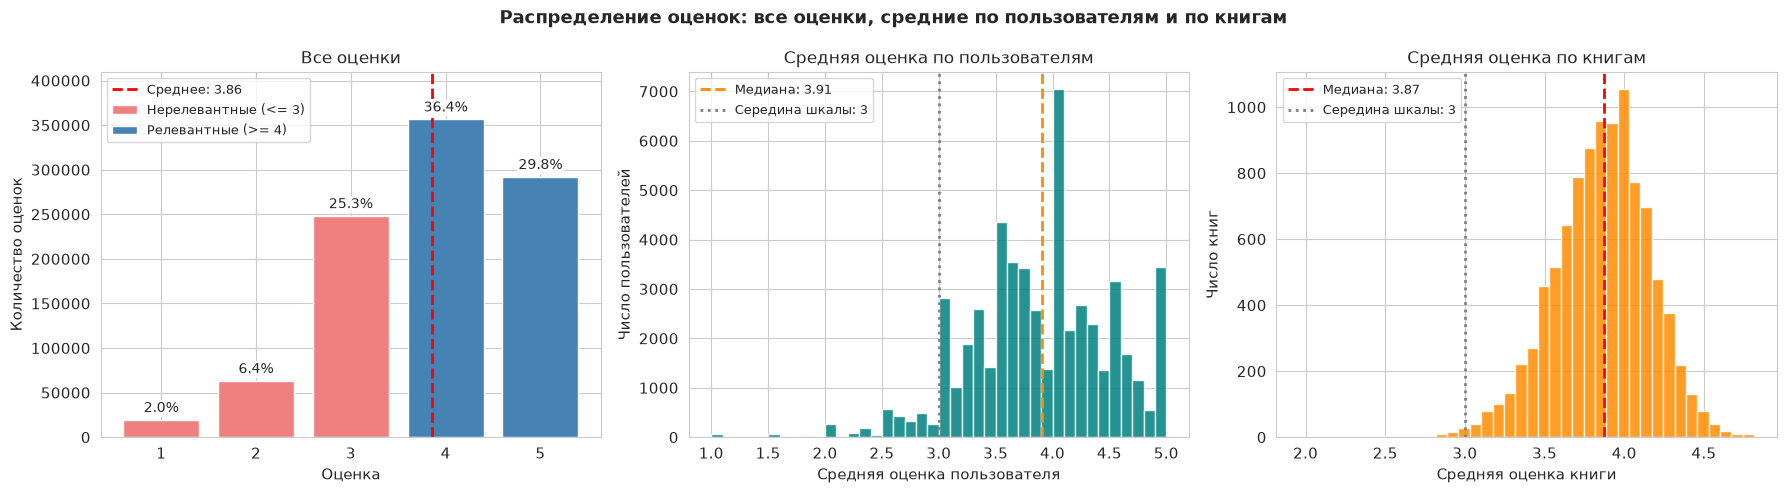

In [10]:
# Распределение оценок: все оценки, средние по пользователям и по книгам
RELEVANCE_THRESHOLD = 4    # предварительный порог релевантности, обоснование в выводе ниже

rating_counts = ratings['rating'].value_counts().sort_index()
rating_shares = rating_counts / rating_counts.sum() * 100

user_mean_rating = ratings.groupby('user_id')['rating'].mean()
book_mean_rating = ratings.groupby('book_id')['rating'].mean()

print("Распределение оценок:")
for rating_value in rating_counts.index:
    print(f"  {rating_value}: {rating_counts[rating_value]:>7} оценок ({rating_shares[rating_value]:.1f}%)")
print()

mean_rating = ratings['rating'].mean()
high_share = (ratings['rating'] >= RELEVANCE_THRESHOLD).mean() * 100
low_share = (ratings['rating'] <= 2).mean() * 100

print(f"Средняя оценка: {mean_rating:.3f}")
print(f"Медиана:        {ratings['rating'].median():.0f}")
print(f"Мода:           {ratings['rating'].mode()[0]}")
print(f"Асимметрия:     {ratings['rating'].skew():.3f}")
print()
print(f"Доля оценок 4 и 5: {high_share:.1f}%")
print(f"Доля оценок 1 и 2: {low_share:.1f}%")
print()
print(f"Медиана средней оценки пользователя:   {user_mean_rating.median():.2f}")
print(f"Пользователей со средней оценкой >= 4: {(user_mean_rating >= 4).mean() * 100:.1f}%")
print(f"Средняя оценка книги: 25% квантиль {book_mean_rating.quantile(0.25):.2f}, "
      f"75% квантиль {book_mean_rating.quantile(0.75):.2f}")
print(f"Книг со средней оценкой ниже 3:        {(book_mean_rating < 3).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Сколько раз поставлена каждая оценка. Цвет показывает порог релевантности
relevant_mask = rating_counts.index >= RELEVANCE_THRESHOLD
axes[0].bar(rating_counts.index[~relevant_mask], rating_counts.values[~relevant_mask],
            color='lightcoral', edgecolor='white', label='Нерелевантные (<= 3)')
axes[0].bar(rating_counts.index[relevant_mask], rating_counts.values[relevant_mask],
            color='steelblue', edgecolor='white', label='Релевантные (>= 4)')
for rating_value in rating_counts.index:
    # белый фон у подписи, чтобы её не перечёркивала линия среднего
    axes[0].text(rating_value, rating_counts[rating_value] + 5000,
                 f'{rating_shares[rating_value]:.1f}%', ha='center', va='bottom', fontsize=10,
                 bbox=dict(facecolor='white', edgecolor='none', pad=1))
axes[0].axvline(mean_rating, color='red', linestyle='--', linewidth=2,
                label=f'Среднее: {mean_rating:.2f}')
axes[0].set_ylim(0, rating_counts.max() * 1.15)
axes[0].set_xlabel('Оценка')
axes[0].set_ylabel('Количество оценок')
axes[0].set_title('Все оценки', fontsize=12)
axes[0].legend(fontsize=9, loc='upper left')

# 2. Средняя оценка каждого пользователя
axes[1].hist(user_mean_rating, bins=40, color='teal', edgecolor='white', alpha=0.85)
axes[1].axvline(user_mean_rating.median(), color='darkorange', linestyle='--', linewidth=2,
                label=f'Медиана: {user_mean_rating.median():.2f}')
axes[1].axvline(3, color='gray', linestyle=':', linewidth=2, label='Середина шкалы: 3')
axes[1].set_xlabel('Средняя оценка пользователя')
axes[1].set_ylabel('Число пользователей')
axes[1].set_title('Средняя оценка по пользователям', fontsize=12)
axes[1].legend(fontsize=9, loc='upper left')

# 3. Средняя оценка каждой книги
axes[2].hist(book_mean_rating, bins=40, color='darkorange', edgecolor='white', alpha=0.85)
axes[2].axvline(book_mean_rating.median(), color='red', linestyle='--', linewidth=2,
                label=f'Медиана: {book_mean_rating.median():.2f}')
axes[2].axvline(3, color='gray', linestyle=':', linewidth=2, label='Середина шкалы: 3')
axes[2].set_xlabel('Средняя оценка книги')
axes[2].set_ylabel('Число книг')
axes[2].set_title('Средняя оценка по книгам', fontsize=12)
axes[2].legend(fontsize=9, loc='upper left')

plt.suptitle('Распределение оценок: все оценки, средние по пользователям и по книгам',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_ratings_distribution.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Оценки заметно смещены в сторону высоких

- Самая частая оценка - **4 (36.4%)**, за ней **5 (29.8%)**. Вместе 4 и 5 дают **66.2%** всех оценок, а 1 и 2 только **8.4%**.
- Средняя оценка **3.86** при середине шкалы 3, медиана и мода равны 4. Асимметрия отрицательная (-0.62): основная масса справа, а хвост тянется к низким оценкам.
- Смещение видно и на уровне пользователей: медиана средней оценки пользователя 3.91, а **у 47.8% пользователей средняя оценка >= 4**. Пики на гистограмме в точках 3.0, 3.5, 4.0, 4.5 и 5.0 дают пользователи с 2-4 оценками.
- Средние по книгам лежат в узком диапазоне: у половины книг от 3.67 до 4.06. Книг со средней ниже 3 всего 64 из 10 000. Это ожидаемо, ведь в каталоге самые популярные книги Goodreads.

Почему так происходит: люди в основном читают и оценивают книги, которые выбрали сами и которые им заранее должны понравиться. Неинтересную книгу часто просто бросают и не оценивают. Это эффект самоотбора (selection bias), типичный для явного фидбека.

**Что это значит для моделей:**
- оценка 3 здесь скорее "нормально", чем "понравилось". **Порог релевантности беру `rating >= 4`**: в релевантные попадают 66% оценок, и это действительно положительная реакция.
- даже наивный прогноз "всем ставим среднее 3.86" даст не очень большую ошибку, поэтому RMSE модели SVD на этапе 4 нужно сравнивать с таким бейзлайном.
- отрицательных примеров мало, поэтому моделям будет сложнее учиться отличать книги, которые пользователю не понравятся.

### 1.4 Активность пользователей

Считаю, сколько оценок поставил каждый пользователь, и строю график "количество пользователей vs количество оценок": по оси X число оценок у пользователя, по оси Y сколько пользователей имеют столько оценок.

Для анализа ввожу два порога:
- **холодный старт** - меньше 5 оценок. По такой короткой истории сложно понять вкус человека.
- **активные пользователи** - 50 оценок и больше.

In [11]:
# Активность пользователей: сколько оценок поставил каждый
user_activity = ratings.groupby('user_id').size()

COLD_START_THRESHOLD = 5    # меньше 5 оценок - холодный старт
ACTIVE_THRESHOLD = 50       # 50 оценок и больше - активный пользователь

print("Число оценок на пользователя:")
print(user_activity.describe().round(1))
print()
print(f"90% квантиль: {user_activity.quantile(0.9):.0f} оценок")
print()

n_users = len(user_activity)
total_ratings = user_activity.sum()

cold_users = user_activity[user_activity < COLD_START_THRESHOLD]
active_users = user_activity[user_activity >= ACTIVE_THRESHOLD]

cold_users_share = len(cold_users) / n_users * 100
cold_ratings_share = cold_users.sum() / total_ratings * 100
active_users_share = len(active_users) / n_users * 100
active_ratings_share = active_users.sum() / total_ratings * 100

print(f"Холодный старт (< {COLD_START_THRESHOLD} оценок): {len(cold_users):>6} пользователей "
      f"({cold_users_share:.1f}% пользователей, {cold_ratings_share:.1f}% оценок)")
print(f"Активные (>= {ACTIVE_THRESHOLD} оценок):     {len(active_users):>6} пользователей "
      f"({active_users_share:.1f}% пользователей, {active_ratings_share:.1f}% оценок)")
print(f"Пользователей ровно с 1 оценкой: {(user_activity == 1).sum()}")
print()

# Группы пользователей по активности: какая доля пользователей и какая доля оценок в каждой
activity_bins = [0, 4, 9, 19, 49, 99, 200]
activity_labels = ['1-4', '5-9', '10-19', '20-49', '50-99', '100-200']
user_groups = pd.cut(user_activity, bins=activity_bins, labels=activity_labels)

groups_table = pd.DataFrame({
    'Пользователей': user_groups.value_counts().sort_index(),
    'Оценок': user_activity.groupby(user_groups, observed=False).sum(),
})
groups_table['Доля пользователей, %'] = (groups_table['Пользователей'] / n_users * 100).round(1)
groups_table['Доля оценок, %'] = (groups_table['Оценок'] / total_ratings * 100).round(1)
groups_table.index.name = 'Оценок у пользователя'

print("Группы пользователей по активности:")
display(groups_table)

Число оценок на пользователя:
count    53424.0
mean        18.3
std         26.2
min          1.0
25%          3.0
50%          8.0
75%         22.0
max        200.0
dtype: float64

90% квантиль: 47 оценок

Холодный старт (< 5 оценок):  17765 пользователей (33.3% пользователей, 5.0% оценок)
Активные (>= 50 оценок):       4908 пользователей (9.2% пользователей, 42.8% оценок)
Пользователей ровно с 1 оценкой: 42

Группы пользователей по активности:


,Пользователей,Оценок,"Доля пользователей, %","Доля оценок, %"
Оценок у пользователя,,,,
1-4,17765,48873,33.3,5.0
5-9,11285,75215,21.1,7.7
10-19,9762,135178,18.3,13.8
20-49,9704,300912,18.2,30.7
50-99,3714,254128,7.0,25.9
100-200,1194,165172,2.2,16.9


Перекос виден уже в цифрах. Посмотрю на него на графиках: слева распределение пользователей по числу оценок, справа вклад каждой группы активности в общее число оценок.

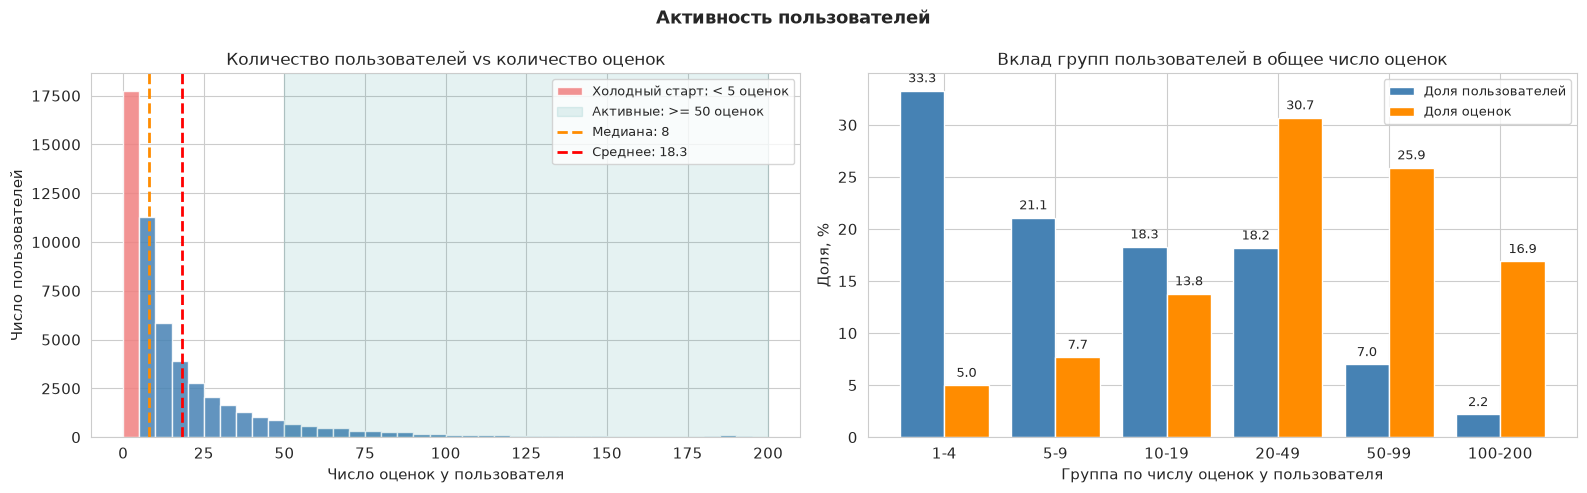

In [12]:
# Графики активности пользователей
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Сколько пользователей поставили данное число оценок (шаг 5 оценок)
counts, bin_edges, patches = axes[0].hist(user_activity, bins=range(0, 205, 5),
                                          color='steelblue', edgecolor='white', alpha=0.85)
# Первый столбец (1-4 оценки) - это как раз зона холодного старта
patches[0].set_facecolor('lightcoral')
patches[0].set_label(f'Холодный старт: < {COLD_START_THRESHOLD} оценок')
axes[0].axvspan(ACTIVE_THRESHOLD, 200, color='teal', alpha=0.1,
                label=f'Активные: >= {ACTIVE_THRESHOLD} оценок')
axes[0].axvline(user_activity.median(), color='darkorange', linestyle='--', linewidth=2,
                label=f'Медиана: {user_activity.median():.0f}')
axes[0].axvline(user_activity.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Среднее: {user_activity.mean():.1f}')
axes[0].set_xlabel('Число оценок у пользователя')
axes[0].set_ylabel('Число пользователей')
axes[0].set_title('Количество пользователей vs количество оценок', fontsize=12)
axes[0].legend(fontsize=9)

# 2. Доля пользователей и доля оценок в каждой группе активности
x_positions = np.arange(len(activity_labels))
bar_width = 0.4
axes[1].bar(x_positions - bar_width / 2, groups_table['Доля пользователей, %'], width=bar_width,
            color='steelblue', edgecolor='white', label='Доля пользователей')
axes[1].bar(x_positions + bar_width / 2, groups_table['Доля оценок, %'], width=bar_width,
            color='darkorange', edgecolor='white', label='Доля оценок')
for i in range(len(activity_labels)):
    users_value = groups_table['Доля пользователей, %'].iloc[i]
    ratings_value = groups_table['Доля оценок, %'].iloc[i]
    axes[1].text(x_positions[i] - bar_width / 2, users_value + 0.5, f'{users_value:.1f}',
                 ha='center', va='bottom', fontsize=9)
    axes[1].text(x_positions[i] + bar_width / 2, ratings_value + 0.5, f'{ratings_value:.1f}',
                 ha='center', va='bottom', fontsize=9)
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(activity_labels)
axes[1].set_xlabel('Группа по числу оценок у пользователя')
axes[1].set_ylabel('Доля, %')
axes[1].set_title('Вклад групп пользователей в общее число оценок', fontsize=12)
axes[1].legend(fontsize=9)

plt.suptitle('Активность пользователей', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_user_activity.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Активность пользователей очень неравномерная: у трети пользователей почти нет истории

- Медиана - **8 оценок** на пользователя, а среднее 18.3: распределение с длинным правым хвостом. Половина пользователей оценила не больше 8 книг.
- **33.3% пользователей поставили меньше 5 оценок**, и на них приходится всего **5.0% оценок**. Это зона холодного старта: по 1-4 книгам вкус человека не понять, и коллаборативные модели будут для таких пользователей ошибаться. У 42 пользователей после удаления дубликатов вообще осталась одна оценка.
- **Активные пользователи (50+ оценок) - это 9.2% пользователей, но 42.8% всех оценок.** Порог 50 близок к 90% квантилю (47 оценок), то есть это примерно 10% самых активных. Группа 100-200 оценок - всего 2.2% пользователей и 16.9% оценок.
- На правом графике хорошо видно, как меняется картина: в левых группах доля пользователей намного больше доли оценок, в правых - наоборот.

**Вывод:** модели будут учиться в основном на оценках активных пользователей, а рекомендации нужны всем. Для пользователей с короткой историей персональные модели будут работать хуже, поэтому им нужен запасной вариант - рекомендации по популярности. Это пойдёт в гибридную схему на этапе 6.

### 1.5 Популярность книг

Теперь то же самое для книг. По заданию строю график "количество книг vs количество оценок" и ищу популярные книги и "длинный хвост" - большую массу книг, у которых мало оценок. Начинаю с оценок из `ratings.csv`.

Число оценок на книгу в ratings.csv:
count    10000.0
mean        97.9
std          5.8
min          8.0
25%         99.0
50%        100.0
75%        100.0
max        100.0
dtype: float64

Книг ровно со 100 оценками:     6248 (62.5%)
Книг ровно с 99 оценками:       1620 (16.2%)
Книг с 90 и более оценками:     9431 (94.3%)
Книг меньше чем с 50 оценками:  10
Книг больше чем со 100 оценками: 0


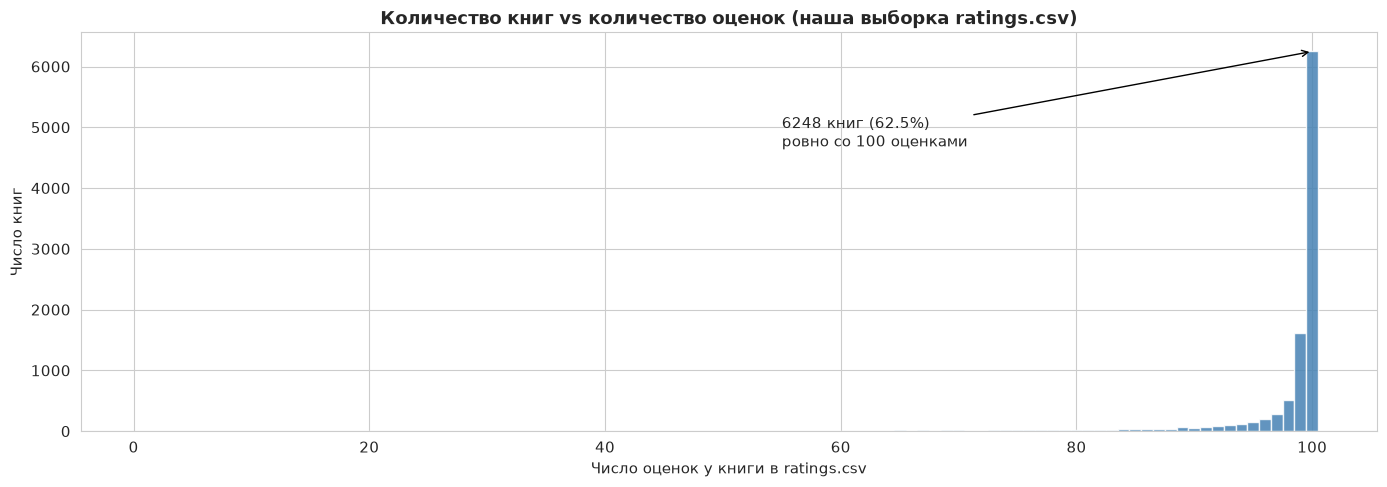

In [13]:
# Число оценок у каждой книги в ratings.csv
book_activity = ratings.groupby('book_id').size()

print("Число оценок на книгу в ratings.csv:")
print(book_activity.describe().round(1))
print()

n_books = len(book_activity)
n_books_100 = (book_activity == 100).sum()
n_books_99 = (book_activity == 99).sum()
print(f"Книг ровно со 100 оценками:     {n_books_100} ({n_books_100 / n_books * 100:.1f}%)")
print(f"Книг ровно с 99 оценками:       {n_books_99} ({n_books_99 / n_books * 100:.1f}%)")
print(f"Книг с 90 и более оценками:     {(book_activity >= 90).sum()} ({(book_activity >= 90).mean() * 100:.1f}%)")
print(f"Книг меньше чем с 50 оценками:  {(book_activity < 50).sum()}")
print(f"Книг больше чем со 100 оценками: {(book_activity > 100).sum()}")

fig, ax = plt.subplots(figsize=(14, 5))
# Границы столбцов на половинках, чтобы каждый столбец стоял ровно над своим числом оценок
ax.hist(book_activity, bins=np.arange(0.5, 101.5, 1), color='steelblue', edgecolor='white', alpha=0.85)
ax.annotate(f'{n_books_100} книг ({n_books_100 / n_books * 100:.1f}%)\nровно со 100 оценками',
            xy=(100, n_books_100), xytext=(55, n_books_100 * 0.75),
            fontsize=11, arrowprops=dict(arrowstyle='->', color='black'))
ax.set_xlabel('Число оценок у книги в ratings.csv')
ax.set_ylabel('Число книг')
ax.set_title('Количество книг vs количество оценок (наша выборка ratings.csv)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_book_popularity_sample.png'), dpi=100, bbox_inches='tight')
plt.show()

#### В нашей выборке у книги не больше 100 оценок, поэтому длинного хвоста здесь не видно

- **62.5% книг имеют ровно 100 оценок**, ещё 16.2% - ровно 99. Больше 100 оценок нет ни у одной книги, меньше 50 - всего у 10 книг.
- Это не свойство реального мира, а особенность версии датасета. Полная версия Goodbooks-10k на GitHub содержит около 6 млн оценок, а версия с Kaggle, с которой я работаю, урезана примерно до 1 млн: на каждую книгу оставлено не больше 100 оценок.
- Из-за этого популярность книг внутри `ratings.csv` почти одинаковая, и длинный хвост по этому файлу увидеть нельзя.

**Решение:** реальную популярность книг смотрю по колонке `books.ratings_count` - это число оценок основного издания книги на Goodreads. Она не зависит от урезанной выборки и показывает настоящую картину. Значения отличаются в сотни раз, поэтому на графиках беру логарифмическую шкалу.

Число оценок книги на Goodreads (ratings_count):
count      10000.0
mean       54001.0
std       157370.0
min         2716.0
25%        13569.0
50%        21156.0
75%        41054.0
max      4780653.0
Name: ratings_count, dtype: float64

Самая популярная книга популярнее медианной в 226 раз

Топ-1% книг (100 шт.) собирают 23.4% всех оценок
Топ-10% книг (1000 шт.) собирают 57.1% всех оценок
Топ-20% книг (2000 шт.) собирают 69.6% всех оценок
Топ-50% книг (5000 шт.) собирают 87.2% всех оценок


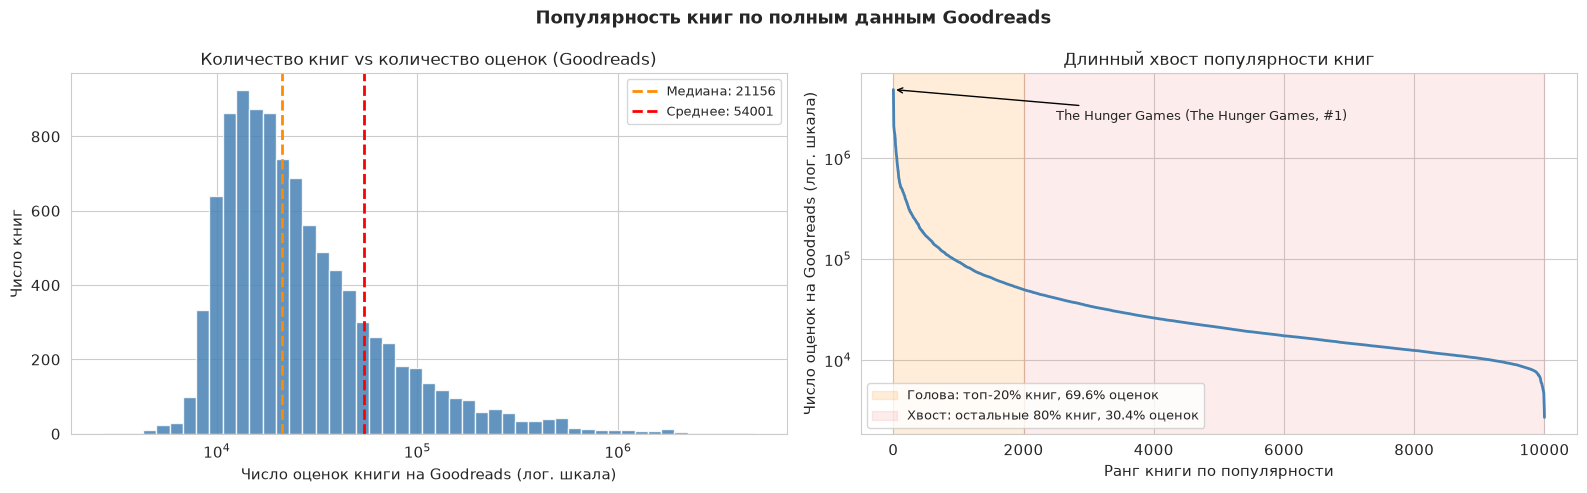

In [14]:
# Реальная популярность книг по данным Goodreads: books.ratings_count
popularity = books['ratings_count'].sort_values(ascending=False).reset_index(drop=True)
total_goodreads_ratings = popularity.sum()

print("Число оценок книги на Goodreads (ratings_count):")
print(popularity.describe().round(0))
print()
print(f"Самая популярная книга популярнее медианной в {popularity.max() / popularity.median():.0f} раз")
print()

# Какую долю всех оценок собирают самые популярные книги
head_shares = {}
for top_share in [0.01, 0.10, 0.20, 0.50]:
    n_top_books = int(len(popularity) * top_share)
    collected_share = popularity.iloc[:n_top_books].sum() / total_goodreads_ratings * 100
    head_shares[top_share] = collected_share
    print(f"Топ-{top_share * 100:.0f}% книг ({n_top_books} шт.) собирают {collected_share:.1f}% всех оценок")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Сколько книг имеют данное число оценок. Шкала по X логарифмическая, иначе всё сожмётся у нуля
log_bins = np.logspace(np.log10(popularity.min()), np.log10(popularity.max()), 50)
axes[0].hist(popularity, bins=log_bins, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_xscale('log')
axes[0].axvline(popularity.median(), color='darkorange', linestyle='--', linewidth=2,
                label=f'Медиана: {popularity.median():.0f}')
axes[0].axvline(popularity.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Среднее: {popularity.mean():.0f}')
axes[0].set_xlabel('Число оценок книги на Goodreads (лог. шкала)')
axes[0].set_ylabel('Число книг')
axes[0].set_title('Количество книг vs количество оценок (Goodreads)', fontsize=12)
axes[0].legend(fontsize=9)

# 2. Ранговый график: книги отсортированы по убыванию популярности
ranks = np.arange(1, len(popularity) + 1)
n_head_books = int(len(popularity) * 0.2)
axes[1].plot(ranks, popularity.values, color='steelblue', linewidth=2)
axes[1].axvspan(1, n_head_books, color='darkorange', alpha=0.15,
                label=f'Голова: топ-20% книг, {head_shares[0.20]:.1f}% оценок')
axes[1].axvspan(n_head_books, len(popularity), color='lightcoral', alpha=0.15,
                label=f'Хвост: остальные 80% книг, {100 - head_shares[0.20]:.1f}% оценок')
axes[1].set_yscale('log')
top_book_title = books.sort_values('ratings_count', ascending=False)['title'].iloc[0]
axes[1].annotate(top_book_title, xy=(1, popularity.iloc[0]), xytext=(2500, popularity.iloc[0] * 0.5),
                 fontsize=9, arrowprops=dict(arrowstyle='->', color='black'))
axes[1].set_xlabel('Ранг книги по популярности')
axes[1].set_ylabel('Число оценок на Goodreads (лог. шкала)')
axes[1].set_title('Длинный хвост популярности книг', fontsize=12)
axes[1].legend(fontsize=9, loc='lower left')

plt.suptitle('Популярность книг по полным данным Goodreads', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_book_popularity_goodreads.png'), dpi=100, bbox_inches='tight')
plt.show()

Посмотрю, какие книги находятся в голове распределения. Заодно проверю, связано ли то, что у книги в нашей выборке меньше 100 оценок, с её реальной популярностью.

In [15]:
# Самые популярные книги на Goodreads
top_columns = ['id', 'title', 'authors', 'original_publication_year', 'average_rating', 'ratings_count']
print("Топ-10 книг по числу оценок на Goodreads:")
display(books.sort_values('ratings_count', ascending=False)[top_columns].head(10))

# Неполная выборка (меньше 100 оценок в ratings.csv) и реальная популярность
books_indexed = books.set_index('id')
books_indexed['n_ratings_sample'] = book_activity

full_sample = books_indexed[books_indexed['n_ratings_sample'] == 100]
partial_sample = books_indexed[books_indexed['n_ratings_sample'] < 100]
print(f"Медиана ratings_count у книг со 100 оценками в выборке:   {full_sample['ratings_count'].median():.0f}")
print(f"Медиана ratings_count у книг с < 100 оценками в выборке: {partial_sample['ratings_count'].median():.0f}")
print()

print("Книги с наименьшим числом оценок в ratings.csv:")
display(books_indexed.sort_values('n_ratings_sample')[['title', 'authors', 'ratings_count', 'n_ratings_sample']].head(5))

Топ-10 книг по числу оценок на Goodreads:


,id,title,authors,original_publication_year,average_rating,ratings_count
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,2008.0,4.34,4780653
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",1997.0,4.44,4602479
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,2005.0,3.57,3866839
3,4,To Kill a Mockingbird,Harper Lee,1960.0,4.25,3198671
4,5,The Great Gatsby,F. Scott Fitzgerald,1925.0,3.89,2683664
5,6,The Fault in Our Stars,John Green,2012.0,4.26,2346404
6,7,The Hobbit,J.R.R. Tolkien,1937.0,4.25,2071616
7,8,The Catcher in the Rye,J.D. Salinger,1951.0,3.79,2044241
9,10,Pride and Prejudice,Jane Austen,1813.0,4.24,2035490
8,9,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2000.0,3.85,2001311


Медиана ratings_count у книг со 100 оценками в выборке:   28002
Медиана ratings_count у книг с < 100 оценками в выборке: 14108

Книги с наименьшим числом оценок в ratings.csv:


,title,authors,ratings_count,n_ratings_sample
id,,,,
7803,Kindle User's Guide,Amazon,3508,8
9345,Diary ng Panget,"HaveYouSeenThisGirL, Jan Irene Villar",7016,11
9486,Fifty Shades Duo: Fifty Shades Darker / Fifty ...,E.L. James,8227,24
1935,Kindle Paperwhite User's Guide,Amazon,15002,33
9315,The King's Agent,Donna Russo Morin,8250,36


#### Реальная популярность книг устроена как длинный хвост

- Самая популярная книга (**The Hunger Games**, 4.78 млн оценок) популярнее медианной (21 тыс. оценок) примерно **в 226 раз**.
- **Топ-1% книг (100 штук) собирает 23.4% всех оценок**, топ-10% - 57.1%, топ-20% - 69.6%. Остальные 80% книг делят между собой около 30% оценок. Это и есть длинный хвост.
- В голове распределения - бестселлеры и школьная классика: The Hunger Games, Harry Potter, Twilight, To Kill a Mockingbird, The Great Gatsby.
- При этом сам датасет собран из 10 000 самых популярных книг Goodreads. То есть реальный хвост ещё длиннее, а в нашем каталоге только голова и начало хвоста.
- Книги, у которых в нашей выборке меньше 100 оценок, в среднем менее популярны: медиана 14 тыс. оценок на Goodreads против 28 тыс. у книг со 100 оценками. Даже в урезанных данных хвост немного проявляется.
- В каталоге попадаются и не книги вовсе: меньше всего оценок у Kindle User's Guide (8 штук) и Kindle Paperwhite User's Guide.

**Вывод для моделей:** в реальном сервисе модель по популярности и коллаборативные модели тянули бы рекомендации в голову распределения (popularity bias), а книги из хвоста почти не попадали бы в выдачу. В нашей выборке это смещение со стороны книг искусственно сглажено ограничением в 100 оценок на книгу. Это нужно помнить при интерпретации результатов на этапе 5.

### 1.6 Самые частые теги

Теги в Goodbooks-10k - это "полки" Goodreads, на которые пользователи складывают книги. Присоединяю к `book_tags` названия тегов и считаю для каждого тега суммарный `count` по всем книгам, то есть сколько раз тег поставлен всего. Отдельно считаю, у скольких книг этот тег есть.

In [16]:
# Присоединяем названия тегов и считаем, сколько раз каждый тег поставлен всего
book_tags_named = book_tags.merge(tags, on='tag_id', how='left')

tag_popularity = book_tags_named.groupby('tag_name')['count'].sum().sort_values(ascending=False)
tag_n_books = book_tags_named.groupby('tag_name')['goodreads_book_id'].nunique()
tags_per_book = book_tags.groupby('goodreads_book_id').size()

print(f"Разных тегов в book_tags: {len(tag_popularity)}")
print(f"Тегов на одну книгу: в среднем {tags_per_book.mean():.1f}, "
      f"минимум {tags_per_book.min()}, максимум {tags_per_book.max()}")
print()
print(f"{'Тег':<22} {'Сумма count':>14} {'Книг с тегом':>14}")
print('-' * 52)
for tag_name in tag_popularity.head(20).index:
    print(f"{tag_name:<22} {tag_popularity[tag_name]:>14} {tag_n_books[tag_name]:>14}")

Разных тегов в book_tags: 34250
Тегов на одну книгу: в среднем 100.0, минимум 55, максимум 100

Тег                       Сумма count   Книг с тегом
----------------------------------------------------
to-read                     140718761           9983
currently-reading             7507958           9776
favorites                     4503173           9881
fiction                       3688819           9097
fantasy                       3548157           4259
young-adult                   1848306           3630
classics                      1756920           2785
books-i-own                   1317235           9799
romance                       1231926           4251
owned                         1218214           9857
ya                             898334           2842
mystery                        872282           3686
non-fiction                    857901           2128
historical-fiction             815421           2590
series                         782637           5080
sci

В топе много тегов, которые описывают не саму книгу, а действия пользователя с ней: `to-read` (хочу прочитать), `currently-reading`, `owned`, `kindle` и т.д. Составляю список таких служебных тегов вручную по топ-150 самых частых тегов и строю два графика: топ всех тегов (служебные выделены цветом) и топ содержательных тегов. Заодно проверяю, насколько часто синонимичные теги стоят у одних и тех же книг.

Служебных тегов в списке:           50
Доля служебных тегов в сумме count: 78.2%
Из них только 'to-read':            67.4%

Книг с тегом 'ya': 2842, из них есть и 'young-adult': 97.8%. Обратно: книг с 'young-adult': 3630, из них есть и 'ya': 76.6%


Книг с тегом 'sci-fi': 2227, из них есть и 'science-fiction': 88.8%. Обратно: книг с 'science-fiction': 2222, из них есть и 'sci-fi': 89.0%


Книг с тегом 'nonfiction': 1833, из них есть и 'non-fiction': 98.6%. Обратно: книг с 'non-fiction': 2128, из них есть и 'nonfiction': 85.0%
Книг с тегом 'classic': 1939, из них есть и 'classics': 96.9%. Обратно: книг с 'classics': 2785, из них есть и 'classic': 67.5%


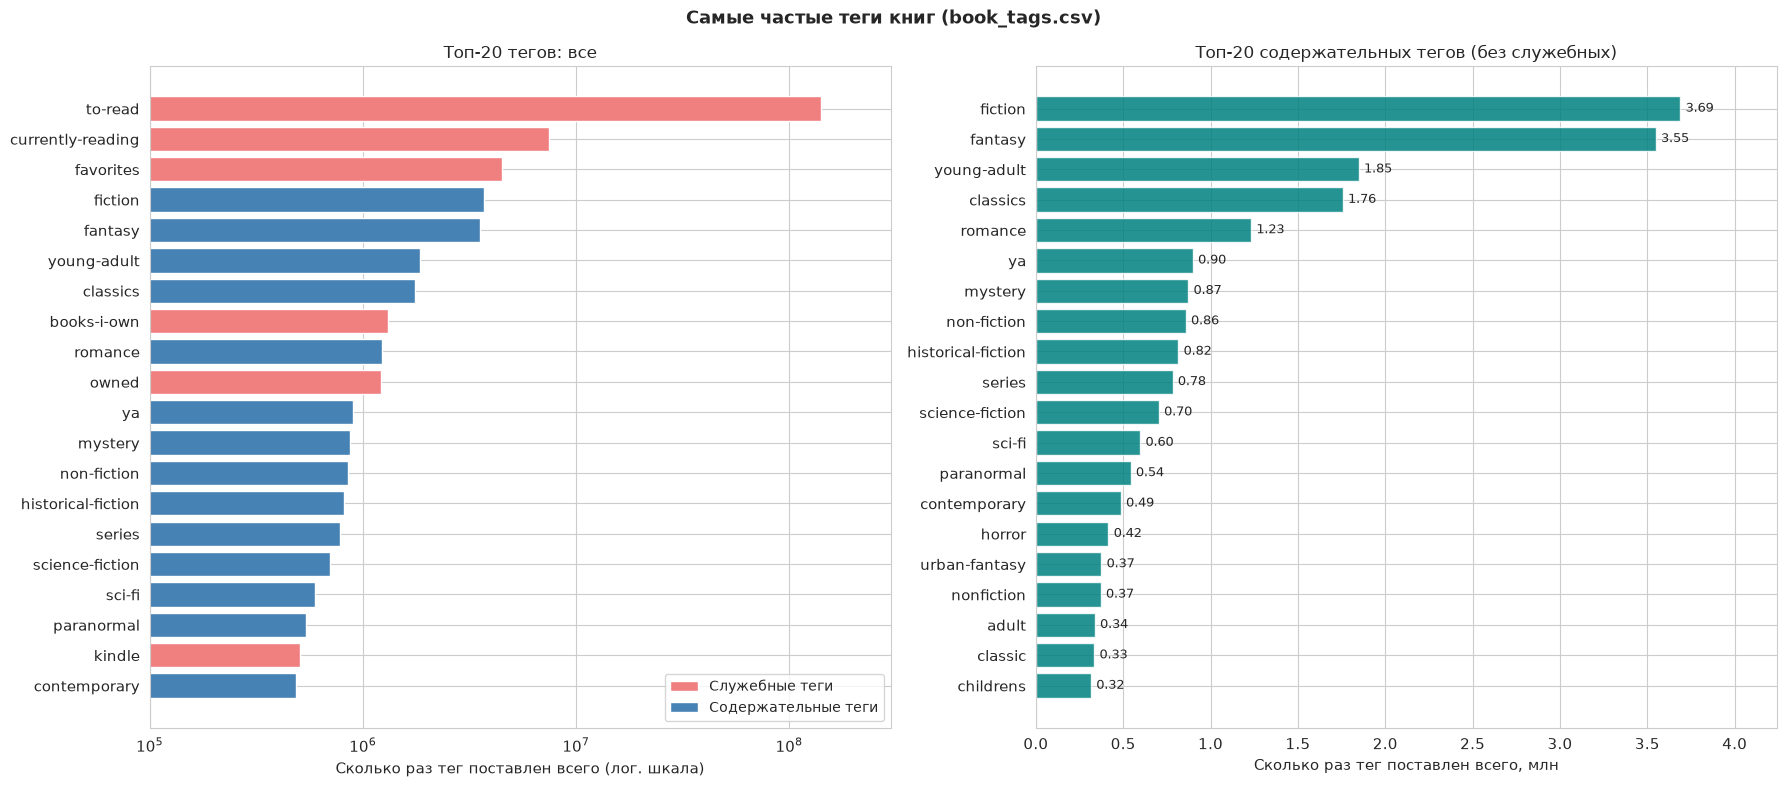

In [17]:
# Служебные теги (полки Goodreads), которые не описывают содержание книги.
# Список составлен вручную по топ-150 самых частых тегов
SERVICE_TAGS = [
    # статус чтения
    'to-read', 'currently-reading', 're-read', 'dnf', 'did-not-finish', 'abandoned', 'maybe',
    'read-in-2011', 'read-in-2012', 'read-in-2013', 'read-in-2014', 'read-in-2015',
    'read-in-2016', 'read-in-2017', 'read-2014', 'read-2015', 'read-2016',
    # владение книгой и личная библиотека
    'owned', 'books-i-own', 'owned-books', 'i-own', 'own-it', 'have', 'my-books',
    'my-library', 'library', 'borrowed', 'to-buy', 'wish-list', 'default', 'books',
    # формат издания
    'kindle', 'ebook', 'ebooks', 'e-book', 'e-books',
    'audiobook', 'audiobooks', 'audio', 'audible', 'audio-book', 'audio-books',
    # личные списки и книжные клубы
    'favorites', 'favourites', 'favorite', 'favorite-books', 'all-time-favorites',
    '5-stars', 'book-club', 'bookclub',
]

is_service = tag_popularity.index.isin(SERVICE_TAGS)
service_share = tag_popularity[is_service].sum() / tag_popularity.sum() * 100
to_read_share = tag_popularity['to-read'] / tag_popularity.sum() * 100

print(f"Служебных тегов в списке:           {len(SERVICE_TAGS)}")
print(f"Доля служебных тегов в сумме count: {service_share:.1f}%")
print(f"Из них только 'to-read':            {to_read_share:.1f}%")
print()

# Синонимы: как часто у книги с одним вариантом тега есть и второй (проверяю в обе стороны)
synonym_pairs = [('ya', 'young-adult'), ('sci-fi', 'science-fiction'),
                 ('nonfiction', 'non-fiction'), ('classic', 'classics')]
for first_tag, second_tag in synonym_pairs:
    books_first = set(book_tags_named.loc[book_tags_named['tag_name'] == first_tag, 'goodreads_book_id'])
    books_second = set(book_tags_named.loc[book_tags_named['tag_name'] == second_tag, 'goodreads_book_id'])
    n_both = len(books_first & books_second)
    first_with_second = n_both / len(books_first) * 100
    second_with_first = n_both / len(books_second) * 100
    print(f"Книг с тегом '{first_tag}': {len(books_first)}, из них есть и '{second_tag}': {first_with_second:.1f}%. "
          f"Обратно: книг с '{second_tag}': {len(books_second)}, из них есть и '{first_tag}': {second_with_first:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# 1. Топ-20 всех тегов, служебные выделены цветом.
# Шкала по X логарифмическая: to-read на порядок больше остальных тегов
top_all = tag_popularity.head(20)
positions = np.arange(len(top_all))[::-1]      # самый частый тег сверху
service_mask = top_all.index.isin(SERVICE_TAGS)
axes[0].barh(positions[service_mask], top_all.values[service_mask],
             color='lightcoral', edgecolor='white', label='Служебные теги')
axes[0].barh(positions[~service_mask], top_all.values[~service_mask],
             color='steelblue', edgecolor='white', label='Содержательные теги')
axes[0].set_yticks(positions)
axes[0].set_yticklabels(top_all.index)
axes[0].set_xscale('log')
axes[0].set_xlim(1e5, 3e8)
axes[0].set_xlabel('Сколько раз тег поставлен всего (лог. шкала)')
axes[0].set_title('Топ-20 тегов: все', fontsize=12)
axes[0].legend(fontsize=10, loc='lower right')

# 2. Топ-20 содержательных тегов после удаления служебных (в миллионах)
top_content = tag_popularity[~is_service].head(20)
content_values_mln = top_content.values / 1e6
positions = np.arange(len(top_content))[::-1]
axes[1].barh(positions, content_values_mln, color='teal', edgecolor='white', alpha=0.85)
for i in range(len(top_content)):
    axes[1].text(content_values_mln[i] + 0.03, positions[i], f'{content_values_mln[i]:.2f}',
                 va='center', fontsize=9)
axes[1].set_yticks(positions)
axes[1].set_yticklabels(top_content.index)
axes[1].set_xlim(0, content_values_mln.max() * 1.15)
axes[1].set_xlabel('Сколько раз тег поставлен всего, млн')
axes[1].set_title('Топ-20 содержательных тегов (без служебных)', fontsize=12)

plt.suptitle('Самые частые теги книг (book_tags.csv)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_top_tags.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Чаще всего встречаются служебные теги, а жанровый сигнал идёт после них

- **`to-read` - абсолютный лидер: 67.4% всей суммы `count`**. Это не жанр, а полка "хочу прочитать", и она есть почти у каждой книги (9 983 из 10 000).
- Все служебные теги из списка (статус чтения, владение книгой, формат, избранное) вместе дают **78.2%** суммарного `count`. Содержание книги они не описывают, а `to-read`, `favorites` и `owned` стоят почти у всех книг, так что и различать книги они не помогают.
- После их удаления остаются осмысленные жанры: **fiction, fantasy, young-adult, classics, romance, mystery, non-fiction, historical-fiction**. Каталог в основном художественный, с заметным перекосом в фэнтези и young adult.
- Среди тегов много синонимов: `ya` и `young-adult`, `sci-fi` и `science-fiction`, `nonfiction` и `non-fiction`, `classic` и `classics`. Обычно редкий вариант стоит вместе с частым: у 97.8% книг с тегом `ya` есть и `young-adult`. Но в обратную сторону совпадение слабее: `ya` есть только у 76.6% книг с `young-adult`, а `classic` - у 67.5% книг с `classics`. Плюс в справочнике есть мусорные названия вроде `-` и `--1-`.

**Решение для контентной модели (этап 2):** в профиль книги беру только содержательные теги, служебные убираю по списку `SERVICE_TAGS`. Синонимы вручную не объединяю: жанр всё равно попадает в профиль через более частый вариант. Но у книг с обоими вариантами жанр учитывается дважды, поэтому объединение синонимов - одно из улучшений (п. 6.2).

### 1.7 Разреженность матрицы пользователь x книга

Модели на этапах 3-4 работают с матрицей взаимодействий "пользователь x книга". Считаю, какая доля её ячеек заполнена, и сравниваю, сколько памяти заняла бы обычная плотная матрица и разреженная `csr_matrix`, которая хранит только заполненные ячейки.

Ещё одна полезная оценка - сколько в среднем общих читателей у двух случайных книг. Пользователь с `d` оценками даёт `d * (d - 1)` упорядоченных пар книг, которые он оценил обе. Если сложить это по всем пользователям и поделить на число упорядоченных пар книг, получится среднее число общих читателей у пары.

Размер матрицы:   53424 x 10000 = 534240000 ячеек
Заполнено ячеек:  979478
Плотность:        0.183%
Разреженность:    99.817%
В среднем пользователь оценил 18.3 книг из 10000
Среднее число общих читателей у двух случайных книг: 0.54

csr_matrix: размер (53424, 10000), ненулевых элементов 979478
Плотная матрица (float32):   2038.0 МБ
Разреженная csr_matrix:         7.7 МБ
Разница:                   в 265 раз

Во фрагменте 300 x 300 заполнено 174 ячеек из 90000


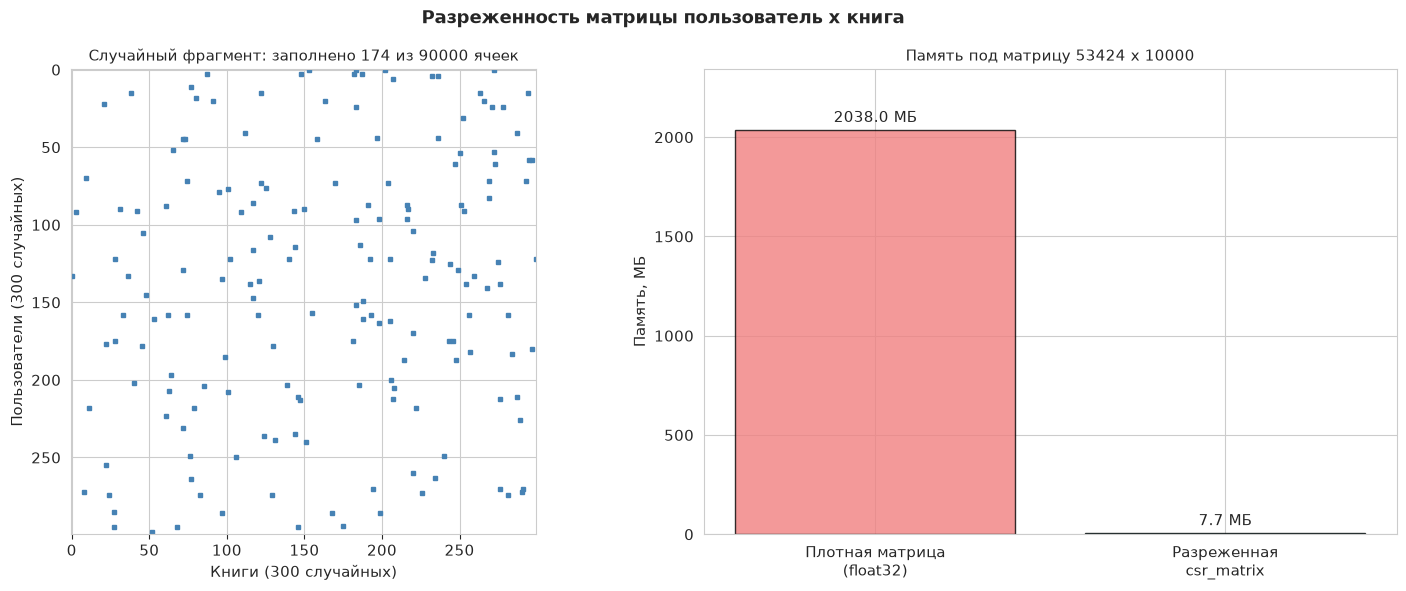

In [18]:
# Плотность матрицы взаимодействий пользователь x книга
n_ratings = len(ratings)
n_cells = n_users * n_books
density = n_ratings / n_cells

print(f"Размер матрицы:   {n_users} x {n_books} = {n_cells} ячеек")
print(f"Заполнено ячеек:  {n_ratings}")
print(f"Плотность:        {density * 100:.3f}%")
print(f"Разреженность:    {(1 - density) * 100:.3f}%")
print(f"В среднем пользователь оценил {n_ratings / n_users:.1f} книг из {n_books}")

# Среднее число общих читателей у случайной пары книг
pairs_from_users = (user_activity * (user_activity - 1)).sum()
mean_common_readers = pairs_from_users / (n_books * (n_books - 1))
print(f"Среднее число общих читателей у двух случайных книг: {mean_common_readers:.2f}")
print()

# Строим разреженную матрицу по всем оценкам, чтобы сравнить расход памяти.
# id пользователей и книг идут подряд с 1, поэтому строка = user_id - 1, столбец = book_id - 1
row_index = ratings['user_id'].values - 1
col_index = ratings['book_id'].values - 1
rating_values = ratings['rating'].values.astype(np.float32)
full_matrix = csr_matrix((rating_values, (row_index, col_index)), shape=(n_users, n_books))

dense_memory_mb = n_users * n_books * 4 / 1024 / 1024      # float32 занимает 4 байта
sparse_memory_mb = (full_matrix.data.nbytes + full_matrix.indices.nbytes
                    + full_matrix.indptr.nbytes) / 1024 / 1024

print(f"csr_matrix: размер {full_matrix.shape}, ненулевых элементов {full_matrix.nnz}")
print(f"Плотная матрица (float32): {dense_memory_mb:>8.1f} МБ")
print(f"Разреженная csr_matrix:    {sparse_memory_mb:>8.1f} МБ")
print(f"Разница:                   в {dense_memory_mb / sparse_memory_mb:.0f} раз")
print()

# Случайный фрагмент 300 x 300 для наглядности
rng = np.random.default_rng(RANDOM_STATE)
sample_users = rng.choice(n_users, size=300, replace=False)
sample_books = rng.choice(n_books, size=300, replace=False)
fragment = full_matrix[sample_users][:, sample_books]
print(f"Во фрагменте 300 x 300 заполнено {fragment.nnz} ячеек из {300 * 300}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Заполненные ячейки случайного фрагмента матрицы
axes[0].spy(fragment, markersize=3, color='steelblue')
axes[0].xaxis.tick_bottom()      # spy ставит подписи делений сверху, переношу их вниз к названию оси
axes[0].set_xlabel('Книги (300 случайных)')
axes[0].set_ylabel('Пользователи (300 случайных)')
axes[0].set_title(f'Случайный фрагмент: заполнено {fragment.nnz} из {300 * 300} ячеек', fontsize=11)

# 2. Сколько памяти занимает матрица в плотном и разреженном виде
memory_labels = ['Плотная матрица\n(float32)', 'Разреженная\ncsr_matrix']
memory_values = [dense_memory_mb, sparse_memory_mb]
bars = axes[1].bar(memory_labels, memory_values, color=['lightcoral', 'teal'],
                   edgecolor='black', alpha=0.8)
for bar, value in zip(bars, memory_values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20, f'{value:.1f} МБ',
                 ha='center', va='bottom', fontsize=11)
axes[1].set_ylim(0, dense_memory_mb * 1.15)
axes[1].set_ylabel('Память, МБ')
axes[1].set_title(f'Память под матрицу {n_users} x {n_books}', fontsize=11)

plt.suptitle('Разреженность матрицы пользователь x книга', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_sparsity.png'), dpi=100, bbox_inches='tight')
plt.show()

#### Матрица заполнена на 0.18% - это главная проблема данных

- Из 534 млн ячеек заполнено меньше 1 млн: **плотность 0.183%, разреженность 99.817%**. В среднем пользователь оценил 18 книг из 10 000.
- **У двух случайных книг в среднем всего 0.54 общих читателя.** То есть у большинства пар книг общих читателей нет вообще.
- В случайном фрагменте 300 x 300 заполнено 174 ячейки из 90 000 - на картинке это редкие отдельные точки.
- Плотная матрица заняла бы около **2 ГБ** даже во float32, а разреженная `csr_matrix` - **7.7 МБ**, примерно в 265 раз меньше.

**Что это значит:**
- схожесть книг в Item-based CF будет считаться по очень маленьким пересечениям читателей и будет шумной. Для многих пар книг посчитать её вообще не получится.
- для большинства пар (пользователь, книга) модели придётся делать прогноз без прямых данных. Здесь должна помочь SVD: скрытые факторы позволяют обобщать там, где пересечений нет.

**Решение:** на этапах 3-4 храню матрицу взаимодействий только в виде `csr_matrix` и считаю схожести на разреженных данных. Здесь матрица построена по всем оценкам только для оценки памяти, для моделей она будет строиться по train-части.

### 1.8 Итоговая сводка EDA

In [19]:
# Итоговая сводка EDA
def print_block(title, rows):
    print(title)
    print('-' * 64)
    for label, value in rows:
        print(f"  {label:<44} {value}")
    print()


print('=' * 64)
print('ИТОГОВАЯ СВОДКА EDA')
print('=' * 64)
print()

print_block('ДАННЫЕ', [
    ('Пользователей', n_users),
    ('Книг', n_books),
    ('Оценок (после удаления дубликатов)', n_ratings),
    ('Плотность матрицы пользователь x книга', f'{density * 100:.3f}%'),
])
print_block('ОЦЕНКИ', [
    ('Средняя оценка', f'{mean_rating:.2f}'),
    ('Доля оценок 4 и 5', f'{high_share:.1f}%'),
])
print_block('ПОЛЬЗОВАТЕЛИ', [
    ('Медиана оценок на пользователя', f'{user_activity.median():.0f}'),
    (f'Холодный старт (< {COLD_START_THRESHOLD} оценок)', f'{cold_users_share:.1f}% пользователей'),
    (f'Активные (>= {ACTIVE_THRESHOLD} оценок)',
     f'{active_users_share:.1f}% пользователей, {active_ratings_share:.1f}% оценок'),
])
print_block('КНИГИ', [
    ('Книг ровно со 100 оценками в выборке', f'{n_books_100 / n_books * 100:.1f}%'),
    ('Топ-1% книг на Goodreads собирает', f'{head_shares[0.01]:.1f}% оценок'),
    ('Топ-20% книг на Goodreads собирает', f'{head_shares[0.20]:.1f}% оценок'),
])
print_block('ТЕГИ', [
    ('Доля служебных тегов в сумме count', f'{service_share:.1f}%'),
    ('Самый частый содержательный тег', top_content.index[0]),
])

print('РЕШЕНИЯ ДЛЯ СЛЕДУЮЩИХ ЭТАПОВ')
print('-' * 64)
decisions = [
    'Дубликаты оценок и аномалии в book_tags удалены',
    f'Порог релевантности: rating >= {RELEVANCE_THRESHOLD}',
    'Разбиение train/test: случайное 80/20, времени в данных нет',
    'Матрица взаимодействий: только csr_matrix',
    'Профиль книги: original_title (или title) + теги без служебных',
    'Холодный старт пользователей: запасной вариант - популярность',
]
for number, decision in enumerate(decisions, start=1):
    print(f"  {number}. {decision}")

ИТОГОВАЯ СВОДКА EDA

ДАННЫЕ
----------------------------------------------------------------
  Пользователей                                53424
  Книг                                         10000
  Оценок (после удаления дубликатов)           979478
  Плотность матрицы пользователь x книга       0.183%

ОЦЕНКИ
----------------------------------------------------------------
  Средняя оценка                               3.86
  Доля оценок 4 и 5                            66.2%

ПОЛЬЗОВАТЕЛИ
----------------------------------------------------------------
  Медиана оценок на пользователя               8
  Холодный старт (< 5 оценок)                  33.3% пользователей
  Активные (>= 50 оценок)                      9.2% пользователей, 42.8% оценок

КНИГИ
----------------------------------------------------------------
  Книг ровно со 100 оценками в выборке         62.5%
  Топ-1% книг на Goodreads собирает            23.4% оценок
  Топ-20% книг на Goodreads собирает           69.6% оц

### 1.9 Какие проблемы данных видны уже на этапе EDA

#### Ответ на вопрос задания

| Проблема | Что видно в данных | Чем мешает моделям | Как учитываю дальше |
|---|---|---|---|
| **Разреженность** | Заполнено 0.18% матрицы, пользователь в среднем оценил 18 книг из 10 000, у двух случайных книг в среднем 0.54 общих читателя | Схожести в CF считаются по крошечным пересечениям и получаются шумными, многие пары книг вообще не сравнить | Разреженные матрицы `csr_matrix`, SVD для обобщения через скрытые факторы |
| **Смещение популярности** | На Goodreads топ-1% книг собирает 23.4% оценок, топ-20% - 69.6%. Сам каталог состоит из самых популярных книг | Модели тянут рекомендации в голову распределения, хвост почти не рекомендуется | В нашей выборке смещение со стороны книг сглажено (не больше 100 оценок на книгу). Учитываю это при сравнении моделей и в выводах |
| **Смещение оценок вверх** | 66% оценок - это 4 и 5, средняя 3.86, у 48% пользователей средняя >= 4 | Мало негативных примеров, оценка 3 скорее нейтральная, простое среднее уже даёт неплохой RMSE | Порог релевантности `rating >= 4`, сравнение RMSE с бейзлайном "глобальное среднее" |
| **Холодный старт пользователей** | 33% пользователей имеют меньше 5 оценок, у 42 пользователей одна оценка | CF и SVD плохо работают для пользователей без истории | Запасной вариант - популярность (гибрид на этапе 6) |
| **Длинный хвост книг** | На Goodreads 80% книг делят около 30% оценок | Для книг из хвоста мало данных, их сложнее рекомендовать | Контентная модель по тегам не зависит от числа оценок и подходит для новых и редких книг |
| **Шум в данных** | Дубликаты оценок, отрицательные `count`, служебные и мусорные теги, не книги в каталоге | Искажают статистики и профили книг | Дубликаты и аномалии удалены, служебные теги будут отфильтрованы |

**Главный вывод:** основная проблема - **разреженность**. При заполненности 0.18% любые методы, которые опираются на прямые пересечения оценок, работают на очень малом объёме сигнала. Вторая по важности - **холодный старт**: у трети пользователей почти нет истории. Смещение популярности в реальных данных сильное, но в нашей урезанной выборке со стороны книг оно искусственно выровнено. Это нужно держать в голове при сравнении моделей на этапе 5.

## 2. Базовые и контентные модели

По заданию на этом этапе нужны две простые модели-бейзлайна:
1. **Неперсонализированная модель** - Top-N самых популярных книг по среднему рейтингу с порогом минимального количества оценок.
2. **Контентная модель** - текстовый профиль книги из названия (`original_title`) и списка тегов, векторизация TF-IDF и функция `get_similar_books(book_id, N=5)`, которая ищет похожие книги по косинусной близости.

Перед моделями разбиваю оценки на train и test. В задании разбиение описано на этапе 4, но на этапе 5 метрики для Popularity, Item-based CF и SVD нужно считать на отложенной выборке, которая не участвовала в обучении. Значит, уже модель популярности должна строиться только по train. Поэтому разбиваю данные один раз здесь и дальше использую это разбиение для всех моделей.

### 2.1 Разбиение данных на train и test

Времени в `ratings.csv` нет, поэтому временное разбиение невозможно, и я использую случайное: 80% оценок в train, 20% в test, `random_state=42` для воспроизводимости. Разбиваю именно оценки: у большинства пользователей часть оценок попадёт в train (это история, на которой учится модель), а часть в test (это то, что модель должна угадать).

In [20]:
# Разбиваем оценки на train и test: 80% / 20%, одно разбиение для всех моделей
TEST_SIZE = 0.2

train, test = train_test_split(ratings, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

print(f"train: {len(train):>7} оценок ({len(train) / len(ratings) * 100:.0f}%)")
print(f"test:  {len(test):>7} оценок ({len(test) / len(ratings) * 100:.0f}%)")
print()

# Распределение оценок в обеих частях должно совпадать
train_relevant_share = (train['rating'] >= RELEVANCE_THRESHOLD).mean() * 100
test_relevant_share = (test['rating'] >= RELEVANCE_THRESHOLD).mean() * 100
print(f"Средняя оценка:           train {train['rating'].mean():.3f}, test {test['rating'].mean():.3f}")
print(f"Доля оценок >= {RELEVANCE_THRESHOLD}:        train {train_relevant_share:.1f}%, test {test_relevant_share:.1f}%")
print()

# Какие пользователи и книги есть в каждой части
train_users = set(train['user_id'])
test_users = set(test['user_id'])
train_books = set(train['book_id'])
test_books = set(test['book_id'])

print(f"Пользователей в train: {len(train_users)}, в test: {len(test_users)}")
print(f"Пользователей из test, которых нет в train: {len(test_users - train_users)}")
print(f"Книг в train: {len(train_books)}, в test: {len(test_books)}")
print(f"Книг из test, которых нет в train: {len(test_books - train_books)}")
print()

# Проверка на утечку: одна и та же пара (пользователь, книга) не должна быть в обеих частях
train_pairs = set(zip(train['user_id'], train['book_id']))
test_pairs = set(zip(test['user_id'], test['book_id']))
print(f"Общих пар (user_id, book_id) в train и test: {len(train_pairs & test_pairs)}")

train:  783582 оценок (80%)
test:   195896 оценок (20%)

Средняя оценка:           train 3.857, test 3.855
Доля оценок >= 4:        train 66.3%, test 66.1%



Пользователей в train: 52985, в test: 40420
Пользователей из test, которых нет в train: 439
Книг в train: 10000, в test: 10000
Книг из test, которых нет в train: 0



Общих пар (user_id, book_id) в train и test: 0


#### Разбиение корректное: распределения совпадают, утечек нет

- В train 783 582 оценки, в test 195 896. Средняя оценка и доля оценок >= 4 в обеих частях почти одинаковые (66.3% и 66.1%), значит случайное разбиение не исказило данные.
- Общих пар (пользователь, книга) между train и test нет: каждая оценка попала ровно в одну часть. Это заслуга удаления дубликатов в EDA.
- Все книги из test есть в train, так что холодного старта книг в этом разбиении нет.
- **439 пользователей из test не имеют ни одной оценки в train.** Это пользователи с очень короткой историей, у которых все оценки случайно ушли в test. Для них персональные модели ничего сделать не могут, это холодный старт в чистом виде.

**Дальше:** все модели обучаю только на `train`, а `test` использую только для оценки качества на этапах 4 и 5.

### 2.2 Неперсонализированная модель: самые популярные книги

По заданию популярность книги определяется **средним рейтингом с порогом минимального количества оценок**. Порог нужен потому, что среднее по нескольким оценкам ненадёжно: книга с одной оценкой 5 получила бы средний рейтинг 5.0 и сразу оказалась бы на первом месте.

Считаю для каждой книги по train число оценок и средний рейтинг и смотрю, как распределено число оценок. Чтобы выбрать порог осознанно, оцениваю точность среднего через стандартную ошибку: `std / sqrt(n)`, где `n` - число оценок книги.

In [21]:
# Число оценок и средний рейтинг каждой книги, только по train
book_stats = train.groupby('book_id').agg(
    n_ratings=('rating', 'count'),
    mean_rating=('rating', 'mean'),
)

print("Число оценок на книгу в train:")
print(book_stats['n_ratings'].describe().round(1))
print()

for threshold in [10, 30, 50, 70]:
    n_below = (book_stats['n_ratings'] < threshold).sum()
    print(f"Книг меньше чем с {threshold} оценками: {n_below}")
print()

# Насколько точен средний рейтинг при разном числе оценок
rating_std = train['rating'].std()
print(f"Стандартное отклонение оценок в train: {rating_std:.3f}")
print("Стандартная ошибка среднего рейтинга книги:")
for n in [5, 10, 30, 50, 80]:
    print(f"  при {n:>2} оценках: {rating_std / np.sqrt(n):.2f}")

Число оценок на книгу в train:
count    10000.0
mean        78.4
std          6.0
min          6.0
25%         76.0
50%         79.0
75%         82.0
max         93.0
Name: n_ratings, dtype: float64

Книг меньше чем с 10 оценками: 1
Книг меньше чем с 30 оценками: 4
Книг меньше чем с 50 оценками: 52
Книг меньше чем с 70 оценками: 532

Стандартное отклонение оценок в train: 0.984
Стандартная ошибка среднего рейтинга книги:
  при  5 оценках: 0.44
  при 10 оценках: 0.31
  при 30 оценках: 0.18
  при 50 оценках: 0.14
  при 80 оценках: 0.11


#### Выбираю порог 50 оценок

- В train у книги в среднем 78 оценок (около 80% от потолка в 100 оценок, который мы видели в EDA). Меньше 50 оценок только у 52 книг, меньше 10 - у одной.
- При 50 оценках стандартная ошибка среднего около 0.14, при 10 - уже 0.31. Половина книг по EDA имеет средний рейтинг от 3.67 до 4.06, то есть разница между обычными книгами около 0.4. Среднее по 10 оценкам на таком фоне почти ничего не говорит о книге, а по 50 уже достаточно устойчиво.
- Порог 50 отсекает только книги с аномально малым числом оценок и не выкидывает нормальные книги.

**Решение:** `MIN_RATINGS = 50`.

In [22]:
# Модель популярности: книги с числом оценок >= MIN_RATINGS, отсортированные по среднему рейтингу
MIN_RATINGS = 50

popularity_table = book_stats[book_stats['n_ratings'] >= MIN_RATINGS]
# При одинаковом среднем выше та книга, у которой больше оценок
popularity_table = popularity_table.sort_values(['mean_rating', 'n_ratings'], ascending=False)

# Названия и авторы книг для вывода результатов
book_info = books.set_index('id')[['title', 'authors']]

print(f"Книг, прошедших порог: {len(popularity_table)} из {len(book_stats)}")


def get_popular_books(N=10):
    # Берём первые N книг из отсортированной таблицы и добавляем названия
    top_books = popularity_table.head(N).join(book_info)
    top_books = top_books.reset_index()
    return top_books[['book_id', 'title', 'authors', 'n_ratings', 'mean_rating']]


print()
print("Top-10 популярных книг (по train):")
display(get_popular_books(N=10))

# Проверка: меняет ли порог состав топ-10
top_without_threshold = book_stats.sort_values(['mean_rating', 'n_ratings'], ascending=False).head(10)
same_books = len(set(top_without_threshold.index) & set(popularity_table.head(10).index))
print(f"Совпадает книг в топ-10 с порогом и без порога: {same_books} из 10")
print()

# Где в этом рейтинге самые известные книги (по EDA это книги с id 1, 2, 3)
ranking = list(popularity_table.index)
for famous_book_id in [1, 2, 3]:
    place = ranking.index(famous_book_id) + 1
    famous_title = book_info.loc[famous_book_id, 'title']
    famous_mean = popularity_table.loc[famous_book_id, 'mean_rating']
    print(f"{famous_title[:45]:<46} место {place:>4}, средний рейтинг {famous_mean:.2f}")

Книг, прошедших порог: 9948 из 10000

Top-10 популярных книг (по train):


,book_id,title,authors,n_ratings,mean_rating
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",63,4.888889
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,81,4.814815
2,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,85,4.800000
3,8978,The Revenge of the Baby-Sat,Bill Watterson,71,4.788732
4,6920,The Indispensable Calvin and Hobbes,Bill Watterson,80,4.787500
5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",82,4.780488
6,8663,"Locke & Key, Vol. 6: Alpha & Omega","Joe Hill, Gabriel Rodríguez",73,4.767123
7,3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,80,4.750000
8,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,80,4.750000
9,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,78,4.743590


Совпадает книг в топ-10 с порогом и без порога: 10 из 10

The Hunger Games (The Hunger Games, #1)        место 1073, средний рейтинг 4.22
Harry Potter and the Sorcerer's Stone (Harry   место 1074, средний рейтинг 4.22
Twilight (Twilight, #1)                        место 9788, средний рейтинг 3.14


#### Топ по среднему рейтингу - это сборники и издания для фанатов

- Порог прошли 9 948 книг из 10 000. **Топ-10 с порогом и без него совпадает полностью**: у книг с малым числом оценок нет экстремально высоких средних. В наших данных порог работает скорее как защита. Если в каталог добавится новая книга с одной оценкой 5, без порога она сразу окажется на первом месте.
- В топе 6 сборников комиксов Calvin and Hobbes, два подарочных издания Harry Potter (Boxed Set и Collection), учебная Библия ESV и шестой том комикса Locke & Key.
- Это типичный эффект модели "по среднему рейтингу": наверх выходят книги, которые оценивают в основном фанаты. Подарочный набор Harry Potter покупают те, кто уже любит серию, а шестой том комикса читают только те, кому понравились первые пять.
- Самые известные книги в такой рейтинг не попадают даже близко: The Hunger Games и первая книга Harry Potter стоят около 1 070-го места (средний рейтинг 4.22), а Twilight - на 9 788-м месте из 9 948 (средний 3.14). Их читает широкая аудитория, а не только фанаты, поэтому средняя оценка у них ниже.
- Модель неперсонализированная: всем пользователям она выдаёт один и тот же список.

**Где пригодится:** как бейзлайн для сравнения на этапе 5 и как запасной вариант для новых пользователей без истории (холодный старт), потому что ей не нужны данные о самом пользователе.

### 2.3 Контентная модель: TF-IDF по названию и тегам

Делаю по шагам из задания:
1. Объединяю данные о книгах с их тегами. Теги связываю с книгами через `goodreads_book_id` -> `books.book_id`, как проверено в EDA.
2. Для каждой книги собираю текстовый профиль: название (`original_title`) и список тегов.
3. Векторизую профили через TF-IDF.
4. Пишу функцию `get_similar_books(book_id, N=5)`, которая находит N самых похожих книг по косинусной близости TF-IDF-векторов.

Два уточнения по профилю, оба следуют из EDA:
- у 590 книг нет `original_title`, для них беру `title`. Иначе в профиле этих книг не было бы названия.
- служебные теги из списка `SERVICE_TAGS` (`to-read`, `owned`, `kindle` и т.д.) в профиль не беру: они стоят почти у всех книг и о содержании ничего не говорят.

И одна техническая деталь: в названиях тегов слова соединены дефисом (`young-adult`, `science-fiction`). Стандартный токенизатор TF-IDF разрезал бы такой тег на отдельные слова, и `young-adult` смешался бы с тегом `adult`. Поэтому заменяю дефис на подчёркивание, и `young_adult` остаётся одним токеном.

In [23]:
# Шаг 1. Объединяем данные о книгах с тегами
# Соответствие id книги: внутренний id (как в ratings.csv) и id на Goodreads (как в book_tags.csv)
book_id_map = books[['id', 'book_id']].rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})

# Оставляем только содержательные теги и добавляем к ним внутренний id книги
content_tags = book_tags_named[~book_tags_named['tag_name'].isin(SERVICE_TAGS)]
content_tags = content_tags.merge(book_id_map, on='goodreads_book_id', how='inner')

# Дефис внутри тега заменяем на подчёркивание, чтобы тег остался одним токеном
content_tags['tag_token'] = content_tags['tag_name'].str.replace('-', '_')

# Склеиваем теги каждой книги в одну строку через пробел
tags_text = content_tags.groupby('book_id')['tag_token'].apply(' '.join)

print(f"Строк книга-тег после удаления служебных тегов: {len(content_tags)}")
print(f"Книг, у которых есть теги: {len(tags_text)}")
print(f"Тегов на книгу: в среднем {content_tags.groupby('book_id').size().mean():.1f}")
print()

# Шаг 2. Текстовый профиль книги: название + список тегов
# Если original_title пустой, берём title
book_titles = books['original_title'].copy()
empty_title_mask = book_titles.isnull() | (book_titles.str.strip() == '')
book_titles.loc[empty_title_mask] = books.loc[empty_title_mask, 'title']

content_books = pd.DataFrame({
    'book_id': books['id'],
    'title': books['title'],
    'authors': books['authors'],
    'profile_title': book_titles,
})
content_books['profile_tags'] = content_books['book_id'].map(tags_text).fillna('')
content_books['profile'] = content_books['profile_title'] + ' ' + content_books['profile_tags']
content_books = content_books.sort_values('book_id').reset_index(drop=True)

# Позиция книги в таблице (и в будущей TF-IDF матрице) по её id
book_position = pd.Series(content_books.index, index=content_books['book_id'])

print(f"Книг с профилем: {len(content_books)}")
print(f"Книг, у которых название взято из title: {empty_title_mask.sum()}")
print()
print("Пример профиля (книга с id 2, первые 400 символов):")
print(content_books.loc[book_position[2], 'profile'][:400])

Строк книга-тег после удаления служебных тегов: 724460
Книг, у которых есть теги: 10000
Тегов на книгу: в среднем 72.4

Книг с профилем: 10000
Книг, у которых название взято из title: 590

Пример профиля (книга с id 2, первые 400 символов):
Harry Potter and the Philosopher's Stone fantasy young_adult fiction harry_potter ya series magic childrens children adventure classics children_s childhood reread middle_grade j_k_rowling sci_fi_fantasy children_s_books kids novels paranormal read_more_than_once fantasy_sci_fi re_reads english ya_fantasy witches childrens_books british teen urban_fantasy mystery favorite_series supernatural my_fa


Профиль выглядит так, как задумано: сначала название, потом жанры, серия, автор и другие полки (`fantasy young_adult fiction harry_potter ...`). Самых частых служебных тегов `to-read` и `favorites` в нём нет. Но остались более редкие похожие полки вроде `reread` и `read_more_than_once`: они не попали в топ-150 тегов, по которому составлен `SERVICE_TAGS`. Посмотрю после векторизации, насколько они мешают.

In [24]:
# Шаг 3. TF-IDF векторизация профилей
# stop_words='english' убирает из названий служебные слова (the, of, and ...)
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(content_books['profile'])

n_rows, n_terms = tfidf_matrix.shape
tfidf_density = tfidf_matrix.nnz / (n_rows * n_terms) * 100
print(f"Тип матрицы:        {type(tfidf_matrix).__name__} (разреженная)")
print(f"Размер:             {n_rows} книг x {n_terms} терминов")
print(f"Ненулевых значений: {tfidf_matrix.nnz} (плотность {tfidf_density:.3f}%)")
print()

# Проверка: самые весомые термины в профиле одной книги
terms = tfidf_vectorizer.get_feature_names_out()
example_vector = tfidf_matrix[book_position[2]].toarray().flatten()
top_term_positions = np.argsort(-example_vector)[:10]

print(f"Самые весомые термины профиля книги '{content_books.loc[book_position[2], 'title']}':")
for term_position in top_term_positions:
    print(f"  {terms[term_position]:<25} {example_vector[term_position]:.3f}")

Тип матрицы:        csr_matrix (разреженная)
Размер:             10000 книг x 40389 терминов
Ненулевых значений: 741318 (плотность 0.184%)

Самые весомые термины профиля книги 'Harry Potter and the Sorcerer's Stone (Harry Potter, #1)':
  philosopher               0.291
  harry_potter_series       0.225
  stone                     0.215
  jk_rowling                0.210
  j_k_rowling               0.208
  harry_potter              0.205
  potter                    0.205
  re_reading                0.191
  harry                     0.186
  rereads                   0.178


#### TF-IDF выделяет то, что отличает книгу от остальных

- Словарь - 40 389 терминов (теги и слова из названий), матрица 10 000 x 40 389 заполнена на 0.18%. Поэтому храню её в разреженном виде, как её и возвращает `TfidfVectorizer`.
- У Harry Potter самый большой вес получили редкие и специфичные термины: слова из названия (`philosopher`, `stone`), теги серии (`harry_potter_series`, `harry_potter`) и автора (`jk_rowling`, `j_k_rowling`). Частые жанры вроде `fiction` или `fantasy` есть у тысяч книг, поэтому вес у них маленький. Это ровно то, для чего нужен IDF.
- Видно и слабое место: в профиле остались `re_reading` и `rereads`. Это тоже служебные полки, но более редкие варианты, которые не попали в топ-150 тегов, по которому я составлял `SERVICE_TAGS`. Из-за редкости TF-IDF даёт им заметный вес, так что это шум в профиле.

In [25]:
# Шаг 4. Поиск похожих книг по косинусной близости TF-IDF векторов
# book_id - внутренний id книги (books.id), тот же, что в ratings.csv
def get_similar_books(book_id, N=5):
    position = book_position[book_id]

    # Косинусная близость выбранной книги со всеми книгами сразу
    similarities = cosine_similarity(tfidf_matrix[position], tfidf_matrix).flatten()

    # Идём по книгам от самой похожей к менее похожим и пропускаем саму книгу
    sorted_positions = np.argsort(-similarities)
    similar_positions = []
    for candidate_position in sorted_positions:
        if candidate_position == position:
            continue
        similar_positions.append(candidate_position)
        if len(similar_positions) == N:
            break

    result = content_books.loc[similar_positions, ['book_id', 'title', 'authors']].copy()
    result['similarity'] = similarities[similar_positions].round(3)
    return result.reset_index(drop=True)


# Проверяем функцию на трёх разных книгах: из серии, триллер и нон-фикшн
demo_book_ids = [2, 30, 619]

for demo_book_id in demo_book_ids:
    demo_title = content_books.loc[book_position[demo_book_id], 'title']
    demo_authors = content_books.loc[book_position[demo_book_id], 'authors']
    print(f"Книга {demo_book_id}: {demo_title} ({demo_authors})")
    display(get_similar_books(demo_book_id, N=5))

Книга 2: Harry Potter and the Sorcerer's Stone (Harry Potter, #1) (J.K. Rowling, Mary GrandPré)


,book_id,title,authors,similarity
0,23,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",0.846
1,18,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.816
2,24,Harry Potter and the Goblet of Fire (Harry Pot...,"J.K. Rowling, Mary GrandPré",0.811
3,27,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",0.798
4,25,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",0.793


Книга 30: Gone Girl (Gillian Flynn)


,book_id,title,authors,similarity
0,226,Dark Places,Gillian Flynn,0.368
1,244,Sharp Objects,Gillian Flynn,0.339
2,2169,The Grownup,Gillian Flynn,0.280
3,61,The Girl on the Train,Paula Hawkins,0.258
4,811,The Good Girl,Mary Kubica,0.252


Книга 619: Thinking, Fast and Slow (Daniel Kahneman)


,book_id,title,authors,similarity
0,1371,Predictably Irrational: The Hidden Forces That...,Dan Ariely,0.581
1,211,Blink: The Power of Thinking Without Thinking,Malcolm Gladwell,0.524
2,2444,How We Decide,Jonah Lehrer,0.516
3,4117,A Whole New Mind: Why Right-Brainers Will Rule...,Daniel H. Pink,0.513
4,3335,Imagine: How Creativity Works,Jonah Lehrer,0.495


#### Контентная модель находит действительно похожие книги

- **Harry Potter and the Sorcerer's Stone** -> все пять результатов - другие книги серии Harry Potter, близость около 0.8.
- **Gone Girl** -> три другие книги Гиллиан Флинн (Dark Places, Sharp Objects, The Grownup) и психологические триллеры The Girl on the Train и The Good Girl. Модель уловила и автора, и жанр.
- **Thinking, Fast and Slow** -> научпоп о психологии принятия решений и поведенческой экономике: Predictably Irrational, Blink, How We Decide.

**Сильные стороны:**
- не нужны оценки пользователей: модель работает для любой книги, у которой есть название и теги, в том числе для новой книги без единой оценки (холодный старт книг).
- рекомендации легко объяснить: видно, по каким тегам книги совпали.
- считается быстро: близость одной книги со всеми - это одно умножение разреженной строки на разреженную матрицу, без циклов по книгам.

**Слабые стороны:**
- рекомендует "ещё того же": для книги из серии почти весь список занимают её продолжения. Неожиданных открытий от такой модели ждать не стоит.
- качество целиком зависит от тегов, а в них остаётся шум (`re_reading`, `rereads` и подобные).
- модель не персонализирована: она отвечает на вопрос "что похоже на эту книгу", а не "что понравится этому пользователю".

По заданию метрики этапа 5 считаются для Popularity, Item-based CF и SVD. Контентную модель я тоже добавлю в сравнение (п. 5.5), построив по ней рекомендации для пользователя, а на этапе 6 использую её в гибридной схеме для новых книг.

## 3. Коллаборативная фильтрация: Item-based CF

Идея item-based CF: две книги считаются похожими, если их одинаково оценивают одни и те же люди. Чтобы предсказать оценку пользователя для новой книги, смотрю, как он оценил самые похожие на неё книги из своей истории.

По заданию нужно:
1. Построить матрицу взаимодействий "пользователь x книга".
2. Рассчитать матрицу попарных схожестей между книгами.
3. Для заданной книги и пользователя предсказать оценку, усредняя оценки пользователя по K наиболее похожим книгам.
4. Ответить, в чём вычислительная сложность подхода и как его оптимизировать для больших данных.
5. Определить ограничения метода.

Все расчёты делаю только по `train` из п. 2.1, `test` нужен только для проверки качества.

### 3.1 Матрица взаимодействий пользователь x книга

В качестве значений беру явные оценки (`rating` от 1 до 5), а не неявный фидбек: по заданию нужно предсказывать оценку, значит, в матрице должны быть сами оценки. Матрицу храню в `csr_matrix`, потому что по EDA заполнено меньше 0.2% ячеек. id пользователей и книг идут подряд с 1, поэтому строка матрицы = `user_id - 1`, столбец = `book_id - 1`.

In [26]:
# Матрица взаимодействий по train: строки - пользователи, столбцы - книги, значения - оценки
train_rows = train['user_id'].values - 1
train_cols = train['book_id'].values - 1
train_values = train['rating'].values.astype(np.float64)

user_item_matrix = csr_matrix((train_values, (train_rows, train_cols)), shape=(n_users, n_books))

matrix_memory_mb = (user_item_matrix.data.nbytes + user_item_matrix.indices.nbytes
                    + user_item_matrix.indptr.nbytes) / 1024 / 1024
ratings_per_user = np.diff(user_item_matrix.indptr)     # число оценок в каждой строке
users_with_history = (ratings_per_user > 0).sum()

print(f"Размер матрицы:          {user_item_matrix.shape[0]} x {user_item_matrix.shape[1]}")
print(f"Заполненных ячеек:       {user_item_matrix.nnz} "
      f"(плотность {user_item_matrix.nnz / (n_users * n_books) * 100:.3f}%)")
print(f"Память (csr_matrix):     {matrix_memory_mb:.1f} МБ")
print(f"Пользователей с оценками в train: {users_with_history} из {n_users}")
print(f"Медиана оценок на пользователя в train: {np.median(ratings_per_user[ratings_per_user > 0]):.0f}")
print()

# Проверка: строка матрицы совпадает с оценками пользователя в train
check_user_id = 21150
check_row = user_item_matrix[check_user_id - 1]
check_train = train[train['user_id'] == check_user_id]
print(f"Пользователь {check_user_id}: оценок в строке матрицы {check_row.nnz}, в train {len(check_train)}")
print(f"Сумма оценок: в матрице {check_row.sum():.0f}, в train {check_train['rating'].sum()}")

Размер матрицы:          53424 x 10000
Заполненных ячеек:       783582 (плотность 0.147%)
Память (csr_matrix):     9.2 МБ
Пользователей с оценками в train: 52985 из 53424
Медиана оценок на пользователя в train: 7

Пользователь 21150: оценок в строке матрицы 30, в train 30
Сумма оценок: в матрице 124, в train 124


Матрица 53 424 x 10 000 с 783 582 оценками занимает меньше 10 МБ. Строки 439 пользователей, у которых нет оценок в train, пустые: для них Item-CF ничего посчитать не сможет. Проверка на одном пользователе показывает, что строка матрицы совпадает с его оценками в train.

### 3.2 Матрица попарных схожестей книг

Беру косинусную близость между векторами оценок книг (столбцами матрицы), как предлагает задание:

`sim(i, j) = sum(r_ui * r_uj) / (norm(r_i) * norm(r_j))`

Сумма в числителе идёт по пользователям, а ненулевые слагаемые есть только у тех, кто оценил обе книги. Поэтому у книг без общих читателей схожесть равна 0. Все оценки положительные, так что схожесть лежит от 0 до 1.

`cosine_similarity` из sklearn работает с разреженной матрицей напрямую: по сути это произведение нормированной матрицы на саму себя, в котором перемножаются только заполненные ячейки. Результат прошу вернуть тоже разреженным (`dense_output=False`) и убираю диагональ: схожесть книги с самой собой не нужна.

In [27]:
# Матрица схожестей книг: косинусная близость между столбцами матрицы оценок
start_time = time.perf_counter()
item_similarity = cosine_similarity(user_item_matrix.T, dense_output=False).tocsr()
# Убираем диагональ: схожесть книги с самой собой не нужна
item_similarity.setdiag(0)
item_similarity.eliminate_zeros()
similarity_seconds = time.perf_counter() - start_time

n_book_pairs = n_books * (n_books - 1)
similarity_memory_mb = (item_similarity.data.nbytes + item_similarity.indices.nbytes
                        + item_similarity.indptr.nbytes) / 1024 / 1024
dense_similarity_mb = n_books * n_books * 8 / 1024 / 1024      # float64 занимает 8 байт

print(f"Время расчёта:                      {similarity_seconds:.1f} с")
print(f"Размер:                             {item_similarity.shape[0]} x {item_similarity.shape[1]}")
print(f"Ненулевых схожестей:                {item_similarity.nnz}")
print(f"Доля пар книг с общими читателями:  {item_similarity.nnz / n_book_pairs * 100:.1f}%")
print(f"Память: разреженная {similarity_memory_mb:.0f} МБ, плотная (float64) {dense_similarity_mb:.0f} МБ")
print(f"Схожесть: от {item_similarity.data.min():.3f} до {item_similarity.data.max():.3f}")
print()

# Ближайший сосед каждой книги
nearest_neighbor = np.asarray(item_similarity.argmax(axis=1)).flatten()
nearest_similarity = item_similarity.max(axis=1).toarray().flatten()

# Сколько общих читателей у книги с её ближайшим соседом.
# В бинарной матрице "читал / не читал" произведение B.T @ B сразу даёт
# число общих читателей для каждой пары книг, без цикла по книгам
binary_matrix = user_item_matrix.copy()
binary_matrix.data[:] = 1
co_readers_matrix = (binary_matrix.T @ binary_matrix).tocsr()
common_readers = np.asarray(co_readers_matrix[np.arange(n_books), nearest_neighbor]).flatten().astype(int)

print("Общих читателей у книги с её ближайшим соседом:")
print(f"  10% квантиль {np.quantile(common_readers, 0.1):.0f}, медиана {np.median(common_readers):.0f}, "
      f"90% квантиль {np.quantile(common_readers, 0.9):.0f}")
print()

# Ближайшие соседи нескольких известных книг
print(f"{'Книга':<42} {'Ближайший сосед по оценкам':<44} {'Схожесть':>8} {'Общих':>6}")
print('-' * 103)
for example_book_id in [1, 2, 3, 30, 619]:
    example_index = example_book_id - 1
    neighbor_book_id = nearest_neighbor[example_index] + 1
    print(f"{book_info.loc[example_book_id, 'title'][:40]:<42} "
          f"{book_info.loc[neighbor_book_id, 'title'][:42]:<44} "
          f"{nearest_similarity[example_index]:>8.3f} {common_readers[example_index]:>6}")

Время расчёта:                      0.6 с
Размер:                             10000 x 10000
Ненулевых схожестей:                18330462
Доля пар книг с общими читателями:  18.3%
Память: разреженная 210 МБ, плотная (float64) 763 МБ
Схожесть: от 0.001 до 0.822



Общих читателей у книги с её ближайшим соседом:
  10% квантиль 7, медиана 21, 90% квантиль 47

Книга                                      Ближайший сосед по оценкам                   Схожесть  Общих
-------------------------------------------------------------------------------------------------------
The Hunger Games (The Hunger Games, #1)    Harry Potter and the Sorcerer's Stone (Har      0.461     36
Harry Potter and the Sorcerer's Stone (H   The Great Gatsby                                0.531     43
Twilight (Twilight, #1)                    Harry Potter and the Sorcerer's Stone (Har      0.489     40
Gone Girl                                  The Book Thief                                  0.430     33
Thinking, Fast and Slow                    Meditations                                     0.191     12


#### Схожесть определена только для 18% пар книг

- Матрица схожестей посчиталась меньше чем за секунду: `cosine_similarity` перемножает только заполненные ячейки.
- **Только у 18.3% пар книг есть хотя бы один общий читатель в train.** Для остальных 81.7% пар схожесть равна нулю, то есть про связь этих книг данные не говорят ничего. Это проблема разреженности в чистом виде.
- Поэтому и сама матрица схожестей разреженная: 210 МБ против 763 МБ в плотном виде.
- У ближайшего соседа книги обычно 21 общий читатель (медиана), но у 10% книг - 7 и меньше. Для таких книг даже самый похожий сосед найден по горстке людей.
- Интересно, кого CF считает похожими: у Harry Potter ближайший сосед - The Great Gatsby, у Twilight и The Hunger Games - Harry Potter. Контентная модель на этапе 2 нашла бы продолжения серий, а CF находит книги, которые читают одни и те же люди. Популярные книги читают самые активные читатели, поэтому популярные книги оказываются "похожи" друг на друга, даже если по содержанию у них мало общего. Это смещение популярности внутри CF.

### 3.3 Прогноз оценки по K наиболее похожим книгам

По заданию оценку пользователя `u` для книги `i` предсказываю, усредняя его оценки по K книгам, которые он уже оценил и которые больше всего похожи на `i`. Усреднение взвешенное: чем больше схожесть, тем больше вес.

`pred(u, i) = sum(sim(i, j) * r_uj) / sum(sim(i, j))`, где сумма идёт по K самым похожим на `i` книгам из истории пользователя.

Детали:
- **K = 20.** У медианного пользователя в train 7 оценок, так что для большинства пользователей K ничего не обрезает. Для активных пользователей K отсекает слабо похожие книги, которые только размывали бы среднее.
- Если ни одна книга пользователя не похожа на `i` (все схожести равны 0), прогноз - средняя оценка пользователя в train.
- Если пользователя нет в train, прогноз - глобальное среднее по train.

Основную функцию пишу сразу для многих книг одного пользователя: она нужна и для одиночного прогноза, и для расчёта RMSE, и для top-N рекомендаций. Кроме прогноза она возвращает числитель формулы (сумму "схожесть x оценка") и знаменатель (сумму схожестей), они пригодятся в п. 3.4.

In [28]:
# Запасные прогнозы: средняя оценка по train и средняя оценка каждого пользователя
global_mean_train = train['rating'].mean()
user_mean_train = train.groupby('user_id')['rating'].mean()

ITEM_CF_K = 20    # сколько самых похожих книг пользователя участвуют в прогнозе


def item_cf_scores(user_id, book_positions, K=ITEM_CF_K):
    # Считает для книг book_positions (позиция = book_id - 1) три массива:
    # predictions     - прогноз оценки: взвешенное среднее оценок пользователя по K самым похожим книгам
    # scores          - сумма "схожесть x оценка" по тем же K книгам (числитель формулы)
    # similarity_sums - сумма схожестей этих K книг (знаменатель формулы)
    n_targets = len(book_positions)

    # Книги, которые пользователь оценил в train, и его оценки
    user_row = user_item_matrix[user_id - 1]
    rated_positions = user_row.indices
    rated_values = user_row.data

    # Пользователя нет в train: прогноз - глобальное среднее
    if len(rated_positions) == 0:
        return np.full(n_targets, global_mean_train), np.zeros(n_targets), np.zeros(n_targets)

    # Схожести: строки - целевые книги, столбцы - книги из истории пользователя
    similarities = item_similarity[rated_positions][:, book_positions].toarray().T

    # Для каждой целевой книги берём K самых похожих книг из истории пользователя
    top_k_order = np.argsort(-similarities, axis=1)[:, :K]
    top_k_similarities = np.take_along_axis(similarities, top_k_order, axis=1)
    top_k_ratings = rated_values[top_k_order]

    scores = (top_k_similarities * top_k_ratings).sum(axis=1)
    similarity_sums = top_k_similarities.sum(axis=1)

    # Если похожих книг нет (все схожести 0), прогноз - средняя оценка пользователя
    predictions = np.full(n_targets, user_mean_train[user_id])
    has_neighbors = similarity_sums > 0
    predictions[has_neighbors] = scores[has_neighbors] / similarity_sums[has_neighbors]

    return predictions, scores, similarity_sums


def predict_rating_item_cf(user_id, book_id, K=ITEM_CF_K):
    # Прогноз оценки для одной пары (пользователь, книга)
    predictions, scores, similarity_sums = item_cf_scores(user_id, np.array([book_id - 1]), K)
    return predictions[0]


print(f"Глобальное среднее по train: {global_mean_train:.3f}")
print(f"K = {ITEM_CF_K}")

Глобальное среднее по train: 3.857
K = 20


Проверю функцию на конкретном пользователе. У пользователя 21150 в train 30 оценок, и среди них много книг серии "A Series of Unfortunate Events". Книга этой же серии The Miserable Mill (id 1163) попала у него в test. Посмотрю, на какие книги опирается прогноз, и пересчитаю его вручную.

In [29]:
# Разбираем прогноз для одной пары (пользователь, книга) по шагам
demo_user_id = 21150
demo_book_id = 1163

demo_history = train[train['user_id'] == demo_user_id].join(book_info, on='book_id')
print(f"Пользователь {demo_user_id}: {len(demo_history)} оценок в train, "
      f"средняя оценка {demo_history['rating'].mean():.2f}")
print(f"Целевая книга: {book_info.loc[demo_book_id, 'title']}")
print()

# Схожесть целевой книги с каждой книгой из истории пользователя
user_row = user_item_matrix[demo_user_id - 1]
neighbor_similarities = item_similarity[demo_book_id - 1, user_row.indices].toarray().flatten()

neighbors = pd.DataFrame({
    'book_id': user_row.indices + 1,
    'similarity': neighbor_similarities,
    'user_rating': user_row.data,
})
neighbors = neighbors.sort_values('similarity', ascending=False).head(ITEM_CF_K)
neighbors['title'] = book_info.loc[neighbors['book_id'], 'title'].values

print(f"Самые похожие на целевую книги из истории пользователя (первые 10 из {ITEM_CF_K}):")
display(neighbors[['book_id', 'title', 'similarity', 'user_rating']].head(10).round(3))

# Взвешенное среднее вручную и функцией должны совпасть
manual_prediction = (neighbors['similarity'] * neighbors['user_rating']).sum() / neighbors['similarity'].sum()
function_prediction = predict_rating_item_cf(demo_user_id, demo_book_id)
demo_test = test[test['user_id'] == demo_user_id].join(book_info, on='book_id')
actual_rating = demo_test.loc[demo_test['book_id'] == demo_book_id, 'rating'].values[0]

print(f"Прогноз вручную:  {manual_prediction:.3f}")
print(f"Прогноз функцией: {function_prediction:.3f}")
print(f"Реальная оценка:  {actual_rating}")
print()

# Прогнозы для всех книг этого пользователя из test
demo_predictions, demo_scores, demo_similarity_sums = item_cf_scores(demo_user_id, demo_test['book_id'].values - 1)
demo_test['predicted'] = demo_predictions.round(2)
print("Все книги пользователя из test: реальная оценка и прогноз")
display(demo_test[['book_id', 'title', 'rating', 'predicted']])

Пользователь 21150: 30 оценок в train, средняя оценка 4.13
Целевая книга: The Miserable Mill (A Series of Unfortunate Events, #4)

Самые похожие на целевую книги из истории пользователя (первые 10 из 20):


,book_id,title,similarity,user_rating
6,1033,The Wide Window (A Series of Unfortunate Event...,0.687,5.0
12,1289,The Ersatz Elevator (A Series of Unfortunate E...,0.686,4.0
7,1225,The Austere Academy (A Series of Unfortunate E...,0.686,4.0
8,1233,The Vile Village (A Series of Unfortunate Even...,0.620,4.0
17,1774,The Grim Grotto (A Series of Unfortunate Event...,0.600,3.0
14,1476,The Slippery Slope (A Series of Unfortunate Ev...,0.580,5.0
15,1549,The Carnivorous Carnival (A Series of Unfortun...,0.578,5.0
5,873,The Reptile Room (A Series of Unfortunate Even...,0.540,4.0
21,1975,The Penultimate Peril (A Series of Unfortunate...,0.524,4.0
18,1827,The Hostile Hospital (A Series of Unfortunate ...,0.519,3.0


Прогноз вручную:  4.029
Прогноз функцией: 4.029
Реальная оценка:  5

Все книги пользователя из test: реальная оценка и прогноз


,book_id,title,rating,predicted
32581,6097,The Magic Finger (Young Puffin Developing Reader),4,4.11
92867,1391,"Inkspell (Inkworld, #2)",4,3.99
106413,5490,"Lucinda's Secret (The Spiderwick Chronicles, #3)",3,3.75
126004,1020,The Tale of Despereaux,5,4.25
145758,1163,The Miserable Mill (A Series of Unfortunate Ev...,5,4.03
159849,1590,"Beezus and Ramona (Ramona, #1)",3,4.15
161762,9057,Don't Blink,5,3.92


#### Прогноз опирается на книги той же серии, вручную и функцией он совпадает

- Самые похожие на The Miserable Mill книги в истории пользователя - другие книги серии "A Series of Unfortunate Events". Значит, схожесть по оценкам здесь работает так, как ожидалось.
- Прогноз 4.03 при реальной оценке 5. Ручной расчёт взвешенного среднего совпал с функцией, то есть формула реализована верно.
- Прогнозы для всех книг пользователя из test лежат в узком диапазоне от 3.75 до 4.25, около его средней оценки 4.13. Это свойство взвешенного среднего: прогноз не может выйти за пределы оценок, которые пользователь ставил похожим книгам, и тянется к его типичной оценке. Крайние оценки 5 и 3 модель не угадывает.

Теперь проверю качество прогноза на всём test и сравню с двумя простыми бейзлайнами: глобальным средним и средней оценкой пользователя.

In [30]:
# Качество прогноза оценок на всём test: RMSE
start_time = time.perf_counter()

squared_errors = []
n_without_neighbors = 0
for user_id, user_test in test.groupby('user_id'):
    predictions, scores, similarity_sums = item_cf_scores(user_id, user_test['book_id'].values - 1)
    errors = predictions - user_test['rating'].values
    squared_errors.append(errors ** 2)
    n_without_neighbors += (similarity_sums == 0).sum()

squared_errors = np.concatenate(squared_errors)
rmse_item_cf = np.sqrt(squared_errors.mean())
rmse_seconds = time.perf_counter() - start_time

# Бейзлайны: всем одно глобальное среднее и средняя оценка пользователя
rmse_global_mean = np.sqrt(((test['rating'] - global_mean_train) ** 2).mean())
test_user_means = test['user_id'].map(user_mean_train).fillna(global_mean_train)
rmse_user_mean = np.sqrt(((test['rating'] - test_user_means) ** 2).mean())

print(f"Прогнозов в test: {len(squared_errors)}, время расчёта {rmse_seconds:.0f} с")
print(f"Пар без единой похожей книги в истории (запасной прогноз): {n_without_neighbors} "
      f"({n_without_neighbors / len(test) * 100:.1f}%)")
print()
print(f"{'Модель':<32} {'RMSE':>7}")
print('-' * 40)
print(f"{'Глобальное среднее':<32} {rmse_global_mean:>7.4f}")
print(f"{'Средняя оценка пользователя':<32} {rmse_user_mean:>7.4f}")
print(f"{'Item-based CF (K = 20)':<32} {rmse_item_cf:>7.4f}")

Прогнозов в test: 195896, время расчёта 30 с
Пар без единой похожей книги в истории (запасной прогноз): 7391 (3.8%)

Модель                              RMSE
----------------------------------------
Глобальное среднее                0.9845
Средняя оценка пользователя       0.8829
Item-based CF (K = 20)            0.8608


#### Item-CF предсказывает оценки лучше бейзлайнов, но выигрыш скромный

- **RMSE Item-CF - 0.861**, у глобального среднего 0.985, у средней оценки пользователя 0.883. То есть похожие книги действительно несут информацию об оценке.
- Но выигрыш у средней оценки пользователя всего около 0.02. Большую часть работы делает сам уровень пользователя (кто-то ставит всем 5, кто-то строже), а уточнение по похожим книгам добавляет немного.
- Для 7 391 пары из test (3.8%) сработал запасной прогноз: у пользователя либо нет истории в train, либо в истории нет ни одной книги, у которой с целевой есть общие читатели.

### 3.4 Top-N рекомендации Item-CF

Для этапа 5 Item-CF должна выдавать список из N книг. Первая мысль - отсортировать все непрочитанные книги по прогнозу оценки. Но у взвешенного среднего есть особенность: оно не учитывает, насколько сильно книга связана с историей пользователя. Если у книги среди книг пользователя всего один слабо похожий сосед, и пользователь поставил ему 5, прогноз будет ровно 5.0, то есть максимальный.

Второй вариант - сортировать по числителю формулы, сумме `sim(i, j) * r_uj` по тем же K соседям. Эта сумма большая, когда книга похожа сразу на много книг пользователя и эти книги он оценил высоко. Это классический способ строить top-N в item-based CF.

Пишу функцию, которая умеет оба варианта, и сравниваю их на том же пользователе.

In [31]:
# Top-N рекомендации Item-CF для пользователя
def get_item_cf_recommendations(user_id, N=5, K=ITEM_CF_K, rank_by='score'):
    # rank_by='score'     - сортировка по сумме "схожесть x оценка" (по умолчанию)
    # rank_by='predicted' - сортировка по прогнозу оценки
    all_positions = np.arange(n_books)
    predictions, scores, similarity_sums = item_cf_scores(user_id, all_positions, K)

    if rank_by == 'predicted':
        ranking_values = predictions.copy()
    else:
        ranking_values = scores.copy()

    # Книги, которые пользователь уже оценил в train, не рекомендуем
    rated_positions = user_item_matrix[user_id - 1].indices
    ranking_values[rated_positions] = -np.inf

    top_positions = np.argsort(-ranking_values, kind='stable')[:N]
    top_book_ids = top_positions + 1
    result = pd.DataFrame({
        'book_id': top_book_ids,
        'title': book_info.loc[top_book_ids, 'title'].values,
        'predicted_rating': predictions[top_positions].round(2),
        'score': scores[top_positions].round(2),
        'similarity_sum': similarity_sums[top_positions].round(3),
    })
    return result


# Сколько непрочитанных книг получили у этого пользователя прогноз 5.0
all_predictions, all_scores, all_similarity_sums = item_cf_scores(demo_user_id, np.arange(n_books))
unread_mask = np.ones(n_books, dtype=bool)
unread_mask[user_item_matrix[demo_user_id - 1].indices] = False
n_top_predictions = (all_predictions[unread_mask] >= 4.999).sum()
print(f"Непрочитанных книг с прогнозом 5.0 у пользователя {demo_user_id}: {n_top_predictions}")
print()

print("Top-5 по прогнозу оценки (rank_by='predicted'):")
display(get_item_cf_recommendations(demo_user_id, N=5, rank_by='predicted'))

print("Top-5 по сумме 'схожесть x оценка' (rank_by='score'):")
display(get_item_cf_recommendations(demo_user_id, N=5, rank_by='score'))

print("Для сверки - книги пользователя в test:")
display(demo_test[['book_id', 'title', 'rating']])

Непрочитанных книг с прогнозом 5.0 у пользователя 21150: 597

Top-5 по прогнозу оценки (rank_by='predicted'):


,book_id,title,predicted_rating,score,similarity_sum
0,580,The Story of Art,5.0,0.31,0.062
1,1241,Killing Lincoln: The Shocking Assassination th...,5.0,0.07,0.014
2,1673,"Beneath This Man (This Man, #2)",5.0,0.07,0.014
3,2205,Sapiens: A Brief History of Humankind,5.0,0.16,0.033
4,2307,Eligible: A Modern Retelling of Pride and Prej...,5.0,0.22,0.045


Top-5 по сумме 'схожесть x оценка' (rank_by='score'):


,book_id,title,predicted_rating,score,similarity_sum
0,1163,The Miserable Mill (A Series of Unfortunate Ev...,4.03,29.73,7.379
1,356,The Bad Beginning (A Series of Unfortunate Eve...,4.03,12.88,3.195
2,1662,Fantastic Mr. Fox,4.08,9.36,2.291
3,8626,Lemony Snicket: The Unauthorized Autobiography...,3.92,8.99,2.292
4,2007,The Thief Lord,4.02,8.80,2.190


Для сверки - книги пользователя в test:


,book_id,title,rating
32581,6097,The Magic Finger (Young Puffin Developing Reader),4
92867,1391,"Inkspell (Inkworld, #2)",4
106413,5490,"Lucinda's Secret (The Spiderwick Chronicles, #3)",3
126004,1020,The Tale of Despereaux,5
145758,1163,The Miserable Mill (A Series of Unfortunate Ev...,5
159849,1590,"Beezus and Ramona (Ramona, #1)",3
161762,9057,Don't Blink,5


#### Сортировка по прогнозу оценки не работает для top-N, сортировка по сумме работает

- **По прогнозу оценки:** в топе случайные книги вроде The Story of Art и Killing Lincoln с прогнозом 5.0. Но сумма схожестей у них всего 0.01 - 0.06: каждый такой прогноз держится на одной-двух слабо похожих книгах, которым пользователь поставил 5. Непрочитанных книг с прогнозом 5.0 у пользователя 597, и порядок среди них никак не связан с пользователем: при равных значениях сортировка просто сохраняет порядок id.
- **По сумме "схожесть x оценка":** The Miserable Mill и The Bad Beginning (та самая серия), Fantastic Mr. Fox (Роальд Даль, которого пользователь читал), биография Лемони Сникета и The Thief Lord. Список понятный и связан с историей пользователя. **The Miserable Mill пользователь действительно прочитал и оценил на 5** (она лежит у него в test).

**Решение:** top-N рекомендации Item-CF строю по сумме "схожесть x оценка" (`rank_by='score'`, вариант по умолчанию). Прогноз оценки остаётся для задачи предсказания рейтинга (RMSE). Пример с книгами пользователя из test здесь только для иллюстрации: на этапе 5 оба варианта посчитаны метриками на всех пользователях. По-хорошему такой выбор делают на валидационной части train (п. 6.2).

### 3.5 Вычислительная сложность и оптимизация

Посчитаю несколько цифр, на которые опирается ответ на вопрос задания.

In [32]:
# Цифры для оценки вычислительной сложности Item-CF
train_counts = train.groupby('user_id').size()
co_rating_terms = (train_counts ** 2).sum()           # пары книг, оценённых одним пользователем
naive_operations = n_books * n_books * n_users         # все пары книг по всем пользователям

print("Расчёт матрицы схожестей:")
print(f"  в лоб (n^2 * m):             {naive_operations:.1e} умножений")
print(f"  разреженно (sum d_u^2):      {co_rating_terms:.1e} умножений")
print(f"  разница:                     примерно в {naive_operations / co_rating_terms:.0f} раз")
print(f"  фактическое время:           {similarity_seconds:.1f} с")
print()
print("Память под матрицу схожестей:")
print(f"  плотная (n^2 * 8 байт):      {dense_similarity_mb:.0f} МБ")
print(f"  разреженная:                 {similarity_memory_mb:.0f} МБ")
big_catalog = 1000000
print(f"  каталог в {big_catalog} книг, плотная: {big_catalog * big_catalog * 8 / 1024 ** 4:.1f} ТБ")
print()
print("Top-N для всех пользователей (оценить все книги по истории каждого):")
print(f"  n * число оценок:            {n_books * len(train):.1e} операций")

Расчёт матрицы схожестей:
  в лоб (n^2 * m):             5.3e+12 умножений
  разреженно (sum d_u^2):      3.5e+07 умножений
  разница:                     примерно в 152153 раз
  фактическое время:           0.6 с

Память под матрицу схожестей:
  плотная (n^2 * 8 байт):      763 МБ
  разреженная:                 210 МБ
  каталог в 1000000 книг, плотная: 7.3 ТБ

Top-N для всех пользователей (оценить все книги по истории каждого):
  n * число оценок:            7.8e+09 операций


#### Ответ на вопрос задания: в чём вычислительная сложность Item-based CF и как её оптимизировать

Обозначения: `n` - число книг, `m` - число пользователей, `d_u` - число оценок пользователя `u`.

**Где сложность:**
1. **Расчёт матрицы схожестей.** В лоб нужно сравнить все `n^2` пар книг, и каждое сравнение идёт по `m` пользователям: `O(n^2 * m)`. Для наших данных это 5.3e12 умножений. С разреженными матрицами работа пропорциональна `sum(d_u^2)` - числу пар книг, которые оценил один и тот же пользователь. У нас это 3.5e7, примерно в 150 000 раз меньше, поэтому расчёт занял меньше секунды. Но `sum(d_u^2)` растёт квадратично от активности: один пользователь с 10 000 оценок сам по себе даёт 10^8 пар.
2. **Память.** Матрица схожестей занимает `O(n^2)`. Для 10 000 книг это 763 МБ в плотном виде, а для каталога в 1 млн книг - около 7 ТБ. Хранить такое невозможно.
3. **Рекомендации.** Чтобы построить top-N для пользователя, нужно оценить все `n` книг по его `d_u` книгам: `O(n * d_u)`. Для всех пользователей это `O(n * число оценок)`, у нас около 7.8e9 операций.

**Как оптимизировать для больших данных:**
- **Разреженные матрицы и разреженное умножение** вместо циклов по парам книг. Это уже сделано здесь.
- **Хранить только top-K соседей каждой книги.** Память падает с `O(n^2)` до `O(n * K)`, а для рекомендаций всё равно нужны только ближайшие соседи.
- **Считать схожести заранее (офлайн)** и пересчитывать по расписанию, например раз в сутки. Схожести книг меняются медленно, а в онлайне остаётся только быстрая выборка готовых соседей.
- **Порог поддержки:** не хранить схожесть для пар с малым числом общих читателей. Это и экономит память, и убирает шумные схожести.
- **Ограничить вклад сверхактивных пользователей**, например брать случайные 500 их оценок: такие пользователи дают квадратичное число пар.
- **Приближённый поиск соседей** (LSH, MinHash, библиотеки Faiss, Annoy, HNSW) вместо точного сравнения всех пар.
- **Снижение размерности:** сначала получить короткие векторы книг (например, через SVD из этапа 4) и искать соседей среди них. Сравнение идёт по 50-100 числам вместо 53 000.
- **Распределённые вычисления** (Spark, MapReduce): пары книг каждого пользователя считаются параллельно, а потом суммируются.
- **Генерация кандидатов:** при построении top-N оценивать не весь каталог, а только соседей книг из истории пользователя.

### 3.6 Ограничения коллаборативной фильтрации

По заданию нужно определить ограничения классических методов CF. Вот что видно на наших данных:

1. **Холодный старт пользователей.** 439 пользователей из test не имеют ни одной оценки в train, и для них Item-CF может выдать только глобальное среднее. В реальном сервисе так будет с каждым новым пользователем.
2. **Холодный старт книг.** Схожесть книги считается по её оценкам. У новой книги без оценок столбец матрицы пустой: она ни на что не похожа и никогда не попадёт в рекомендации. В нашем разбиении таких книг нет, но в реальном сервисе новые книги появляются постоянно.
3. **Разреженность.** У 81.7% пар книг нет ни одного общего читателя, а у 10% книг даже ближайший сосед найден по 7 общим читателям или меньше.
4. **Смещение популярности.** Схожесть отражает "что читают одни и те же люди", а не содержание. Поэтому популярные книги похожи на другие популярные (Harry Potter -> The Great Gatsby), и рекомендации тянутся к ним.
5. **Прогноз оценки плохо подходит для ранжирования.** Взвешенное среднее не учитывает силу связи книги с историей пользователя, поэтому сортировка по прогнозу выдаёт случайные книги с прогнозом 5.0 (п. 3.4).
6. **Прогнозы сжаты к среднему пользователя.** Взвешенное среднее не выходит за пределы оценок пользователя, поэтому выигрыш по RMSE у простой средней оценки пользователя небольшой: 0.861 против 0.883.
7. **Масштабируемость.** Память `O(n^2)` под схожести и квадратичный рост работы от активности пользователей (п. 3.5).

Часть этих ограничений снимают другие подходы. SVD (этап 4) обобщает через скрытые факторы и не требует прямых общих читателей у пары книг. С холодным стартом помогают модель популярности и контентная модель, это пойдёт в гибрид на этапе 6.

## 4. Матричные разложения: SVD

По заданию нужно обучить SVD из библиотеки `surprise`, разделить данные на обучающую и тестовую выборку, оценить ошибку прогноза (RMSE) на тесте и написать функцию `get_recommendations(user_id, N=5)`, которая возвращает топ-N книг с наибольшим предсказанным рейтингом.

**Как устроена модель.** SVD в `surprise` - это матричное разложение в стиле Funk SVD. Каждому пользователю и каждой книге сопоставляется вектор из `k` скрытых факторов, а прогноз складывается из смещений и скалярного произведения векторов:

`pred(u, i) = mu + b_u + b_i + q_i * p_u`

- `mu` - средняя оценка по train,
- `b_u` - насколько пользователь в среднем строже или щедрее остальных,
- `b_i` - насколько книгу в среднем оценивают выше или ниже остальных,
- `q_i * p_u` - скалярное произведение вектора книги и вектора пользователя, персональная часть прогноза.

Все параметры подбираются стохастическим градиентным спуском: модель минимизирует квадрат ошибки на оценках train с L2-регуляризацией. Беру параметры по умолчанию (`k = 100` факторов, 20 эпох, шаг 0.005, регуляризация 0.02), подбор гиперпараметров задание не требует.

В отличие от Item-CF, SVD не нужны общие читатели у пары книг: связи между книгами проходят через скрытые факторы. И модель лучше масштабируется: память `O((m + n) * k)` вместо `O(n^2)`, а время обучения растёт линейно с числом оценок.

**Разбиение на train и test.** Использую то же разбиение из п. 2.1 (train 783 582 оценки, test 195 896) и повторно данные не делю. Так RMSE и метрики этапа 5 у всех моделей посчитаны на одной и той же отложенной выборке.

### 4.1 Подготовка данных для surprise

У `surprise` свой формат данных: `Reader` задаёт шкалу оценок, `Dataset.load_from_df` загружает DataFrame с колонками "пользователь, книга, оценка" (именно в таком порядке), а `build_full_trainset()` превращает весь train в обучающую выборку. Тестовую выборку `surprise` принимает как список кортежей (пользователь, книга, оценка).

In [33]:
# Данные в формате surprise: тот же train и test, что и у остальных моделей (п. 2.1)
svd_reader = Reader(rating_scale=(1, 5))
svd_train_data = Dataset.load_from_df(train[['user_id', 'book_id', 'rating']], svd_reader)
trainset = svd_train_data.build_full_trainset()

testset = list(zip(test['user_id'].tolist(), test['book_id'].tolist(), test['rating'].tolist()))

print(f"trainset: {trainset.n_users} пользователей, {trainset.n_items} книг, {trainset.n_ratings} оценок")
print(f"Средняя оценка: в trainset {trainset.global_mean:.4f}, в train {train['rating'].mean():.4f}")
print(f"testset:  {len(testset)} оценок (в test {len(test)})")
print(f"Пример записи testset (пользователь, книга, оценка): {testset[0]}")

trainset: 52985 пользователей, 10000 книг, 783582 оценок


Средняя оценка: в trainset 3.8566, в train 3.8566
testset:  195896 оценок (в test 195896)
Пример записи testset (пользователь, книга, оценка): (10136, 6152, 3)


Данные в `surprise` совпадают с нашим разбиением: те же 52 985 пользователей, 10 000 книг и 783 582 оценки в train и 195 896 оценок в test.

### 4.2 Обучение SVD

Обучаю `SVD` с параметрами по умолчанию и `random_state=42` для воспроизводимости. Замеряю время обучения и смотрю размеры выученных матриц.

In [34]:
# Обучаем SVD на train
svd_model = SVD(random_state=RANDOM_STATE)

start_time = time.perf_counter()
svd_model.fit(trainset)
svd_fit_seconds = time.perf_counter() - start_time

svd_memory_mb = (svd_model.pu.nbytes + svd_model.qi.nbytes
                 + svd_model.bu.nbytes + svd_model.bi.nbytes) / 1024 / 1024

print(f"Время обучения: {svd_fit_seconds:.1f} с")
print(f"Параметры: n_factors = {svd_model.n_factors}, n_epochs = {svd_model.n_epochs}, "
      f"lr = {svd_model.lr_bu}, reg = {svd_model.reg_bu}")
print(f"p_u (векторы пользователей): {svd_model.pu.shape}")
print(f"q_i (векторы книг):          {svd_model.qi.shape}")
print(f"b_u и b_i (смещения):        {svd_model.bu.shape} и {svd_model.bi.shape}")
print(f"Память под параметры:        {svd_memory_mb:.1f} МБ "
      f"(у матрицы схожестей Item-CF {similarity_memory_mb:.0f} МБ)")
print()

# Объём работы при обучении и память для большого каталога
sgd_operations = svd_model.n_epochs * trainset.n_ratings * svd_model.n_factors
big_catalog_svd_mb = big_catalog * svd_model.n_factors * 8 / 1024 / 1024
print(f"Обучение (эпохи x оценки x факторы):  {sgd_operations:.1e} операций")
print(f"Векторы книг для каталога в {big_catalog} книг: {big_catalog_svd_mb:.0f} МБ")

Время обучения: 9.9 с
Параметры: n_factors = 100, n_epochs = 20, lr = 0.005, reg = 0.02
p_u (векторы пользователей): (52985, 100)
q_i (векторы книг):          (10000, 100)
b_u и b_i (смещения):        (52985,) и (10000,)
Память под параметры:        48.5 МБ (у матрицы схожестей Item-CF 210 МБ)

Обучение (эпохи x оценки x факторы):  1.6e+09 операций
Векторы книг для каталога в 1000000 книг: 763 МБ


#### SVD обучается быстро и занимает мало памяти

- Обучение заняло около 10 секунд. Объём работы - эпохи x оценки x факторы, это 1.6e9 операций, и он растёт линейно с числом оценок. У Item-CF расчёт схожестей растёт квадратично от активности пользователей, а память - квадратично от числа книг.
- Вся модель - две матрицы векторов (52 985 пользователей и 10 000 книг по 100 чисел) и два вектора смещений, всего около 48 МБ. Матрица схожестей Item-CF занимает 210 МБ.
- Для каталога в миллион книг векторы книг SVD заняли бы около 760 МБ, а плотная матрица схожестей Item-CF - 7.3 ТБ (п. 3.5).

Это и есть масштабируемость, о которой говорит задание: размер модели и время обучения растут линейно с числом пользователей, книг и оценок.

### 4.3 Ошибка прогноза на тесте (RMSE)

Получаю прогнозы для всех оценок test и считаю RMSE через `surprise.accuracy.rmse`. Сравниваю с бейзлайнами и с Item-CF из этапа 3: все они посчитаны на одном и том же test.

In [35]:
# Прогнозы SVD для всех оценок test и RMSE
svd_predictions = svd_model.test(testset)
rmse_svd = accuracy.rmse(svd_predictions)
print()

# Пользователи, которых нет в train: для них SVD использует только mu + b_i
unknown_user_rows = ~test['user_id'].isin(train_users)
n_unknown_user_predictions = unknown_user_rows.sum()
print(f"Прогнозов для пользователей без истории в train: {n_unknown_user_predictions}")
print()

print(f"{'Модель':<32} {'RMSE':>7}")
print('-' * 40)
print(f"{'Глобальное среднее':<32} {rmse_global_mean:>7.4f}")
print(f"{'Средняя оценка пользователя':<32} {rmse_user_mean:>7.4f}")
print(f"{'Item-based CF (K = 20)':<32} {rmse_item_cf:>7.4f}")
print(f"{'SVD (surprise)':<32} {rmse_svd:>7.4f}")
print()

# Прогнозы двух моделей для книг демо-пользователя из test
svd_demo_predictions = []
for demo_test_book_id in demo_test['book_id']:
    svd_demo_predictions.append(svd_model.predict(demo_user_id, demo_test_book_id).est)
demo_test['svd_predicted'] = np.round(svd_demo_predictions, 2)

print(f"Пользователь {demo_user_id}: реальные оценки и прогнозы двух моделей")
display(demo_test[['book_id', 'title', 'rating', 'predicted', 'svd_predicted']]
        .rename(columns={'predicted': 'item_cf_predicted'}))

RMSE: 0.8432

Прогнозов для пользователей без истории в train: 937

Модель                              RMSE
----------------------------------------
Глобальное среднее                0.9845
Средняя оценка пользователя       0.8829
Item-based CF (K = 20)            0.8608
SVD (surprise)                    0.8432

Пользователь 21150: реальные оценки и прогнозы двух моделей


,book_id,title,rating,item_cf_predicted,svd_predicted
32581,6097,The Magic Finger (Young Puffin Developing Reader),4,4.11,3.98
92867,1391,"Inkspell (Inkworld, #2)",4,3.99,3.98
106413,5490,"Lucinda's Secret (The Spiderwick Chronicles, #3)",3,3.75,4.25
126004,1020,The Tale of Despereaux,5,4.25,4.09
145758,1163,The Miserable Mill (A Series of Unfortunate Ev...,5,4.03,4.20
159849,1590,"Beezus and Ramona (Ramona, #1)",3,4.15,4.23
161762,9057,Don't Blink,5,3.92,3.70


#### SVD точнее всех предсказывает оценки

- **RMSE SVD - 0.843.** Это лучше Item-CF (0.861), средней оценки пользователя (0.883) и глобального среднего (0.985).
- SVD выигрывает у Item-CF, потому что учит смещения пользователя и книги вместе со скрытыми факторами, и ей не нужны прямые общие читатели. Даже если у книги нет общих читателей с историей пользователя, прогноз строится через факторы, а не сваливается в среднее.
- Для пользователей без истории в train (их оценок в test 937) SVD выдаёт `mu + b_i`, то есть средний уровень книги. Это разумнее, чем одно глобальное среднее у Item-CF.
- На одном пользователе разница между моделями не видна: обе дают прогнозы около его средней оценки и не угадывают крайние оценки. Преимущество SVD проявляется только в среднем по всем 195 896 оценкам.

### 4.4 Функция get_recommendations(user_id, N=5)

По заданию функция возвращает топ-N книг с наибольшим предсказанным рейтингом. Предсказанный рейтинг для всех книг сразу считаю по той же формуле, что и `svd_model.predict`: `mu + b_u + b_i + q_i * p_u`. Вместо 10 000 вызовов `predict` это одно умножение матрицы векторов книг (10 000 x 100) на вектор пользователя. Книги, которые пользователь уже оценил в train, исключаю.

Две детали:
- `predict` обрезает прогноз до шкалы от 1 до 5. Если сортировать по обрезанному значению, все книги с прогнозом выше 5 получат одинаковые 5.0, и порядок среди них станет случайным. Поэтому сортирую по необрезанному значению (`estimate`), а в таблице показываю и обрезанный прогноз (`predicted_rating`), как его выдал бы `predict`. Чем больше `estimate`, тем больше и прогноз, так что это та же сортировка по предсказанному рейтингу, только без ничьих на 5.0.
- Для пользователя, которого нет в train, SVD знает только `mu + b_i`, поэтому рекомендации для него неперсональные.

In [36]:
# Соответствие внутренних id книг в surprise нашим book_id
inner_to_book_id = np.zeros(trainset.n_items, dtype=int)
for inner_book_id in range(trainset.n_items):
    inner_to_book_id[inner_book_id] = trainset.to_raw_iid(inner_book_id)


def get_recommendations(user_id, N=5):
    if user_id in train_users:
        # Предсказанный рейтинг всех книг сразу: mu + b_u + b_i + q_i * p_u
        inner_user_id = trainset.to_inner_uid(user_id)
        estimates = (trainset.global_mean + svd_model.bu[inner_user_id] + svd_model.bi
                     + svd_model.qi @ svd_model.pu[inner_user_id])
        # Книги, которые пользователь уже оценил в train, не рекомендуем
        for inner_book_id, rating in trainset.ur[inner_user_id]:
            estimates[inner_book_id] = -np.inf
    else:
        # Пользователя нет в train: известны только mu и b_i
        estimates = trainset.global_mean + svd_model.bi

    top_inner_ids = np.argsort(-estimates)[:N]
    top_book_ids = inner_to_book_id[top_inner_ids]
    result = pd.DataFrame({
        'book_id': top_book_ids,
        'title': book_info.loc[top_book_ids, 'title'].values,
        'estimate': estimates[top_inner_ids].round(3),
        'predicted_rating': np.clip(estimates[top_inner_ids], 1, 5).round(2),
    })
    return result


# Проверка: векторный расчёт совпадает с svd_model.predict
check_inner_user_id = trainset.to_inner_uid(demo_user_id)
check_estimates = (trainset.global_mean + svd_model.bu[check_inner_user_id] + svd_model.bi
                   + svd_model.qi @ svd_model.pu[check_inner_user_id])
print("Сравнение векторного расчёта с svd_model.predict:")
for check_book_id in [1163, 1, 7947]:
    vector_value = check_estimates[trainset.to_inner_iid(check_book_id)]
    predict_value = svd_model.predict(demo_user_id, check_book_id).est
    print(f"  книга {check_book_id:>5}: вектором {vector_value:.4f}, predict {predict_value:.4f}")
print(f"Книг с прогнозом выше 5 у пользователя {demo_user_id}: {(check_estimates > 5).sum()}")
print()

print(f"Top-5 SVD для пользователя {demo_user_id}:")
display(get_recommendations(demo_user_id, N=5))

cold_user_id = sorted(test_users - train_users)[0]
print(f"Top-5 SVD для пользователя {cold_user_id}, которого нет в train:")
display(get_recommendations(cold_user_id, N=5))

Сравнение векторного расчёта с svd_model.predict:
  книга  1163: вектором 4.1977, predict 4.1977
  книга     1: вектором 4.5013, predict 4.5013
  книга  7947: вектором 5.3773, predict 5.0000
Книг с прогнозом выше 5 у пользователя 21150: 19

Top-5 SVD для пользователя 21150:


,book_id,title,estimate,predicted_rating
0,7947,ESV Study Bible,5.377,5.0
1,862,"Words of Radiance (The Stormlight Archive, #2)",5.291,5.0
2,3628,The Complete Calvin and Hobbes,5.256,5.0
3,1308,A Court of Mist and Fury (A Court of Thorns an...,5.112,5.0
4,1380,"The Complete Maus (Maus, #1-2)",5.107,5.0


Top-5 SVD для пользователя 45, которого нет в train:


,book_id,title,estimate,predicted_rating
0,5207,The Days Are Just Packed: A Calvin and Hobbes ...,4.824,4.82
1,7947,ESV Study Bible,4.813,4.81
2,9566,Attack of the Deranged Mutant Killer Monster S...,4.787,4.79
3,6920,The Indispensable Calvin and Hobbes,4.782,4.78
4,3628,The Complete Calvin and Hobbes,4.777,4.78


#### SVD рекомендует книги с высоким средним рейтингом, а не книги, связанные с историей пользователя

- Векторный расчёт совпадает с `predict` до четвёртого знака. Для книги 7947 (ESV Study Bible) необрезанный прогноз 5.38, а `predict` выдаёт 5.0. Таких книг у пользователя 19, так что сортировка по обрезанному значению действительно сломала бы порядок.
- Top-5 для пользователя 21150: ESV Study Bible, Words of Radiance, The Complete Calvin and Hobbes, A Court of Mist and Fury, The Complete Maus. В его истории детские серии (A Series of Unfortunate Events, Spiderwick, Роальд Даль), а рекомендации к ним никак не относятся. Это книги, которые высоко оценивают почти все, кто их читал. Item-CF для этого же пользователя нашла продолжение его серии.
- Для пользователя без истории SVD выдаёт сборники Calvin and Hobbes и ESV Study Bible - почти тот же список, что модель популярности по среднему рейтингу из п. 2.2.

### 4.5 Насколько персональны рекомендации SVD

На одном пользователе SVD выдала книги с высоким средним рейтингом. Проверю, как часто так бывает. В формуле прогноза `b_u` одинаковое для всех книг пользователя и порядок не меняет, поэтому порядок задаёт сумма `b_i + q_i * p_u`: общий уровень книги плюс персональная часть.

Для 2000 случайных пользователей сравниваю их top-10 с неперсональным top-10 по `mu + b_i` (из обоих списков убираю книги пользователя) и смотрю, насколько сильно каждое из двух слагаемых меняется от книги к книге.

In [37]:
# Сравниваем персональный top-10 SVD с неперсональным top-10 по mu + b_i
svd_base_estimates = trainset.global_mean + svd_model.bi

rng = np.random.default_rng(RANDOM_STATE)
sample_user_ids = rng.choice(np.array(sorted(train_users)), size=2000, replace=False)

overlaps = []
personal_part_std = []
for sample_user_id in sample_user_ids:
    inner_user_id = trainset.to_inner_uid(sample_user_id)
    personal_part = svd_model.qi @ svd_model.pu[inner_user_id]
    personal_part_std.append(personal_part.std())

    personal_estimates = svd_base_estimates + personal_part
    base_estimates = svd_base_estimates.copy()
    for inner_book_id, rating in trainset.ur[inner_user_id]:
        personal_estimates[inner_book_id] = -np.inf
        base_estimates[inner_book_id] = -np.inf

    personal_top = set(np.argsort(-personal_estimates)[:10])
    base_top = set(np.argsort(-base_estimates)[:10])
    overlaps.append(len(personal_top & base_top))

overlaps = pd.Series(overlaps, index=sample_user_ids)
print(f"Совпадает книг в top-10 SVD и в top-10 по mu + b_i: в среднем {overlaps.mean():.1f} из 10")
print(f"Пользователей, у которых совпадает 5 книг и больше: {(overlaps >= 5).mean() * 100:.0f}%")
print()
print("Разброс слагаемых по книгам (стандартное отклонение):")
print(f"  {'b_i':<38} {svd_model.bi.std():.3f}")
print(f"  {'q_i * p_u (среднее по пользователям)':<38} {np.mean(personal_part_std):.3f}")
print()

# Зависит ли совпадение от длины истории пользователя
sample_activity = train_counts.loc[sample_user_ids]
activity_groups = pd.cut(sample_activity, bins=[0, 4, 9, 19, 49, 200],
                         labels=['1-4', '5-9', '10-19', '20-49', '50+'])
overlap_by_group = pd.DataFrame({
    'Пользователей': overlaps.groupby(activity_groups, observed=False).size(),
    'Совпадение из 10 (среднее)': overlaps.groupby(activity_groups, observed=False).mean().round(2),
})
overlap_by_group.index.name = 'Оценок в train'
display(overlap_by_group)

print("Неперсональный top-5 по mu + b_i:")
for inner_book_id in np.argsort(-svd_base_estimates)[:5]:
    print(f"  {book_info.loc[inner_to_book_id[inner_book_id], 'title']}")

Совпадает книг в top-10 SVD и в top-10 по mu + b_i: в среднем 5.1 из 10
Пользователей, у которых совпадает 5 книг и больше: 69%

Разброс слагаемых по книгам (стандартное отклонение):
  b_i                                    0.278
  q_i * p_u (среднее по пользователям)   0.122



,Пользователей,Совпадение из 10 (среднее)
Оценок в train,,
1-4,795,5.19
5-9,436,5.20
10-19,346,5.10
20-49,295,5.03
50+,128,4.61


Неперсональный top-5 по mu + b_i:
  The Days Are Just Packed: A Calvin and Hobbes Collection
  ESV Study Bible
  Attack of the Deranged Mutant Killer Monster Snow Goons
  The Indispensable Calvin and Hobbes
  The Complete Calvin and Hobbes


#### Рекомендации SVD наполовину совпадают с неперсональным списком

- **В среднем 5.1 книги из 10 в top-10 SVD совпадают с неперсональным top-10 по `mu + b_i`.** У 69% пользователей совпадает 5 книг и больше.
- Причина видна по разбросу слагаемых: `b_i` меняется от книги к книге сильнее (0.278), чем персональная часть `q_i * p_u` (в среднем 0.122), более чем в два раза. Поэтому при сортировке по прогнозу наверх выходят книги с самым большим `b_i`, то есть те, которые нравятся всем, а персональная часть лишь немного переставляет список.
- С ростом истории персональности становится больше, но ненамного: около 5.2 совпадений у пользователей с 1-9 оценками и 4.6 у пользователей с 50 оценками и больше.
- В неперсональном топе - сборники Calvin and Hobbes и ESV Study Bible, как и у модели популярности из п. 2.2.

**Итог по SVD.** SVD лучше всех предсказывает, какую оценку пользователь поставит книге, если её прочитает (лучший RMSE), и хорошо масштабируется. Но метрики top-N проверяют другое - что пользователь захочет читать. Если строить top-N по предсказанному рейтингу, как требует задание, SVD ведёт себя почти как модель популярности. **Точный прогноз оценки не означает хорошие рекомендации.** Насколько это скажется на Precision, Recall и nDCG, проверю на этапе 5.

## 5. Оценка и сравнение моделей

По заданию нужно сравнить модели, которые возвращают top-N рекомендаций (Popularity, Item-Based CF, SVD), по метрикам Precision@K, Recall@K и nDCG@K. Релевантными считаются книги, которым пользователь поставил оценку выше порога, а оценка проводится на отложенной выборке, не участвовавшей в обучении. В конце нужна сводная таблица метрик для всех моделей.

План:
1. Порог релевантности и пользователи, на которых считаю метрики.
2. Свои функции метрик и проверка на игрушечном примере.
3. Top-10 списки всех моделей для каждого пользователя и расчёт метрик.
4. Сводная таблица, график и выводы.
5. Content-based в общем сравнении: по заданию её можно не считать, но так таблица будет полной.
6. Проверка объяснений из выводов.

Отложенная выборка - это `test` из п. 2.1: ни одна модель её не видела при обучении.

### 5.1 Порог релевантности и пользователи для оценки

**Порог релевантности: `rating >= 4`.** Это вариант из задания, и он согласуется с EDA (п. 1.3): оценки смещены вверх, 66% оценок - это 4 и 5, средняя 3.86. Поэтому 3 - это скорее "нормально", а 4 и 5 - "понравилось". При пороге `>= 3` релевантными оказались бы 91% оценок, и метрика почти не отличала бы понравившиеся книги от прочитанных без удовольствия. Порог `>= 5` оставил бы только 30% оценок и выбросил бы много честных "понравилось".

**Релевантные книги пользователя** - его книги из test с оценкой >= 4. **Кандидаты для рекомендаций** - все книги, кроме тех, что он уже оценил в train.

**Кого оцениваю:** пользователей, у которых есть история в train (иначе персональным моделям не на что опереться) и хотя бы одна релевантная книга в test (иначе Recall не определён).

In [38]:
# Релевантные книги каждого пользователя: книги из test с оценкой >= порога
test_relevant = test[test['rating'] >= RELEVANCE_THRESHOLD].groupby('user_id')['book_id'].apply(set)

# Оцениваем пользователей, у которых есть история в train и хотя бы одна релевантная книга в test
eval_user_ids = []
for user_id in test_relevant.index:
    if user_id in train_users:
        eval_user_ids.append(user_id)

n_relevant = []
n_candidates = []
for user_id in eval_user_ids:
    n_relevant.append(len(test_relevant[user_id]))
    n_candidates.append(n_books - ratings_per_user[user_id - 1])
n_relevant = np.array(n_relevant)
n_candidates = np.array(n_candidates)

print(f"Порог релевантности: rating >= {RELEVANCE_THRESHOLD}")
print(f"Пользователей с релевантными книгами в test: {len(test_relevant)}")
print(f"Из них есть история в train (их и оцениваю): {len(eval_user_ids)}")
print()
print(f"Релевантных книг на пользователя: среднее {n_relevant.mean():.2f}, "
      f"медиана {np.median(n_relevant):.0f}, максимум {n_relevant.max()}")
print(f"Кандидатов на пользователя: в среднем {n_candidates.mean():.0f}")
print()

# Чего ждать от случайных рекомендаций: доля релевантных книг среди кандидатов
expected_random_precision = (n_relevant / n_candidates).mean()
print(f"Ожидаемая Precision у случайных рекомендаций: {expected_random_precision:.5f}")
print(f"То есть из 10 случайных книг в среднем угадывается {expected_random_precision * 10:.4f} книги")

Порог релевантности: rating >= 4
Пользователей с релевантными книгами в test: 34664
Из них есть история в train (их и оцениваю): 34288

Релевантных книг на пользователя: среднее 3.76, медиана 2, максимум 47
Кандидатов на пользователя: в среднем 9980

Ожидаемая Precision у случайных рекомендаций: 0.00038
То есть из 10 случайных книг в среднем угадывается 0.0038 книги


#### Задача очень трудная: около 4 релевантных книг среди 10 000 кандидатов

- Оцениваю 34 288 пользователей. Ещё 376 пользователей с релевантными книгами в test не имеют истории в train: это холодный старт, им нужен запасной вариант (этап 6).
- В среднем у пользователя 3.8 релевантные книги в test (медиана 2), а кандидатов почти 10 000. Случайные рекомендации угадывали бы в среднем 0.004 книги из 10, то есть Precision около 0.0004. Это масштаб, с которым стоит сравнивать модели.
- Оговорка про офлайн-оценку: книга, которой нет в test пользователя, считается нерелевантной, хотя пользователь мог бы её полюбить, просто пока не прочитал. Поэтому абсолютные значения метрик занижены для всех моделей. Сравнивать модели можно, но с оговоркой: такая оценка поощряет модели, которые угадывают сам факт чтения, и это видно в результатах (п. 5.4).

### 5.2 Метрики Precision@K, Recall@K и nDCG@K

Для одного пользователя со списком рекомендаций и множеством релевантных книг:

- `Precision@K = (релевантных среди первых K) / K` - какая доля рекомендаций попала в цель.
- `Recall@K = (релевантных среди первых K) / (всего релевантных у пользователя)` - какую долю понравившихся книг удалось найти.
- `nDCG@K = DCG@K / IDCG@K`, где `DCG@K = sum(rel_p / log2(p + 1))` по позициям `p = 1..K`, а `rel_p = 1`, если книга на позиции `p` релевантна, иначе 0. `IDCG@K` - это DCG идеального списка, в котором все релевантные книги стоят в начале. Поэтому nDCG лежит от 0 до 1.

В отличие от Precision и Recall, nDCG учитывает порядок: попадание на первой позиции весит 1, на второй 0.63, на десятой 0.29.

Каждую метрику считаю для пользователя, а потом усредняю по всем пользователям. Сначала проверяю функции на игрушечном примере, где всё можно посчитать вручную.

In [39]:
# Метрики качества top-N для одного пользователя
def precision_at_k(recommended, relevant, k):
    # Доля релевантных книг среди первых k рекомендаций
    hits = 0
    for book_id in recommended[:k]:
        if book_id in relevant:
            hits += 1
    return hits / k


def recall_at_k(recommended, relevant, k):
    # Доля релевантных книг пользователя, которые попали в первые k рекомендаций
    hits = 0
    for book_id in recommended[:k]:
        if book_id in relevant:
            hits += 1
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k):
    # DCG: релевантная книга на позиции p (считая с 1) даёт вклад 1 / log2(p + 1)
    dcg = 0.0
    for position, book_id in enumerate(recommended[:k], start=1):
        if book_id in relevant:
            dcg += 1 / np.log2(position + 1)
    # IDCG: идеальный список, все релевантные книги стоят в самом начале
    idcg = 0.0
    for position in range(1, min(len(relevant), k) + 1):
        idcg += 1 / np.log2(position + 1)
    return dcg / idcg


# Проверка на игрушечном примере: у пользователя 3 релевантные книги
toy_relevant = {20, 50, 70}
toy_lists = {
    'релевантные на позициях 2 и 5': [10, 20, 30, 40, 50],
    'те же книги, релевантные на позициях 1 и 2': [20, 50, 10, 30, 40],
    'идеальный список': [20, 50, 70, 10, 30],
}

# Ручной расчёт: P@5 = 2/5, R@5 = 2/3, IDCG = 1 + 1/log2(3) + 1/log2(4)
manual_idcg = 1 / np.log2(2) + 1 / np.log2(3) + 1 / np.log2(4)
manual_ndcg = {
    'релевантные на позициях 2 и 5': (1 / np.log2(3) + 1 / np.log2(6)) / manual_idcg,
    'те же книги, релевантные на позициях 1 и 2': (1 / np.log2(2) + 1 / np.log2(3)) / manual_idcg,
    'идеальный список': 1.0,
}

print(f"{'Список':<44} {'P@5':>6} {'R@5':>6} {'nDCG@5':>8} {'nDCG@5 вручную':>15}")
print('-' * 83)
for list_name, toy_list in toy_lists.items():
    print(f"{list_name:<44} {precision_at_k(toy_list, toy_relevant, 5):>6.3f} "
          f"{recall_at_k(toy_list, toy_relevant, 5):>6.3f} "
          f"{ndcg_at_k(toy_list, toy_relevant, 5):>8.4f} {manual_ndcg[list_name]:>15.4f}")

Список                                          P@5    R@5   nDCG@5  nDCG@5 вручную
-----------------------------------------------------------------------------------
релевантные на позициях 2 и 5                 0.400  0.667   0.4776          0.4776
те же книги, релевантные на позициях 1 и 2    0.400  0.667   0.7654          0.7654
идеальный список                              0.600  1.000   1.0000          1.0000


#### Функции метрик работают правильно

- nDCG@5 из функции совпадает с ручным расчётом во всех трёх случаях, у идеального списка он равен 1.
- Первые два списка содержат одни и те же книги, поэтому Precision@5 (0.4) и Recall@5 (0.667) у них одинаковые. А nDCG@5 вырос с 0.478 до 0.765, когда релевантные книги переехали в начало списка. То есть nDCG учитывает порядок рекомендаций, как и требует задание.

### 5.3 Top-10 списки моделей и расчёт метрик

Для каждого пользователя строю top-10 каждой модели, исключая книги из его train:
- **Popularity** - книги из `popularity_table` (п. 2.2) по порядку.
- **Item-CF** - `item_cf_scores` из п. 3.3 для всех книг, сортировка по сумме "схожесть x оценка" (основной вариант, п. 3.4). Для сравнения считаю и вариант с сортировкой по прогнозу оценки: на этапе 3 он выглядел плохо на одном пользователе, здесь проверю это метриками.
- **SVD** - сортировка по предсказанному рейтингу `mu + b_u + b_i + q_i * p_u`, как в `get_recommendations` (п. 4.4). Чтобы не делать 34 тысячи отдельных умножений, считаю прогнозы пачками по 1000 пользователей: одно умножение матриц сразу даёт прогнозы для 1000 пользователей x 10 000 книг. Для этого переставляю векторы книг SVD в порядок наших позиций (позиция = `book_id - 1`).
- **Случайные рекомендации** - 10 случайных книг из кандидатов. Это не модель, а масштаб: показывает, сколько дают метрики "наугад".

Списки строю длиной 10, а top-5 - это просто первые 5 книг того же списка. Сначала проверяю, что функции для оценки выдают те же списки, что и функции из этапов 3 и 4.

In [40]:
# Функции, которые строят top-10 каждой модели для пользователя (книги из его train исключаются)
TOP_K = 10
all_book_positions = np.arange(n_books)
popularity_order = popularity_table.index.values     # book_id по убыванию среднего рейтинга (п. 2.2)


def recommend_popular(user_id, n=TOP_K):
    rated_book_ids = set(user_item_matrix[user_id - 1].indices + 1)
    recommended = []
    for book_id in popularity_order:
        if book_id not in rated_book_ids:
            recommended.append(int(book_id))
            if len(recommended) == n:
                break
    return recommended


def recommend_item_cf(user_id, n=TOP_K):
    # Один расчёт item_cf_scores (п. 3.3) даёт оба варианта сортировки
    predictions, scores, similarity_sums = item_cf_scores(user_id, all_book_positions)
    rated_positions = user_item_matrix[user_id - 1].indices
    scores[rated_positions] = -np.inf
    predictions[rated_positions] = -np.inf
    by_score = (np.argsort(-scores, kind='stable')[:n] + 1).tolist()
    by_predicted = (np.argsort(-predictions, kind='stable')[:n] + 1).tolist()
    return by_score, by_predicted


# Параметры SVD в порядке наших позиций книг (позиция = book_id - 1)
svd_qi_by_position = np.zeros_like(svd_model.qi)
svd_bi_by_position = np.zeros_like(svd_model.bi)
svd_qi_by_position[inner_to_book_id - 1] = svd_model.qi
svd_bi_by_position[inner_to_book_id - 1] = svd_model.bi


def recommend_svd_batch(user_ids, n=TOP_K):
    # Предсказанный рейтинг сразу для пачки пользователей: матрица (пользователи x книги)
    inner_user_ids = []
    for user_id in user_ids:
        inner_user_ids.append(trainset.to_inner_uid(user_id))
    user_biases = svd_model.bu[inner_user_ids].reshape(-1, 1)     # столбец b_u, по строке на пользователя
    estimates = (trainset.global_mean + user_biases + svd_bi_by_position
                 + svd_model.pu[inner_user_ids] @ svd_qi_by_position.T)
    # Книги из train каждого пользователя не рекомендуем
    for row, user_id in enumerate(user_ids):
        estimates[row, user_item_matrix[user_id - 1].indices] = -np.inf
    top_positions = np.argsort(-estimates, axis=1)[:, :n]
    return top_positions + 1


random_generator = np.random.default_rng(RANDOM_STATE)


def recommend_random(user_id, n=TOP_K):
    rated_book_ids = set(user_item_matrix[user_id - 1].indices + 1)
    recommended = []
    while len(recommended) < n:
        book_id = int(random_generator.integers(1, n_books + 1))
        if book_id not in rated_book_ids and book_id not in recommended:
            recommended.append(book_id)
    return recommended


# Проверка: на демо-пользователе списки совпадают с функциями из этапов 3 и 4
check_by_score, check_by_predicted = recommend_item_cf(demo_user_id, n=5)
check_svd = recommend_svd_batch([demo_user_id], n=5)[0].tolist()
print(f"Item-CF (схожесть x оценка): {check_by_score}")
print(f"  п. 3.4:                    {get_item_cf_recommendations(demo_user_id, N=5)['book_id'].tolist()}")
print(f"Item-CF (прогноз оценки):    {check_by_predicted}")
print(f"  п. 3.4:                    {get_item_cf_recommendations(demo_user_id, N=5, rank_by='predicted')['book_id'].tolist()}")
print(f"SVD:                         {check_svd}")
print(f"  п. 4.4:                    {get_recommendations(demo_user_id, N=5)['book_id'].tolist()}")
print(f"Popularity:                  {recommend_popular(demo_user_id, n=5)}")

Item-CF (схожесть x оценка): [1163, 356, 1662, 8626, 2007]
  п. 3.4:                    [1163, 356, 1662, 8626, 2007]
Item-CF (прогноз оценки):    [580, 1241, 1673, 2205, 2307]
  п. 3.4:                    [580, 1241, 1673, 2205, 2307]
SVD:                         [7947, 862, 3628, 1308, 1380]
  п. 4.4:                    [7947, 862, 3628, 1308, 1380]
Popularity:                  [7947, 5207, 9566, 8978, 6920]


Списки совпадают с функциями из этапов 3 и 4, значит, метрики будут посчитаны ровно для тех моделей, что описаны выше. Теперь считаю метрики для всех 34 288 пользователей. Это самая долгая ячейка ноутбука, около 5 минут: почти всё время уходит на Item-CF, которой для каждого пользователя нужно оценить все 10 000 книг по его истории.

In [41]:
# Метрики всех моделей для всех пользователей. SVD считаем пачками по 1000 пользователей
K_VALUES = [5, 10]
model_names = [
    'Случайные рекомендации',
    'Popularity',
    'Item-CF (по прогнозу оценки)',
    'Item-CF (схожесть x оценка)',
    'SVD',
]

start_time = time.perf_counter()
metric_rows = []
batch_size = 1000
for batch_start in range(0, len(eval_user_ids), batch_size):
    batch_user_ids = eval_user_ids[batch_start:batch_start + batch_size]
    svd_batch_top = recommend_svd_batch(batch_user_ids)

    for row, user_id in enumerate(batch_user_ids):
        item_cf_by_score, item_cf_by_predicted = recommend_item_cf(user_id)
        user_lists = {
            'Случайные рекомендации': recommend_random(user_id),
            'Popularity': recommend_popular(user_id),
            'Item-CF (по прогнозу оценки)': item_cf_by_predicted,
            'Item-CF (схожесть x оценка)': item_cf_by_score,
            'SVD': svd_batch_top[row].tolist(),
        }
        relevant = test_relevant[user_id]
        for model_name, recommended in user_lists.items():
            for k in K_VALUES:
                metric_rows.append({
                    'user_id': user_id,
                    'model': model_name,
                    'k': k,
                    'precision': precision_at_k(recommended, relevant, k),
                    'recall': recall_at_k(recommended, relevant, k),
                    'ndcg': ndcg_at_k(recommended, relevant, k),
                })

eval_seconds = time.perf_counter() - start_time
user_metrics = pd.DataFrame(metric_rows)

print(f"Оценено пользователей: {user_metrics['user_id'].nunique()}")
print(f"Строк с метриками (пользователь x модель x K): {len(user_metrics)}")
print(f"Время расчёта: {eval_seconds / 60:.1f} мин")

Оценено пользователей: 34288
Строк с метриками (пользователь x модель x K): 342880
Время расчёта: 5.1 мин


### 5.4 Сводная таблица и сравнение моделей

Усредняю метрики по пользователям. В таблицу добавляю RMSE из этапов 3 и 4 для моделей, которые предсказывают оценку. У двух вариантов Item-CF прогноз оценки один и тот же, они различаются только сортировкой, поэтому RMSE у них совпадает. Popularity и случайные рекомендации оценку не предсказывают, у них RMSE нет (NaN). Content-based по заданию в этот расчёт не входит, её добавляю отдельно в п. 5.5.

In [42]:
# Сводная таблица: средние значения метрик по пользователям
mean_metrics = user_metrics.groupby(['model', 'k'])[['precision', 'recall', 'ndcg']].mean()

summary_table = pd.DataFrame(index=model_names)
for k in K_VALUES:
    for metric_key, metric_title in [('precision', 'Precision'), ('recall', 'Recall'), ('ndcg', 'nDCG')]:
        column_values = []
        for model_name in model_names:
            column_values.append(mean_metrics.loc[(model_name, k), metric_key])
        summary_table[f'{metric_title}@{k}'] = column_values

summary_table['RMSE'] = [np.nan, np.nan, rmse_item_cf, rmse_item_cf, rmse_svd]
summary_table.index.name = 'Модель'

print("Сводная таблица метрик (отложенная выборка test, 34 288 пользователей):")
display(summary_table.round(4))

# Насколько модели лучше случайных рекомендаций и насколько надёжны средние
print("nDCG@10: среднее +- стандартная ошибка (std / sqrt(n)), во сколько раз лучше случайного,")
print("и hit rate@10 - доля пользователей с хотя бы одной релевантной книгой в top-10")
print('-' * 92)
random_ndcg_10 = summary_table.loc['Случайные рекомендации', 'nDCG@10']
for model_name in model_names:
    model_rows = user_metrics[(user_metrics['model'] == model_name) & (user_metrics['k'] == 10)]
    ndcg_mean = model_rows['ndcg'].mean()
    ndcg_error = model_rows['ndcg'].std() / np.sqrt(len(model_rows))
    hit_rate = (model_rows['precision'] > 0).mean() * 100
    print(f"{model_name:<30} {ndcg_mean:.4f} +- {ndcg_error:.4f}   "
          f"x{ndcg_mean / random_ndcg_10:>6.1f}   hit rate {hit_rate:5.1f}%")

Сводная таблица метрик (отложенная выборка test, 34 288 пользователей):


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,RMSE
Модель,,,,,,,
Случайные рекомендации,0.0004,0.0005,0.0005,0.0004,0.0010,0.0007,NaN
Popularity,0.0005,0.0009,0.0008,0.0006,0.0017,0.0012,NaN
Item-CF (по прогнозу оценки),0.0003,0.0004,0.0004,0.0003,0.0008,0.0005,0.8608
Item-CF (схожесть x оценка),0.1187,0.1926,0.2039,0.0817,0.2502,0.2154,0.8608
SVD,0.0006,0.0009,0.0008,0.0006,0.0017,0.0011,0.8432


nDCG@10: среднее +- стандартная ошибка (std / sqrt(n)), во сколько раз лучше случайного,
и hit rate@10 - доля пользователей с хотя бы одной релевантной книгой в top-10
--------------------------------------------------------------------------------------------
Случайные рекомендации         0.0007 +- 0.0001   x   1.0   hit rate   0.4%
Popularity                     0.0012 +- 0.0001   x   1.6   hit rate   0.5%
Item-CF (по прогнозу оценки)   0.0005 +- 0.0001   x   0.7   hit rate   0.3%
Item-CF (схожесть x оценка)    0.2154 +- 0.0016   x 305.5   hit rate  46.9%
SVD                            0.0011 +- 0.0001   x   1.6   hit rate   0.6%


Посмотрю на результаты на графике. Слева метрики ранжирования для top-10, справа ошибка прогноза оценки. Я специально показываю их рядом: так видно, что это две разные задачи. Метрики ранжирования у моделей отличаются в сотни раз, поэтому слева шкала логарифмическая.

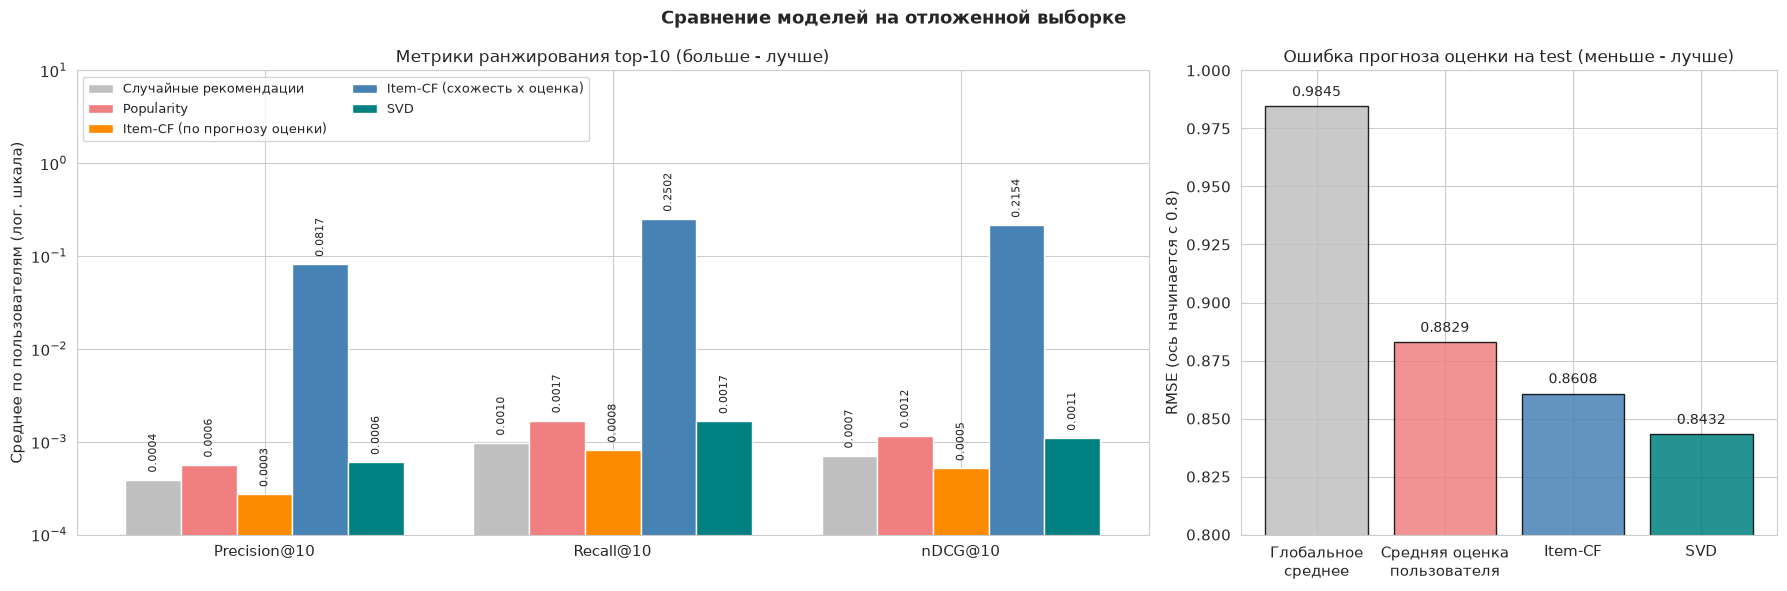

In [43]:
# Графики: метрики ранжирования top-10 и RMSE прогноза оценки
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [2, 1]})

# 1. Precision@10, Recall@10, nDCG@10 для всех моделей
metric_columns = ['Precision@10', 'Recall@10', 'nDCG@10']
model_colors = ['silver', 'lightcoral', 'darkorange', 'steelblue', 'teal']
x_positions = np.arange(len(metric_columns))
bar_width = 0.16
for model_index, model_name in enumerate(model_names):
    values = summary_table.loc[model_name, metric_columns].values.astype(float)
    offsets = x_positions + (model_index - 2) * bar_width
    axes[0].bar(offsets, values, width=bar_width, color=model_colors[model_index],
                edgecolor='white', label=model_name)
    for offset, value in zip(offsets, values):
        axes[0].text(offset, value * 1.2, f'{value:.4f}', ha='center', va='bottom',
                     fontsize=8, rotation=90)
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(metric_columns)
# Значения отличаются в сотни раз, поэтому шкала по Y логарифмическая: иначе столбики слабых моделей не видны
axes[0].set_yscale('log')
axes[0].set_ylim(1e-4, 10)
axes[0].set_ylabel('Среднее по пользователям (лог. шкала)')
axes[0].set_title('Метрики ранжирования top-10 (больше - лучше)', fontsize=12)
axes[0].legend(fontsize=9, loc='upper left', ncol=2)

# 2. RMSE прогноза оценки
rmse_labels = ['Глобальное\nсреднее', 'Средняя оценка\nпользователя', 'Item-CF', 'SVD']
rmse_values = [rmse_global_mean, rmse_user_mean, rmse_item_cf, rmse_svd]
rmse_colors = ['silver', 'lightcoral', 'steelblue', 'teal']
bars = axes[1].bar(rmse_labels, rmse_values, color=rmse_colors, edgecolor='black', alpha=0.85)
for bar, value in zip(bars, rmse_values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.003, f'{value:.4f}',
                 ha='center', va='bottom', fontsize=10)
axes[1].set_ylim(0.8, 1.0)
axes[1].set_ylabel('RMSE (ось начинается с 0.8)')
axes[1].set_title('Ошибка прогноза оценки на test (меньше - лучше)', fontsize=12)

plt.suptitle('Сравнение моделей на отложенной выборке', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eval_models_comparison.png'), dpi=100, bbox_inches='tight')
plt.show()

И последняя проверка: как качество зависит от длины истории пользователя. Это пригодится для гибридной схемы на этапе 6.

In [44]:
# nDCG@10 по группам пользователей с разной длиной истории в train
ndcg_10_by_user = user_metrics[user_metrics['k'] == 10].pivot(index='user_id', columns='model', values='ndcg')
history_groups = pd.cut(train_counts.loc[ndcg_10_by_user.index], bins=[0, 4, 9, 19, 49, 200],
                        labels=['1-4', '5-9', '10-19', '20-49', '50+'])

ndcg_by_group = ndcg_10_by_user.groupby(history_groups, observed=False).mean()[model_names].round(4)
ndcg_by_group.insert(0, 'Пользователей', ndcg_10_by_user.groupby(history_groups, observed=False).size())
ndcg_by_group.index.name = 'Оценок в train'

print("nDCG@10 по группам пользователей:")
display(ndcg_by_group)

nDCG@10 по группам пользователей:


model,Пользователей,Случайные рекомендации,Popularity,Item-CF (по прогнозу оценки),Item-CF (схожесть x оценка),SVD
Оценок в train,,,,,,
1-4,8188,0.0005,0.0011,0.0007,0.1929,0.0008
5-9,6627,0.0007,0.0010,0.0007,0.2177,0.0006
10-19,7889,0.0006,0.0013,0.0002,0.2174,0.0012
20-49,8175,0.0007,0.0013,0.0003,0.2200,0.0012
50+,3409,0.0013,0.0009,0.0011,0.2489,0.0022


#### Лучшая модель для рекомендаций - Item-CF с сортировкой по сумме "схожесть x оценка"

**Что показывает таблица:**
- **Item-CF (схожесть x оценка)** - безусловный лидер по всем метрикам ранжирования: Precision@10 = 0.082, Recall@10 = 0.250, nDCG@10 = 0.215. По nDCG@10 это примерно в 300 раз лучше случайных рекомендаций. 47% пользователей получают в top-10 хотя бы одну книгу, которую они действительно прочитали и оценили на 4 или 5, а в среднем в top-10 попадает четверть понравившихся пользователю книг из test.
- **SVD и Popularity** почти не отличаются от случайных рекомендаций: nDCG@10 около 0.001, примерно в 1.6 раза лучше случайного, но в 180-200 раз хуже Item-CF. Разница со случайными около трёх стандартных ошибок, то есть она скорее не случайна, но практического смысла в ней нет.
- **Item-CF по прогнозу оценки** на уровне случайного (0.0005 против 0.0007, разница в пределах погрешности). Модель та же, что у лидера, изменился только критерий сортировки. Значит, решает не столько модель, сколько то, по какому принципу строится список.
- **По RMSE картина обратная:** лучшая SVD (0.843), за ней Item-CF (0.861). Лучшая модель по точности прогноза оценки оказалась одной из худших по качеству рекомендаций.
- С ростом K Precision падает (0.119 при K = 5 и 0.082 при K = 10), а Recall растёт (0.193 и 0.250). Это ожидаемо: чем длиннее список, тем больше в нём попаданий, но тем меньше их доля.

**Почему так получилось:**
1. **Метрики top-N проверяют, угадала ли модель, какие книги пользователь прочитает и оценит высоко.** Сумма "схожесть x оценка" измеряет как раз силу связи книги с тем, что пользователь уже читал: продолжения серий, книги того же круга читателей (проверка в п. 5.6). А предсказанный рейтинг отвечает на другой вопрос - как пользователь оценит книгу, если её прочитает. Высокий прогноз получают книги, которые нравятся всем (у SVD это ESV Study Bible и Calvin and Hobbes, п. 4.5), или книги со случайной слабой связью с историей (Item-CF по прогнозу, п. 3.4). Но читает пользователь другие книги. У SVD дело в том, чему её учат (точная оценка), а не в самом матричном разложении (проверка в п. 5.6).
2. **Популярность в нашей выборке не работает,** потому что у всех книг почти одинаковое число оценок (потолок 100 из EDA, п. 1.5). Сигнала "эту книгу читают чаще других" в выборке почти нет, поэтому здесь не помогла бы даже популярность по числу оценок (проверка в п. 5.6). В реальных данных, где популярные книги читают в разы чаще, популярность по числу оценок давала бы гораздо больше попаданий. А сортировка по среднему рейтингу вдобавок поднимает наверх издания для узкого круга фанатов (п. 2.2).
3. **Абсолютные значения низкие у всех моделей:** у пользователя в среднем 3.8 релевантные книги среди почти 10 000 кандидатов, а непрочитанная книга по правилам офлайн-оценки считается нерелевантной.

**По группам пользователей:** Item-CF хорошо работает даже для пользователей с 1-4 оценками в train (nDCG@10 = 0.19) и лучше всего для самых активных (0.25 у 50+ оценок): чем длиннее история, тем больше похожих книг, по которым можно строить рекомендации. У остальных моделей значения на уровне случайных во всех группах.

### 5.5 Content-based в общем сравнении

По заданию метрики считаются для Popularity, Item-CF и SVD. Но сводная таблица должна охватывать все модели, поэтому добавляю и контентную. Функция `get_similar_books` ищет книги, похожие на одну книгу, а для метрик нужен список для пользователя. Строю его так:
- профиль пользователя - сумма TF-IDF векторов книг, которые он оценил в train на 4 и 5. Если таких книг нет, беру все его книги.
- кандидаты сортирую по косинусной близости с профилем, книги из train исключаю.

Протокол тот же, что в п. 5.3: те же 34 288 пользователей, порог `rating >= 4`, K = 5 и 10. Оценки других пользователей модели не нужны, схожесть считается только по названиям и тегам.

In [45]:
# Content-based в общем сравнении: top-10 по профилю пользователя из TF-IDF векторов его книг
# Строки TF-IDF матрицы идут по порядку book_id, поэтому позиция книги = book_id - 1
print(f"Позиции книг в TF-IDF совпадают с book_id - 1: {(book_position.values == np.arange(n_books)).all()}")

# Две вспомогательные матрицы пользователь x книга с единицами:
# liked_matrix - книги из train с оценкой >= порога, rated_matrix - все книги из train
liked_matrix = user_item_matrix.copy()
liked_matrix.data = (liked_matrix.data >= RELEVANCE_THRESHOLD).astype(np.float64)
liked_matrix.eliminate_zeros()
rated_matrix = user_item_matrix.copy()
rated_matrix.data[:] = 1


def recommend_content_batch(user_ids, n=TOP_K):
    # Профиль пользователя - сумма TF-IDF векторов понравившихся книг.
    # Если понравившихся книг нет, берём все книги пользователя
    rows = np.array(user_ids) - 1
    liked_rows = liked_matrix[rows]
    rated_rows = rated_matrix[rows]
    has_no_liked = (np.asarray(liked_rows.sum(axis=1)).flatten() == 0).astype(np.float64)
    profile_weights = liked_rows + diags(has_no_liked) @ rated_rows

    # Нормирую профили: тогда скалярное произведение с TF-IDF векторами книг - это косинусная близость
    profiles = normalize(profile_weights @ tfidf_matrix)
    scores = (profiles @ tfidf_matrix.T).toarray()

    # Книги из train пользователя не рекомендуем
    train_rows, train_cols = rated_rows.nonzero()
    scores[train_rows, train_cols] = -np.inf
    top_positions = np.argsort(-scores, axis=1)[:, :n]
    return top_positions + 1


# Проверка на демо-пользователе, который читает "A Series of Unfortunate Events"
print(f"Content-based top-5 для пользователя {demo_user_id}:")
for book_id in recommend_content_batch([demo_user_id], n=5)[0]:
    print(f"  {book_id:>5}: {book_info.loc[book_id, 'title']}")
print()

# Метрики для тех же пользователей, что и в п. 5.3, пачками по 1000
start_time = time.perf_counter()
content_rows = []
for batch_start in range(0, len(eval_user_ids), batch_size):
    batch_user_ids = eval_user_ids[batch_start:batch_start + batch_size]
    content_batch_top = recommend_content_batch(batch_user_ids)
    for row, user_id in enumerate(batch_user_ids):
        recommended = content_batch_top[row].tolist()
        relevant = test_relevant[user_id]
        for k in K_VALUES:
            content_rows.append({
                'user_id': user_id,
                'k': k,
                'precision': precision_at_k(recommended, relevant, k),
                'recall': recall_at_k(recommended, relevant, k),
                'ndcg': ndcg_at_k(recommended, relevant, k),
            })
content_metrics = pd.DataFrame(content_rows)
print(f"Оценено пользователей: {content_metrics['user_id'].nunique()}, время расчёта {time.perf_counter() - start_time:.0f} с")
print()

# Сводная таблица для всех моделей: таблица из п. 5.4 плюс строка Content-based
content_name = 'Content-based (профиль пользователя)'
content_means = content_metrics.groupby('k')[['precision', 'recall', 'ndcg']].mean()
content_values = {}
for k in K_VALUES:
    content_values[f'Precision@{k}'] = content_means.loc[k, 'precision']
    content_values[f'Recall@{k}'] = content_means.loc[k, 'recall']
    content_values[f'nDCG@{k}'] = content_means.loc[k, 'ndcg']
content_values['RMSE'] = np.nan

summary_table_full = summary_table.copy()
summary_table_full.loc[content_name] = pd.Series(content_values)
full_order = ['Случайные рекомендации', 'Popularity', content_name,
              'Item-CF (по прогнозу оценки)', 'Item-CF (схожесть x оценка)', 'SVD']
summary_table_full = summary_table_full.loc[full_order]
summary_table_full.index.name = 'Модель'

print("Сводная таблица метрик для всех моделей (отложенная выборка test, 34 288 пользователей):")
display(summary_table_full.round(4))

content_10 = content_metrics[content_metrics['k'] == 10]
content_ndcg_mean = content_10['ndcg'].mean()
content_ndcg_error = content_10['ndcg'].std() / np.sqrt(len(content_10))
content_hit_rate = (content_10['precision'] > 0).mean() * 100
print(f"Content-based nDCG@10: {content_ndcg_mean:.4f} +- {content_ndcg_error:.4f}, "
      f"x{content_ndcg_mean / random_ndcg_10:.1f} к случайным, hit rate {content_hit_rate:.1f}%")

Позиции книг в TF-IDF совпадают с book_id - 1: True
Content-based top-5 для пользователя 21150:
   1163: The Miserable Mill (A Series of Unfortunate Events, #4)
    356: The Bad Beginning (A Series of Unfortunate Events, #1)
   8626: Lemony Snicket: The Unauthorized Autobiography (A Series of Unfortunate Events companion)
   9461: A Series of Unfortunate Events Box: The Complete Wreck (Books 1-13)
    561: The Phantom Tollbooth



Оценено пользователей: 34288, время расчёта 49 с

Сводная таблица метрик для всех моделей (отложенная выборка test, 34 288 пользователей):


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,RMSE
Модель,,,,,,,
Случайные рекомендации,0.0004,0.0005,0.0005,0.0004,0.0010,0.0007,NaN
Popularity,0.0005,0.0009,0.0008,0.0006,0.0017,0.0012,NaN
Content-based (профиль пользователя),0.0781,0.1262,0.1312,0.0559,0.1691,0.1413,NaN
Item-CF (по прогнозу оценки),0.0003,0.0004,0.0004,0.0003,0.0008,0.0005,0.8608
Item-CF (схожесть x оценка),0.1187,0.1926,0.2039,0.0817,0.2502,0.2154,0.8608
SVD,0.0006,0.0009,0.0008,0.0006,0.0017,0.0011,0.8432


Content-based nDCG@10: 0.1413 +- 0.0014, x200.4 к случайным, hit rate 34.3%


#### Content-based - вторая модель после Item-CF

- **Content-based: Precision@10 = 0.056, Recall@10 = 0.169, nDCG@10 = 0.141.** По nDCG@10 это примерно в 200 раз лучше случайных, у 34% пользователей в top-10 есть понравившаяся книга из test. Это второе место: Item-CF по-прежнему лучше (nDCG@10 = 0.215), а SVD и Popularity отстают от контентной модели больше чем в 100 раз.
- Оценки других пользователей модели не нужны, она смотрит только на названия и теги. Сильна она потому, что в тегах есть серии, авторы и жанры: демо-пользователю она предлагает The Miserable Mill, The Bad Beginning и другие книги его серии, три из пяти книг совпадают с top-5 Item-CF из п. 3.4.
- **Для гибрида** это значит, что контентная модель полезна не только для новых книг: это второй по силе источник рекомендаций (п. 6.1).

### 5.6 Проверка объяснений

В п. 5.4 я объяснил результаты тремя причинами. Проверяю каждую на данных:
1. **Popularity** проигрывает из-за того, как собрана выборка, а не из-за сортировки по среднему рейтингу. Проверка: популярность по числу оценок.
2. **Item-CF** выигрывает за счёт продолжений серий. Проверка: какая доля её попаданий - книги из серий, которые пользователь уже читал.
3. **SVD** ранжирует плохо из-за того, чему её учат (точная оценка), а не из-за матричного разложения. Проверка: то же разложение на матрице "прочитал / не прочитал" (PureSVD, 50 факторов).

In [46]:
# Проверка трёх объяснений из п. 5.4

# 1. Популярность по числу оценок
# Сколько оценок у каждой книги в train и в test и сколько из оценок test - это 4 и 5
train_book_counts = train.groupby('book_id').size()
test_book_counts = test.groupby('book_id').size().reindex(train_book_counts.index, fill_value=0)
test_liked_counts = test[test['rating'] >= RELEVANCE_THRESHOLD].groupby('book_id').size()
test_liked_counts = test_liked_counts.reindex(train_book_counts.index, fill_value=0)
popular_top10 = popularity_table.index[:10]

print("1. Популярность")
print(f"  корреляция числа оценок книги в train и в test: {np.corrcoef(train_book_counts, test_book_counts)[0, 1]:.2f}")
print(f"  оценок в test на книгу: в среднем {test_book_counts.mean():.1f}, "
      f"у top-10 Popularity {test_book_counts.loc[popular_top10].mean():.1f}")
print(f"  из них 4 и 5:           в среднем {test_liked_counts.mean():.1f}, "
      f"у top-10 Popularity {test_liked_counts.loc[popular_top10].mean():.1f}")


def recommend_by_order(user_id, book_order, n=TOP_K):
    # Первые n книг из заданного порядка, которых нет в train пользователя
    rated_book_ids = set(user_item_matrix[user_id - 1].indices + 1)
    recommended = []
    for book_id in book_order:
        if book_id not in rated_book_ids:
            recommended.append(int(book_id))
            if len(recommended) == n:
                break
    return recommended


popularity_orders = {
    'по числу оценок в train': train_book_counts.sort_values(ascending=False, kind='stable').index.values,
    'по числу оценок на Goodreads': books.sort_values('ratings_count', ascending=False)['id'].values,
}
for order_name, book_order in popularity_orders.items():
    ndcg_values = []
    for user_id in eval_user_ids:
        recommended = recommend_by_order(user_id, book_order)
        ndcg_values.append(ndcg_at_k(recommended, test_relevant[user_id], TOP_K))
    print(f"  Popularity {order_name:<28} nDCG@10 = {np.mean(ndcg_values):.4f}")
print(f"  для сравнения: случайные {random_ndcg_10:.4f}, "
      f"Popularity по среднему рейтингу {summary_table.loc['Popularity', 'nDCG@10']:.4f}")
print()


# 2. Доля продолжений серий среди попаданий Item-CF (3000 случайных пользователей)
def get_series(title):
    # Серия указана в конце названия в скобках: "The Reptile Room (A Series of Unfortunate Events, #2)"
    if not title.endswith(')'):
        return None
    inside = title[title.rfind('(') + 1:-1]
    if '#' not in inside:
        return None
    series_name = inside.split('#')[0].strip()
    return series_name.rstrip(',').strip()


book_series = books.set_index('id')['title'].map(get_series)
series_rng = np.random.default_rng(RANDOM_STATE)
series_sample = series_rng.choice(np.array(eval_user_ids), size=3000, replace=False)

n_hits = 0
n_series_hits = 0
n_relevant_books = 0
n_relevant_series = 0
for user_id in series_sample:
    train_book_ids = user_item_matrix[user_id - 1].indices + 1
    user_series = set(book_series.loc[train_book_ids].dropna())
    item_cf_by_score, item_cf_by_predicted = recommend_item_cf(user_id)
    relevant = test_relevant[user_id]
    for book_id in relevant:
        n_relevant_books += 1
        if book_series.loc[book_id] in user_series:
            n_relevant_series += 1
    for book_id in item_cf_by_score:
        if book_id in relevant:
            n_hits += 1
            if book_series.loc[book_id] in user_series:
                n_series_hits += 1

print("2. Серии (3000 случайных пользователей)")
print(f"  книг, у которых в названии указана серия: {book_series.notna().sum()}")
print(f"  понравившиеся книги test, которые продолжают серию из train: "
      f"{n_relevant_series / n_relevant_books * 100:.1f}% ({n_relevant_series} из {n_relevant_books})")
print(f"  попадания Item-CF в top-10, которые продолжают серию из train: "
      f"{n_series_hits / n_hits * 100:.1f}% ({n_series_hits} из {n_hits})")
print()

# 3. PureSVD: разложение бинарной матрицы "прочитал / не прочитал" из train на 50 факторов
start_time = time.perf_counter()
user_factors, singular_values, book_factors = svds(rated_matrix, k=50, rng=RANDOM_STATE)
pure_svd_ndcg = []
pure_svd_hits = []
for batch_start in range(0, len(eval_user_ids), batch_size):
    batch_user_ids = eval_user_ids[batch_start:batch_start + batch_size]
    rows = np.array(batch_user_ids) - 1
    scores = (user_factors[rows] * singular_values) @ book_factors
    # Книги из train пользователя не рекомендуем
    train_rows, train_cols = rated_matrix[rows].nonzero()
    scores[train_rows, train_cols] = -np.inf
    top_positions = np.argsort(-scores, axis=1)[:, :TOP_K]
    for row, user_id in enumerate(batch_user_ids):
        recommended = (top_positions[row] + 1).tolist()
        relevant = test_relevant[user_id]
        pure_svd_ndcg.append(ndcg_at_k(recommended, relevant, TOP_K))
        pure_svd_hits.append(precision_at_k(recommended, relevant, TOP_K) > 0)

print("3. PureSVD (50 факторов, матрица 'прочитал / не прочитал')")
print(f"  nDCG@10 = {np.mean(pure_svd_ndcg):.4f}, hit rate {np.mean(pure_svd_hits) * 100:.1f}%, "
      f"время {time.perf_counter() - start_time:.0f} с")

# Для сравнения те же показатели у SVD из surprise (п. 5.3)
svd_rows_10 = user_metrics[(user_metrics['model'] == 'SVD') & (user_metrics['k'] == 10)]
svd_hit_rate = (svd_rows_10['precision'] > 0).mean() * 100
print(f"  SVD из surprise: nDCG@10 = {summary_table.loc['SVD', 'nDCG@10']:.4f}, hit rate {svd_hit_rate:.1f}%")

1. Популярность
  корреляция числа оценок книги в train и в test: -0.41
  оценок в test на книгу: в среднем 19.6, у top-10 Popularity 20.6
  из них 4 и 5:           в среднем 12.9, у top-10 Popularity 19.0


  Popularity по числу оценок в train      nDCG@10 = 0.0002


  Popularity по числу оценок на Goodreads nDCG@10 = 0.0007
  для сравнения: случайные 0.0007, Popularity по среднему рейтингу 0.0012



2. Серии (3000 случайных пользователей)
  книг, у которых в названии указана серия: 4439
  понравившиеся книги test, которые продолжают серию из train: 26.0% (2953 из 11360)
  попадания Item-CF в top-10, которые продолжают серию из train: 61.4% (1532 из 2495)



3. PureSVD (50 факторов, матрица 'прочитал / не прочитал')
  nDCG@10 = 0.0389, hit rate 13.4%, время 16 с
  SVD из surprise: nDCG@10 = 0.0011, hit rate 0.6%


#### Все три объяснения подтвердились

1. **Популярность.** По числу оценок в train она даже хуже случайных (nDCG@10 = 0.0002), по числу оценок на Goodreads - на уровне случайных (0.0007). Дело в выборке: у книги не больше 100 оценок, и чем больше их попало в train, тем меньше осталось в test (корреляция -0.41). А top-10 по среднему рейтингу попадает в test почти так же часто, как средняя книга (20.6 оценки против 19.6), но получает там 4 и 5 примерно в 1.5 раза чаще (19.0 против 12.9). Отсюда и x1.6 к случайным.
2. **Серии.** 61% попаданий Item-CF - продолжения серий, которые пользователь уже читал, хотя среди всех понравившихся книг test таких только 26%. Этим же объясняется сила контентной модели из п. 5.5: в тегах есть названия серий.
3. **SVD.** То же матричное разложение, обученное на факте чтения, даёт nDCG@10 = 0.039 и hit rate 13.4% против 0.0011 и 0.6% у SVD из surprise. Значит, SVD плохо ранжирует из-за своей цели (точная оценка), а не из-за самого разложения. Это подтверждает первое улучшение из п. 6.2: учиться на неявном фидбеке.

## 6. Гибридизация и выводы

По заданию на последнем этапе нужно предложить и обосновать гибридный подход для борьбы с холодным стартом и написать выводы по работе: какая модель показала наилучшее качество и почему, какие у каждой модели сильные и слабые стороны и как можно улучшить систему.

### 6.1 Гибридный подход для борьбы с холодным стартом

**В чём проблема.** Каждой модели нужны свои данные, и ни одна не покрывает все случаи:

| Модель | Что нужно на входе | Новый пользователь (нет оценок) | Новая книга (нет оценок) |
|---|---|---|---|
| Popularity | Оценки книги от любых пользователей | Работает, но список один для всех | Не работает |
| Content-based (TF-IDF) | Название и теги книги | Не работает без хотя бы одной книги пользователя | Работает |
| Item-CF | История пользователя и общие читатели у книг | Не работает | Не работает |
| SVD | Оценки пользователя и оценки книги | Только `mu + b_i`, то есть почти Popularity | Не работает |

В наших данных холодный старт пользователей - это 439 пользователей из test без единой оценки в train. В реальном сервисе так выглядит каждый новый пользователь и каждая новая книга.

**Предлагаемая схема.** Модель выбирается по тому, сколько данных есть о пользователе и книге:

1. **Пользователь без истории (0 оценок)** -> Popularity: других сигналов о нём просто нет. В реальном сервисе лучше сразу при регистрации попросить отметить 3-5 любимых книг: тогда пользователь перестаёт быть "холодным", и по этим книгам работают контентная модель и Item-CF. Новинки ему тоже стоит показывать, например отдавать одно место в списке популярных: так новые книги быстрее наберут первые оценки.
2. **Пользователь с историей (от 1 оценки)** -> Item-CF с сортировкой по сумме "схожесть x оценка". Это лучшая модель по всем метрикам ранжирования этапа 5, и она работает уже при 1-4 оценках в истории (nDCG@10 = 0.19 против 0.001 у Popularity и SVD). Поэтому порог для переключения - именно 0 оценок, а не 5 или 10.
3. **Новая книга без оценок** -> Content-based. Item-CF и SVD такую книгу не видят, а по названию и тегам её можно сравнить с книгами, которые пользователь оценил на 4 и 5. Это не слабая замена: по метрикам этапа 5 контентная модель вторая после Item-CF (п. 5.5). Самой похожей новой книге отдаю одно место в списке, пока у неё не накопятся оценки и она не попадёт в Item-CF. Но только если её схожесть с историей пользователя не меньше 0.2: далёкая новинка только испортит список, и тогда место остаётся за Item-CF.
4. **SVD** -> прогноз оценки. На этапе 5 сортировка по прогнозу SVD оказалась на уровне случайной, зато прогноз оценки у неё самый точный (RMSE 0.843). Поэтому SVD показывает пользователю ожидаемую оценку рекомендованной книги ("скорее всего, вы оцените на 4.2").

В задании приведён пример "для новых книг - контентные рекомендации, а для известных - SVD". Контентную часть я оставляю как в примере, а для известных книг вместо SVD беру Item-CF: на наших данных она примерно в 200 раз лучше по качеству ранжирования (nDCG@10 0.215 против 0.0011). SVD при этом не выбрасываю, а использую там, где она сильнее всех.

Ниже - минимальная реализация этой схемы, чтобы показать, как она работает.

In [47]:
# Гибридные рекомендации: модель выбирается по тому, сколько данных есть о пользователе и книгах
HYBRID_NEW_BOOK_SLOTS = 1       # сколько мест в списке отдаём новым книгам без оценок
HYBRID_MIN_SIMILARITY = 0.2     # новую книгу показываем, только если она достаточно похожа на историю пользователя


def recommend_new_books_by_content(user_id, new_book_ids, n):
    # Новые книги сравниваем по TF-IDF профилю с книгами, которые пользователь оценил на 4 и 5
    user_row = user_item_matrix[user_id - 1]
    liked_book_ids = user_row.indices[user_row.data >= RELEVANCE_THRESHOLD] + 1
    if len(liked_book_ids) == 0:
        # Если высоких оценок нет, берём все книги пользователя
        liked_book_ids = user_row.indices + 1

    liked_positions = book_position[liked_book_ids].values
    new_positions = book_position[new_book_ids].values

    # Для каждой новой книги - самая большая схожесть с одной из понравившихся книг
    similarities = cosine_similarity(tfidf_matrix[new_positions], tfidf_matrix[liked_positions])
    best_similarity = similarities.max(axis=1)
    best_liked_index = similarities.argmax(axis=1)

    result = pd.DataFrame({
        'book_id': new_book_ids,
        'title': book_info.loc[new_book_ids, 'title'].values,
        'content_similarity': best_similarity.round(3),
        'most_similar_liked_book': book_info.loc[liked_book_ids[best_liked_index], 'title'].values,
    })
    result = result.sort_values('content_similarity', ascending=False).head(n)
    return result.reset_index(drop=True)


def get_hybrid_recommendations(user_id, N=5, new_book_ids=None):
    if new_book_ids is None:
        new_book_ids = []

    # 1. Пользователя нет в train: истории нет, берём популярные книги
    if user_id not in train_users:
        result = get_popular_books(N)[['book_id', 'title']].copy()
        result['source'] = 'Popularity (нет истории)'
    else:
        # 2. Новые книги: подбираем по содержанию, но слишком далёкие от истории пользователя не показываем
        new_part = pd.DataFrame(columns=['book_id', 'title', 'content_similarity'])
        if len(new_book_ids) > 0:
            new_part = recommend_new_books_by_content(user_id, new_book_ids, HYBRID_NEW_BOOK_SLOTS)
            new_part = new_part[new_part['content_similarity'] >= HYBRID_MIN_SIMILARITY]
        n_item_cf = N - len(new_part)

        # 3. Основа списка - Item-CF (лучшая модель по метрикам этапа 5).
        # Новые книги без оценок Item-CF знать не может, поэтому убираем их из её списка
        item_cf_part = get_item_cf_recommendations(user_id, N=n_item_cf + len(new_book_ids))
        item_cf_part = item_cf_part[~item_cf_part['book_id'].isin(new_book_ids)].head(n_item_cf)
        # После фильтрации нумерация строк идёт с пропусками, поэтому сбрасываю её
        result = item_cf_part[['book_id', 'title']].reset_index(drop=True)
        result['source'] = 'Item-CF'

        # Новые книги ставим в конец списка
        if len(new_part) > 0:
            new_part = new_part[['book_id', 'title']].copy()
            new_part['source'] = 'Content-based (новая книга)'
            result = pd.concat([result, new_part], ignore_index=True)

    # 4. SVD показывает ожидаемую оценку. Для новой книги у SVD данных нет
    expected_ratings = []
    for index in range(len(result)):
        if result.loc[index, 'source'] == 'Content-based (новая книга)':
            expected_ratings.append(np.nan)
        else:
            expected_ratings.append(round(svd_model.predict(user_id, result.loc[index, 'book_id']).est, 2))
    result['svd_expected_rating'] = expected_ratings
    return result


print("Сколько пользователей попадает в каждую ветку гибрида:")
print(f"  нет истории в train -> Popularity: {(ratings_per_user == 0).sum()}")
print(f"  есть история        -> Item-CF:    {(ratings_per_user > 0).sum()}")

Сколько пользователей попадает в каждую ветку гибрида:
  нет истории в train -> Popularity: 439
  есть история        -> Item-CF:    52985


Проверяю схему на двух пользователях. Чтобы показать холодный старт книг, представлю, что в каталог только что добавили 5 книг и оценок у них ещё нет. Среди них The Bad Beginning - первая книга серии "A Series of Unfortunate Events", которую читает демо-пользователь 21150.

In [48]:
# Представим, что эти 5 книг только что появились в каталоге и оценок у них ещё нет
new_book_ids = [1, 30, 356, 619, 2205]
print("Новые книги:")
for new_book_id in new_book_ids:
    print(f"  {new_book_id:>5}: {book_info.loc[new_book_id, 'title']}")
print()

print(f"Пользователь {demo_user_id} (есть история в train):")
display(get_hybrid_recommendations(demo_user_id, N=5, new_book_ids=new_book_ids))

print("Как подобралась новая книга: схожесть по содержанию с книгами, которые пользователь оценил на 4 и 5")
display(recommend_new_books_by_content(demo_user_id, new_book_ids, n=5))

print(f"Пользователь {cold_user_id} (нет истории в train):")
display(get_hybrid_recommendations(cold_user_id, N=5, new_book_ids=new_book_ids))

# Порог схожести: если новинки далеки от истории пользователя, все места остаются за Item-CF
far_new_book_ids = [30, 2205]
far_similarity = recommend_new_books_by_content(demo_user_id, far_new_book_ids, n=1)['content_similarity'].iloc[0]
far_result = get_hybrid_recommendations(demo_user_id, N=5, new_book_ids=far_new_book_ids)
print(f"Пользователь {demo_user_id}, новинки только Gone Girl и Sapiens: лучшая схожесть {far_similarity:.3f}, "
      f"порог {HYBRID_MIN_SIMILARITY}")
print(f"  источники рекомендаций: {far_result['source'].tolist()}")

Новые книги:
      1: The Hunger Games (The Hunger Games, #1)
     30: Gone Girl
    356: The Bad Beginning (A Series of Unfortunate Events, #1)
    619: Thinking, Fast and Slow
   2205: Sapiens: A Brief History of Humankind

Пользователь 21150 (есть история в train):


,book_id,title,source,svd_expected_rating
0,1163,The Miserable Mill (A Series of Unfortunate Ev...,Item-CF,4.20
1,1662,Fantastic Mr. Fox,Item-CF,4.34
2,8626,Lemony Snicket: The Unauthorized Autobiography...,Item-CF,3.93
3,2007,The Thief Lord,Item-CF,4.12
4,356,The Bad Beginning (A Series of Unfortunate Eve...,Content-based (новая книга),NaN


Как подобралась новая книга: схожесть по содержанию с книгами, которые пользователь оценил на 4 и 5


,book_id,title,content_similarity,most_similar_liked_book
0,356,The Bad Beginning (A Series of Unfortunate Eve...,0.619,The Reptile Room (A Series of Unfortunate Even...
1,1,"The Hunger Games (The Hunger Games, #1)",0.309,"Gathering Blue (The Giver, #2)"
2,619,"Thinking, Fast and Slow",0.179,Man and His Symbols
3,30,Gone Girl,0.103,"Full Dark, No Stars"
4,2205,Sapiens: A Brief History of Humankind,0.099,The Hot Zone: The Terrifying True Story of the...


Пользователь 45 (нет истории в train):


,book_id,title,source,svd_expected_rating
0,7947,ESV Study Bible,Popularity (нет истории),4.81
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Popularity (нет истории),4.82
2,9566,Attack of the Deranged Mutant Killer Monster S...,Popularity (нет истории),4.79
3,8978,The Revenge of the Baby-Sat,Popularity (нет истории),4.73
4,6920,The Indispensable Calvin and Hobbes,Popularity (нет истории),4.78


Пользователь 21150, новинки только Gone Girl и Sapiens: лучшая схожесть 0.103, порог 0.2
  источники рекомендаций: ['Item-CF', 'Item-CF', 'Item-CF', 'Item-CF', 'Item-CF']


#### Гибрид закрывает оба вида холодного старта

- **Пользователь с историей** получает 4 книги от Item-CF и одну новую книгу от контентной модели. Из пяти "новинок" контентная модель выбрала The Bad Beginning, то есть книгу из той серии, которую он читает: схожесть 0.62 с The Reptile Room из его истории. При этом у этой книги в нашем сценарии нет ни одной оценки, и связь найдена только по названию и тегам. Остальные новинки по содержанию заметно дальше от его истории: The Hunger Games 0.31, научпоп и Gone Girl 0.10-0.18. Отсюда и порог 0.2: если оставить только Gone Girl и Sapiens, порог их не пропускает, и все 5 мест получает Item-CF.
- **Пользователь без истории** получает список популярных книг. Других данных о нём нет, и это честный запасной вариант. Но на этапе 5 Popularity в нашей выборке была почти на уровне случайной, поэтому для нового пользователя важнее всего быстрее получить первые сигналы, например попросить отметить несколько любимых книг при регистрации.
- **SVD** добавляет к каждой рекомендации ожидаемую оценку. Для новой книги её нет, потому что у SVD нет данных об этой книге.

### 6.2 Выводы по работе

#### Какая модель показала наилучшее качество и почему

**Для рекомендаций лучшая модель - Item-CF с сортировкой по сумме "схожесть x оценка":** Precision@10 = 0.082, Recall@10 = 0.250, nDCG@10 = 0.215. По nDCG@10 это примерно в 300 раз лучше случайных рекомендаций, и у 47% пользователей в top-10 есть хотя бы одна книга, которую они прочитали и оценили на 4 или 5. Модель работает уже для пользователей с 1-4 оценками (nDCG@10 = 0.19). Второе место у Content-based по профилю пользователя (nDCG@10 = 0.141, п. 5.5).

Почему: метрики top-N на отложенной выборке проверяют, угадала ли модель, какие книги пользователь прочитает и оценит высоко. Item-CF по сумме схожестей как раз ищет книги, которые сильнее всего связаны с историей пользователя через общих читателей: продолжения серий, книги того же круга. Это прямой сигнал "что этот человек будет читать": 61% попаданий Item-CF - продолжения серий из истории пользователя (п. 5.6).

**Для прогноза оценки лучшая модель - SVD:** RMSE 0.843 против 0.861 у Item-CF, 0.883 у средней оценки пользователя и 0.985 у глобального среднего. Она учит смещения пользователя и книги вместе со скрытыми факторами и обобщает даже там, где у книг нет общих читателей.

**Главный вывод работы: точный прогноз оценки не означает хорошие рекомендации.** SVD с лучшим RMSE и Item-CF с сортировкой по прогнозу оценки ранжируют на уровне случайных рекомендаций. Сортировка по прогнозу поднимает наверх книги, которые нравятся всем (SVD: Calvin and Hobbes, ESV Study Bible), или книги со случайной слабой связью с историей (Item-CF по прогнозу). Дело не в матричном разложении: то же разложение, обученное на факте чтения (PureSVD), даёт nDCG@10 = 0.039 (п. 5.6). Значит, модель и критерий сортировки нужно выбирать под задачу, а задача рекомендательного сервиса - ранжирование.

Часть результатов объясняется особенностями данных, и это стоит держать в голове:
- В версии датасета с Kaggle у книги не больше 100 оценок, поэтому сигнал популярности стёрт: Popularity работает почти как случайные рекомендации, даже если считать популярность по числу оценок (п. 5.6).
- Разбиение случайное, потому что времени в данных нет. Модель видит часть "будущих" оценок пользователя, а в реальном сервисе предсказывать придётся только вперёд по времени.
- В офлайн-оценке непрочитанная книга считается нерелевантной, поэтому абсолютные значения метрик занижены у всех моделей.

#### Сильные и слабые стороны моделей

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| **Popularity** (средний рейтинг, порог 50 оценок) | Самая простая и быстрая. Не нужна история пользователя, поэтому это единственный вариант для нового пользователя. Список легко объяснить | Один список для всех, без персонализации. Сортировка по среднему поднимает наверх издания для фанатов (Calvin and Hobbes, подарочные Harry Potter). На нашей выборке почти как случайные рекомендации (nDCG@10 = 0.0012) |
| **Content-based** (TF-IDF по названию и тегам) | Второе место по ранжированию: по профилю пользователя nDCG@10 = 0.141. Не нужны оценки, поэтому работает для новых книг. Хорошо находит книги той же серии, автора и жанра (Harry Potter, Гиллиан Флинн, научпоп о психологии). Рекомендации легко объяснить совпавшими тегами | Рекомендует "ещё того же", почти без новизны. Качество зависит от тегов, а в них остаётся шум (`re_reading`, `rereads`). Пользователю без единой книги в истории ничего предложить не может |
| **Item-CF** | Лучшее качество рекомендаций: nDCG@10 = 0.215, в 300 раз лучше случайных. Работает уже при 1-4 оценках в истории. Рекомендацию можно объяснить: "потому что вы читали X". RMSE 0.861 лучше простых бейзлайнов | Память `O(n^2)` под схожести и квадратичный рост работы от активности пользователей. У 81.7% пар книг нет общих читателей. Не работает для новых пользователей и книг. Соседи смещены к популярным книгам (Harry Potter -> The Great Gatsby). Прогноз оценки сжат к среднему, и сортировать по нему нельзя |
| **SVD** | Лучший прогноз оценки (RMSE 0.843). Масштабируется: обучение 10 с, модель 48 МБ, рост линейный по числу оценок. Обобщает через скрытые факторы, даже если у книг нет общих читателей | Top-N по предсказанному рейтингу почти случайный (nDCG@10 = 0.0011): порядок задаёт в основном смещение книги `b_i`, и половина top-10 совпадает с неперсональным списком. При короткой истории персональная часть выучивается слабо. Не работает для новых книг, для нового пользователя даёт только `mu + b_i`. Скрытые факторы трудно объяснить |

#### Как можно улучшить систему

**Модели и ранжирование**
1. **Учиться на неявном фидбеке и сразу оптимизировать ранжирование.** Этап 5 показал, что главный сигнал - сам факт чтения. Модели вроде ALS или BPR (библиотеки implicit, LightFM) обучаются на матрице "прочитал / не прочитал" и оптимизируют порядок списка, а не RMSE. Даже простое разложение такой матрицы (PureSVD, п. 5.6) ранжирует примерно в 35 раз лучше SVD из surprise.
2. **SVD++** вместо SVD: эта модель учитывает не только значения оценок, но и то, какие книги пользователь вообще оценивал, то есть тот самый сигнал чтения.
3. **Улучшить score Item-CF:** сейчас в сумму "схожесть x оценка" входят и книги с оценками 1-2, поэтому их соседи тоже поднимаются вверх. Если брать только понравившиеся книги или вычитать из оценки среднюю оценку пользователя, нелюбимые книги перестанут тянуть за собой похожие.
4. **Двухэтапная схема:** Item-CF быстро отбирает 100-200 кандидатов, а модель learning-to-rank (например, LightGBM) переранжирует их по признакам: сумма схожестей Item-CF, прогноз SVD, контентная схожесть, популярность книги, активность пользователя. Так сильные стороны моделей складываются, а не выбирается одна.
5. **Нейросетевые подходы:** NCF, two-tower модели, а при наличии порядка оценок - последовательные модели (SASRec, BERT4Rec), которые учитывают, что пользователь читал последним.
6. **Подбор гиперпараметров** (K в Item-CF, число факторов и регуляризация SVD) на валидационной части train, а не на test.

**Данные и признаки**
7. **Эмбеддинги текста вместо TF-IDF:** Word2Vec или BERT (например, sentence-transformers) по названиям, описаниям и тегам. Они понимают смысл и синонимы (`ya` и `young-adult`), а TF-IDF сравнивает только совпадающие слова.
8. **Очистка тегов:** убирать служебные полки не ручным списком, а по шаблону в названии (`read`, `own`, `fav`, `tbr`, `kindle` и т.п.): список из топ-150 пропускает `reread`, `read-more-than-once`, `favorite-series` и похожие полки (п. 2.3). Объединять синонимы, учитывать `count` тега как вес.
9. **Файл `to_read.csv`** (912 705 пар "хочу прочитать") - готовый неявный сигнал, который в этой работе не использовался. Он особенно полезен для пользователей с короткой историей.
10. **Признаки пользователей:** любимые жанры по тегам прочитанных книг, средняя оценка (насколько пользователь строгий), активность. При регистрации - выбор нескольких любимых книг для холодного старта.

**Качество рекомендаций и оценка**
11. **Разнообразие и новизна:** Item-CF и контентная модель склонны рекомендовать "ещё того же" и популярные книги. Можно переранжировать список с учётом разнообразия (например, MMR) и контролировать смещение популярности.
12. **Полная версия датасета (6 млн оценок) и временное разбиение:** это честнее имитирует реальный сервис, где модель предсказывает только будущие оценки.
13. **Онлайн-проверка (A/B тест):** офлайн-метрики занижены, потому что непрочитанная книга считается нерелевантной. Реальный эффект рекомендаций видно только на живых пользователях.
14. **Масштабирование Item-CF** для большого каталога: хранить только top-K соседей книги и искать их приближённо (п. 3.5).

### 6.3 Что было сделано

1. **EDA:** разобраны 979 478 оценок 53 424 пользователей по 10 000 книгам. Удалены дубликаты и аномалии. Найдены главные проблемы данных: разреженность 99.8%, смещение оценок вверх (66% оценок - 4 и 5), холодный старт (у трети пользователей меньше 5 оценок), длинный хвост популярности на Goodreads и потолок в 100 оценок на книгу в нашей выборке, шум в тегах.
2. **Бейзлайны:** общее случайное разбиение 80/20 для всех моделей. Popularity по среднему рейтингу с порогом 50 оценок. Контентная модель на TF-IDF по названию и тегам с функцией `get_similar_books(book_id, N=5)`.
3. **Item-based CF:** разреженная матрица пользователь x книга, косинусная матрица схожестей книг, прогноз оценки по K = 20 похожим книгам, top-N по сумме "схожесть x оценка". Разобраны вычислительная сложность, способы оптимизации и ограничения метода.
4. **SVD:** обучение в `surprise`, RMSE 0.843 на test, функция `get_recommendations(user_id, N=5)` и анализ того, насколько персональны её рекомендации.
5. **Сравнение:** свои реализации Precision@K, Recall@K и nDCG@K, проверенные на игрушечном примере. Метрики всех моделей, включая Content-based, посчитаны на 34 288 пользователях и собраны в сводную таблицу. Объяснения результатов проверены отдельно: популярность по числу оценок, доля продолжений серий, PureSVD.
6. **Гибрид и выводы:** схема "нет истории -> Popularity, есть история -> Item-CF, новая книга -> Content-based (с порогом схожести), ожидаемая оценка -> SVD", её минимальная реализация и итоговые выводы.

Лучшее качество рекомендаций показала Item-CF с сортировкой по сумме "схожесть x оценка", а лучший прогноз оценки - SVD. Главный урок, который я извлёк из этой работы: модель и критерий ранжирования нужно выбирать под задачу, а не по одной метрике точности прогноза.